In [1]:
# =============================================================================
#  [0.1] SETUP — Imports et configuration
#  ---------------------------------------------------------------------------
#  Objet    : Charger toutes les bibliothèques et configurer l'environnement
#  Entrées  : —
#  Sorties  : modules, dossiers results/ et figures/
#  Durée    : ~5 s
# =============================================================================

import importlib.util
import sys
import os
import json
import pickle
import warnings
from datetime import datetime
from importlib.metadata import version as _pkg_version

# ─── Installation conditionnelle de sequence-jacobian ───
if importlib.util.find_spec('sequence_jacobian') is None:
    print("sequence-jacobian absent → installation...")
    !pip install sequence-jacobian -q

# ─── Bibliothèques standards ───
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq
from scipy.linalg import toeplitz

# ─── Sequence-jacobian ───
import sequence_jacobian as sj
from sequence_jacobian import (
    simple, solved, combine, create_model, grids, interpolate
)
from sequence_jacobian.examples.two_asset import (
    dividend, share_value, finance, wage, union,
    partial_ss, union_ss
)
from sequence_jacobian.blocks.het_block import het
from numba import guvectorize

# ─── Configuration ───
warnings.filterwarnings('ignore')
np.random.seed(42)
plt.rcParams.update({
    'font.size': 11,
    'axes.titlesize': 12,
    'axes.labelsize': 11,
    'axes.titleweight': 'bold',
    'axes.labelweight': 'bold',
    'figure.dpi': 100,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
})

os.makedirs('results', exist_ok=True)
os.makedirs('figures', exist_ok=True)

# ─── Helper ───
def _ver(pkg):
    """Retourne la version du package, ou '?' si indisponible."""
    try:
        return _pkg_version(pkg)
    except Exception:
        return '?'

# ─── Bannière ───
print("=" * 78)
print("  Φ PROJECT — Stabilisateur automatique ciblé sur la demande solvable")
print("=" * 78)
print(f"  Session           : {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")
print(f"  Répertoire        : {os.getcwd()}")
print(f"  Python            : {sys.version.split()[0]}")
print(f"  sequence-jacobian : {_ver('sequence-jacobian')}")
print(f"  numpy             : {np.__version__}")
print(f"  pandas            : {pd.__version__}")
print(f"  scipy             : {_ver('scipy')}")
print(f"  numba             : {_ver('numba')}")
print(f"  matplotlib        : {_ver('matplotlib')}")
print("=" * 78)

# ─── Sanity checks (bornes larges) ───
assert 'sj' in dir(), "sequence-jacobian non importé"
assert 'het' in dir(), "het_block non importé"
assert os.path.isdir('results'), "results/ non créé"
assert os.path.isdir('figures'), "figures/ non créé"

print("✅ [0.1] Setup OK.")

sequence-jacobian absent → installation...
  Φ PROJECT — Stabilisateur automatique ciblé sur la demande solvable
  Session           : 2026-10-31 17:25:16
  Répertoire        : /content
  Python            : 3.13.18
  sequence-jacobian : 1.0.0
  numpy             : 2.1.3
  pandas            : 2.2.3
  scipy             : 1.16.3
  numba             : 0.61.2
  matplotlib        : 3.10.0
✅ [0.1] Setup OK.


In [2]:
# =============================================================================
#  [0.2] PARAMÈTRES Φ
#  ---------------------------------------------------------------------------
#  Objet    : Constantes du dispositif Φ
#  Entrées  : —
#  Sorties  : PRIME_*, Phi_*, Surprime_*, NICHES, ARE_S1..S4, PIB_france
#  Durée    : < 1 s
#
#  Sources : INSEE (PIB, durée légale), PLF (niches), Cour des comptes.
#  Référence théorique : transfert ciblé type KMV (2018) pour le canal HANK.
# =============================================================================

# ─── Constantes de cadrage ───
PIB_france   = 2800.0        # Md€ — PIB annuel France
HEURES_MOIS  = 151.67        # h/mois — durée légale
NB_BENEF_PHI = 13.0e6        # bénéficiaires
TAUX_IR_PHI  = 0.10          # IR sur Φ

# ─── Composantes de la prime (€/h) ───
PRIME_BASE            = 1.00
SURPRIME_NORMALE      = 0.50
SURPRIME_VIGILANCE    = 0.25
SURPRIME_GALOPANT     = 0.00
PRIME_TOTALE_NORMALE  = PRIME_BASE + SURPRIME_NORMALE

PRIME_RECESSION_BASE   = 2.00
PRIME_RECESSION_TOTALE = PRIME_RECESSION_BASE + SURPRIME_NORMALE

def Phi_annuel(prime_totale):
    """Convertit une prime €/h en Md€/an."""
    return prime_totale * HEURES_MOIS * NB_BENEF_PHI * 12 / 1e9

# ─── Φ selon régime (Md€/an) ───
Phi_normal    = Phi_annuel(PRIME_TOTALE_NORMALE)
Phi_vigilance = Phi_annuel(PRIME_BASE + SURPRIME_VIGILANCE)
Phi_galopant  = Phi_annuel(PRIME_BASE + SURPRIME_GALOPANT)
Phi_recession = Phi_annuel(PRIME_RECESSION_TOTALE)

# ─── Surprimes ARE (Md€/an) ───
#   Logique : Φ = prime de base + surprime(π). La surprime s'éteint quand π monte.
#   L'argent non versé au titre de la surprime part au Fonds Souverain.
Surprime_plein_mds  = SURPRIME_NORMALE   * HEURES_MOIS * NB_BENEF_PHI * 12 / 1e9
Surprime_moitie_mds = SURPRIME_VIGILANCE * HEURES_MOIS * NB_BENEF_PHI * 12 / 1e9
Surprime_quart_mds  = 0.0
Surprime_zero_mds   = 0.0
Surprime_neg_mds    = -Surprime_plein_mds * 0.5

# ─── Surprimes ARE (fraction PIB, pour SJ) ───
Surprime_plein_frac  = Surprime_plein_mds  / PIB_france
Surprime_moitie_frac = Surprime_moitie_mds / PIB_france
Surprime_quart_frac  = Surprime_quart_mds  / PIB_france
Surprime_zero_frac   = Surprime_zero_mds   / PIB_france
Surprime_neg_frac    = Surprime_neg_mds    / PIB_france

# ─── Φ brut / net / référence modèle ───
#   Phi_brut_mds : versement État (base de μ)
#   Phi_net_mds  : perception ménages après IR (base du bilan)
#   Phi_star_mds : référence du choc dans les IRF (§3.1, §5.5)
Phi_brut_mds = Phi_normal
Phi_net_mds  = Phi_normal * (1 - TAUX_IR_PHI)
Phi_star_mds = Phi_brut_mds
Phi_star     = Phi_brut_mds / PIB_france

# ─── Supplément Fonds Souverain (récession) ───
Supplément_fonds = (
    (PRIME_RECESSION_BASE - PRIME_BASE)
    * HEURES_MOIS * NB_BENEF_PHI * 12 / 1e9
)

# ─── Niches fiscales redirigées vers Φ ───
#   Recette nette de 32 Md€/an (traitement exogène).
#   CIR et niches R&D explicitement préservés (cf. Cour des comptes, PLF).
NICHES = 32.0

# ─── Seuils ARE ───
ARE_S1 = 0.020
ARE_S2 = 0.035
ARE_S3 = 0.050
ARE_S4 = 0.065

#  CONSTANTES MACROÉCONOMIQUES EXOGÈNES —

POP_ACTIVE_FRANCE   = 30.5e6      # population active France (INSEE 2024)
COUT_CHOMEUR_ANNUEL = 20_000.0    # coût annuel / chômeur (UNEDIC + DARES)
COTIS_MOYEN_ETP     = 13_000.0    # cotisations sociales moyennes / ETP (INSEE/DARES)
TAUX_PO_PIB         = 0.45        # taux de prélèvements obligatoires / PIB (INSEE)
TAUX_RETOUR_FISCAL  = 0.30        # retour fiscal agrégé prudentiel (OCDE)

# ─── Sanity checks (bornes physiques) ───
assert 25e6 < POP_ACTIVE_FRANCE < 35e6, \
    f"POP_ACTIVE_FRANCE = {POP_ACTIVE_FRANCE} hors (25M, 35M)"
assert 15_000 < COUT_CHOMEUR_ANNUEL < 25_000, \
    f"COUT_CHOMEUR_ANNUEL = {COUT_CHOMEUR_ANNUEL} hors (15k, 25k)"
assert 10_000 < COTIS_MOYEN_ETP < 15_000, \
    f"COTIS_MOYEN_ETP = {COTIS_MOYEN_ETP} hors (10k, 15k)"
assert 0.35 < TAUX_PO_PIB < 0.50, \
    f"TAUX_PO_PIB = {TAUX_PO_PIB} hors (0.35, 0.50)"
assert 0.20 < TAUX_RETOUR_FISCAL < 0.50, \
    f"TAUX_RETOUR_FISCAL = {TAUX_RETOUR_FISCAL} hors (0.20, 0.50)"


# ─── Affichage ───
print(f"  Prime de base           : {PRIME_BASE:.2f} €/h")
print(f"  Total normal            : {PRIME_TOTALE_NORMALE:.2f} €/h")
print(f"  Φ normal                : {Phi_normal:.2f} Md€/an")
print(f"  Φ brut                  : {Phi_brut_mds:.2f} Md€/an")
print(f"  Φ net (après IR)        : {Phi_net_mds:.2f} Md€/an")
print(f"  Φ star (fraction PIB)   : {Phi_star:.6f}")
print(f"  Niches redirigées       : {NICHES:.2f} Md€/an")
print(f"  POP_ACTIVE_FRANCE       : {POP_ACTIVE_FRANCE:.0f}  ({POP_ACTIVE_FRANCE/1e6:.1f} M actifs)")
print(f"  COUT_CHOMEUR_ANNUEL     : {COUT_CHOMEUR_ANNUEL:.0f} €/an/chômeur")
print(f"  COTIS_MOYEN_ETP         : {COTIS_MOYEN_ETP:.0f} €/an/ETP")
print(f"  TAUX_PO_PIB             : {TAUX_PO_PIB:.2%}")
print(f"  TAUX_RETOUR_FISCAL      : {TAUX_RETOUR_FISCAL:.2%}")
# ─── Sanity checks (bornes larges) ───
assert 30 < Phi_brut_mds < 40, f"Φ brut hors bornes : {Phi_brut_mds:.2f}"
assert 20 < NICHES < 50, f"Niches hors bornes : {NICHES}"
assert 0 < TAUX_IR_PHI < 0.5
assert 0 < Phi_star < 0.05
assert abs(Phi_star_mds - Phi_brut_mds) < 1e-10

print("✅ [0.2] Paramètres Φ définis.")

  Prime de base           : 1.00 €/h
  Total normal            : 1.50 €/h
  Φ normal                : 35.49 Md€/an
  Φ brut                  : 35.49 Md€/an
  Φ net (après IR)        : 31.94 Md€/an
  Φ star (fraction PIB)   : 0.012675
  Niches redirigées       : 32.00 Md€/an
  POP_ACTIVE_FRANCE       : 30500000  (30.5 M actifs)
  COUT_CHOMEUR_ANNUEL     : 20000 €/an/chômeur
  COTIS_MOYEN_ETP         : 13000 €/an/ETP
  TAUX_PO_PIB             : 45.00%
  TAUX_RETOUR_FISCAL      : 30.00%
✅ [0.2] Paramètres Φ définis.


In [3]:
# =============================================================================
#  [0.3] EXPECTED (source unique) + persistance
#  ---------------------------------------------------------------------------
#  Objet    : Source unique de vérité + sauvegarde / chargement
#  Entrées  : —
#  Sorties  : EXPECTED, EXPECTED_*, save_*/load_*
#  Durée    : < 1 s
#
#  Convention : EXPECTED[catégorie][clé] = (valeur_cible, tolérance)
#  Aucun chiffre attendu ne doit être écrit en dur ailleurs.
#  Seuls les CHECKPOINTS lisent EXPECTED.
#
#  Classification des valeurs :
#    - exogène : paramètre fixé (calibration), doit matcher la source
#    - endogène : calculé par le modèle, valeur du run de référence
#      (peut bouger si la calibration change, mais reste dans la tolérance)
#
#  Découpage par bloc :
#    params       : constantes Φ (0.2)
#    insee        : ratios INSEE (1.1)
#    hank_b2      : calibration HANK (calculé en 2.1 + 2.2)
#    hank_b3      : multiplicateurs + budget + caisse (calculé en 3.x)
#    two_asset    : Two-Asset (calculé en 4.x + 5.x)
#    are          : Φ(π) aux points clés (0.4)
# =============================================================================

EXPECTED = {
    # ─── Constantes Φ (0.2) ───
    # Toutes exogènes (formules de 0.2).
    'params': {
        'Phi_brut_mds':         (35.49,    0.05),
        'Phi_net_mds':          (31.94,    0.05),
        'Phi_star':             (0.012675, 1e-5),
        'NICHES':               (32.00,    0.10),
        'PRIME_TOTALE_NORMALE': (1.50,     1e-6),
        'Phi_vigilance':        (29.58,    0.10),
        'Phi_galopant':         (23.66,    0.10),
        'Phi_recession':        (59.15,    0.10),

    # ─── Constantes macroéconomiques exogènes (0.2) ───
        'POP_ACTIVE_FRANCE':    (30.5e6, 1e5),      # INSEE 2024
        'COUT_CHOMEUR_ANNUEL':  (20_000, 500),      # UNEDIC/DARES
        'COTIS_MOYEN_ETP':      (13_000, 500),      # INSEE/DARES
        'TAUX_PO_PIB':          (0.45, 0.01),       # INSEE
        'TAUX_RETOUR_FISCAL':   (0.30, 0.02),       # OCDE

        },

    # ─── INSEE Comptes nationaux 2024 T3 (1.1) ───
    # Tous exogènes (données comptables).
    'insee': {
        'part_C_INSEE':         (0.506,  0.005),
        'part_I_INSEE':         (0.216,  0.005),
        'part_M_INSEE':         (0.314,  0.005),
        'part_X_INSEE':         (0.318,  0.005),
    },

    # ─── HANK Bloc 2 — calibration (calculé en 2.1 + 2.2) ───
    # Sources : CepreHANK (β*), INSEE (λ_HtM, MPC).
    'hank_b2': {
        'beta_0':               (0.9862,  0.005),   # endogène (solver)
        'frac_htM_abs':         (0.2694,  0.010),   # endogène (mesure)
        'frac_htM_kv':          (0.3750,  0.020),   # endogène (mesure)
        'MPC_agreg':            (0.2028,  0.020),   # endogène (mesure)
        'PMC_beneficiaires':    (0.7817,  0.020),   # endogène (mesure)
    },

    # ─── HANK Bloc 3 — multiplicateurs, budget, caisse ───
    # Toutes endogènes (calculées en 3.1 → 3.10).
    'hank_b3': {
        # Multiplicateurs
        'mu_8T':                (0.775,   0.005),
        'mu_32T':               (0.803,   0.005),
        'mu_taylor_05':         (0.644,   0.005),
        'mu_taylor_15':         (0.477,   0.005),
        'mu_ouvert':            (0.532,   0.005),
        'mu_impact':            (0.7776,  0.005),
        # Bilan État
        'solde_central':        (9.75,    0.10),
        'solde_min':            (7.41,    0.10),
        'solde_max':            (12.09,   0.10),
        'delta_Y_endogene':     (27.51,   0.10),
        # Baisse de charges + solde total
        'solde_total':          (9.42,    0.10),
        'bc_c':                 (9.75,    0.10),
        'emplois_bc_final':     (294.0,   5.0),
        'emplois_phi':          (75.1,    2.0),
        # Caisse Φ
        'deficit_max_caisse':   (-16.94,  0.50),
        'breakeven_mois':       (25,      2),
        'surplus_annuel_caisse':(16.26,   1.00),
        # Inflation
        'pi_max':               (0.1971,  0.02),
    },

    # ─── Two-Asset (Bloc 4-5) ───
    # Sources : INSEE T305 2023 (u_court, u_long), KMV 2018 (chi0_sell),
    # run de référence v18 pour les endogènes.
    'two_asset': {
        # Exogènes (paramètres fixés)
        'Phi_target':           (0.0351,  0.001),   # exogène (cible)
        'u_court_ss':           (0.0563,  0.010),   # exogène (INSEE T305)
        'u_long_ss':            (0.0185,  0.008),   # exogène (INSEE T305)

        # Endogènes SS (calculés en 5.1 + 5.2)
        'beta':                 (0.9924,  0.001),   # endogène (solver)
        'chi1':                 (14.9993, 0.50),    # endogène (solver)
        'N':                    (0.9998,  0.001),   # endogène (normalisation)
        'Y':                    (1.0000,  0.001),   # endogène (normalisation)
        'w':                    (0.7258,  0.005),   # endogène (SS)
        'p':                    (14.8300, 0.05),    # endogène (SS)
        'h':                    (0.9999,  0.001),   # endogène (SS)
        'seuil_phi':            (0.6631,  0.001),   # endogène (boucle 5.1)
        'lambda_htM':           (0.2609,  0.020),   # endogène (mesure HtM)
        'n_htm_ss':             (0.3238,  0.010),   # endogène (boucle 5.1)
        'part_CLD':             (0.2473,  0.050),   # endogène (dérivé)

        # Endogènes GE 5 modes (calculés en 5.5a — χ0=0.10)
        'mu_lump_kink':         (0.0438,  0.050),
        'mu_niches_kink':       (0.1990,  0.050),
        'mu_broad_kink':        (0.2367,  0.050),
        'mu_niches_no_kink':    (0.1935,  0.050),
        'mu_lump_no_kink':      (-0.0784, 0.050),

        # Endogènes sensibilité (calculés en 5.7 — χ0=0.20)
        'mu_lump_020':          (-0.0696, 0.050),
        'mu_niches_020':        (+0.2071, 0.050),
        'mu_broad_020':         (+0.2817, 0.050),
    },

    # ─── ARE — Φ(π) aux points clés (0.4) ───
    # Exogènes (formules de 0.4 via phi_are).
    'are': {
        # Formule : phi_are(π) = Phi_galopant + sp(π)
        'phi_at_0':             (35.49,   0.10),
        'phi_at_5pct':          (23.66,   0.10),
        'phi_at_8pct':          (17.745,  0.01),
    },
}

# ═══════════════════════════════════════════════════════════════════════════
#  ALIASES PLATS
# ═══════════════════════════════════════════════════════════════════════════
EXPECTED_PARAMS     = EXPECTED['params']
EXPECTED_INSEE      = EXPECTED['insee']
EXPECTED_HANK_B2    = EXPECTED['hank_b2']
EXPECTED_HANK_B3    = EXPECTED['hank_b3']
EXPECTED_HANK       = {**EXPECTED['hank_b2'], **EXPECTED['hank_b3']}  # union
EXPECTED_TWO_ASSET  = EXPECTED['two_asset']
EXPECTED_ARE        = EXPECTED['are']


# ═══════════════════════════════════════════════════════════════════════════
#  VALIDATION INTERNE (picklabilité)
# ═══════════════════════════════════════════════════════════════════════════
def _validate_picklable(obj, path='root'):
    """Refuse les objets sequence-jacobian (non picklables)."""
    forbidden = ['Jacobian', 'SteadyState', 'ImpulseDict', 'Block',
                 'Model', 'HetBlock', 'SimpleBlock', 'SolvedBlock',
                 'CombinedBlock', 'HetOutput']
    t = type(obj).__name__
    if any(f in t for f in forbidden):
        raise TypeError(
            f"Objet '{t}' à '{path}' non picklable (sequence-jacobian). "
            f"Extraire les scalaires et arrays avant save."
        )
    if callable(obj) and not isinstance(obj, type):
        raise TypeError(
            f"Fonction à '{path}' ({t}) non picklable. "
            f"Redéfinir la fonction dans le notebook d'analyse."
        )
    return True


def _check_picklable_recursive(d, path='root'):
    _validate_picklable(d, path)
    if isinstance(d, dict):
        for k, v in d.items():
            _check_picklable_recursive(v, f"{path}.{k}")
    elif isinstance(d, (list, tuple)):
        for i, v in enumerate(d):
            _check_picklable_recursive(v, f"{path}[{i}]")


# ═══════════════════════════════════════════════════════════════════════════
#  SAUVEGARDE
# ═══════════════════════════════════════════════════════════════════════════
def _save(results, filename, model_name):
    """Sauvegarde un dict de résultats + un audit JSON lisible."""
    _check_picklable_recursive(results, path=model_name)

    os.makedirs('results', exist_ok=True)
    full = os.path.join('results', filename)
    with open(full, 'wb') as f:
        pickle.dump(results, f, protocol=4)

    audit = {
        'version':  results.get('_meta', {}).get('version', 'unknown'),
        'date':     results.get('_meta', {}).get('date', 'unknown'),
        'model':    model_name,
        'critical': dict(results.get('critical', {})),
        'n_keys':   len(results),
    }
    audit_path = full.replace('.pkl', '_audit.json')
    with open(audit_path, 'w', encoding='utf-8') as f:
        json.dump(audit, f, indent=2, ensure_ascii=False)

    size_mb = os.path.getsize(full) / 1e6
    print(f"\n  Sauvegardé : {full}  ({size_mb:.2f} Mo)")
    print(f"  Audit      : {audit_path}")
    print(f"\n  Chiffres critiques :")
    for k, v in results.get('critical', {}).items():
        if isinstance(v, float):
            print(f"    {k:<26} = {v:+.4f}")
        else:
            print(f"    {k:<26} = {v}")


# ═══════════════════════════════════════════════════════════════════════════
#  CHARGEMENT
# ═══════════════════════════════════════════════════════════════════════════
def _load(filename, expected, model_name, strict=True):
    """Charge un pickle et vérifie les chiffres critiques contre EXPECTED."""
    full = os.path.join('results', filename)
    if not os.path.exists(full):
        raise FileNotFoundError(
            f"{full} introuvable. Placer {filename} dans results/."
        )
    with open(full, 'rb') as f:
        results = pickle.load(f)

    print(f"\n  Chargé : {full}")
    print(f"  Version : {results.get('_meta', {}).get('version', '?')}")
    print(f"  Date    : {results.get('_meta', {}).get('date', '?')}")

    print(f"\n  Vérification des {len(expected)} chiffres critiques :")
    errors = []
    for key, (exp_val, tol) in expected.items():
        if key not in results.get('critical', {}):
            errors.append(f"  {key} MANQUANT")
            continue
        actual = results['critical'][key]
        if actual is None:
            continue
        if isinstance(exp_val, int):
            ok = (int(actual) == exp_val)
            gap = 0
        else:
            gap = abs(actual - exp_val)
            ok = (gap <= tol)
        status = "OK" if ok else "KO"
        print(f"    [{status}] {key:<26} = {actual:>+10.4f}  "
              f"(attendu {exp_val:>+10.4f}, écart {gap:.4f})")
        if not ok:
            errors.append(f"{key}: {actual} vs {exp_val} (écart {gap})")

    if errors:
        msg = "\n".join(errors)
        if strict:
            raise ValueError(
                f"\n{len(errors)} chiffre(s) hors tolérance :\n{msg}\n\n"
                f"Mettre à jour EXPECTED si le modèle a été modifié, "
                f"ou passer strict=False."
            )
        else:
            print(f"\n{len(errors)} écart(s) — chargé quand même (strict=False)")
    else:
        print(f"\n  Tous les chiffres critiques sont conformes.")

    return results


# ═══════════════════════════════════════════════════════════════════════════
#  API PUBLIQUE
# ═══════════════════════════════════════════════════════════════════════════
def save_hank(results, filename='hank_v17.pkl'):
    """Sauvegarde les résultats HANK avec audit."""
    _save(results, filename, 'HANK')


def load_hank(filename='hank_v17.pkl', strict=True):
    """Charge les résultats HANK et vérifie les chiffres critiques."""
    return _load(filename, EXPECTED_HANK, 'HANK', strict=strict)


def save_two_asset(results, filename='two_asset_v17.pkl'):
    """Sauvegarde les résultats Two-Asset avec audit."""
    _save(results, filename, 'TWO_ASSET')


def load_two_asset(filename='two_asset_v17.pkl', strict=True):
    """Charge les résultats Two-Asset et vérifie les chiffres critiques."""
    return _load(filename, EXPECTED_TWO_ASSET, 'TWO_ASSET', strict=strict)


# ═══════════════════════════════════════════════════════════════════════════
#  RÉSUMÉ
# ═══════════════════════════════════════════════════════════════════════════
print(f"  EXPECTED['params']     : {len(EXPECTED_PARAMS)} chiffres")
print(f"  EXPECTED['insee']      : {len(EXPECTED_INSEE)} chiffres")
print(f"  EXPECTED['hank_b2']    : {len(EXPECTED_HANK_B2)} chiffres")
print(f"  EXPECTED['hank_b3']    : {len(EXPECTED_HANK_B3)} chiffres")
print(f"  EXPECTED['two_asset']  : {len(EXPECTED_TWO_ASSET)} chiffres")
print(f"  EXPECTED['are']        : {len(EXPECTED_ARE)} chiffres")
print(f"  API                    : save_hank, load_hank, save_two_asset, load_two_asset")
print("✅ [0.3] EXPECTED + persistance définis.")

  EXPECTED['params']     : 13 chiffres
  EXPECTED['insee']      : 4 chiffres
  EXPECTED['hank_b2']    : 5 chiffres
  EXPECTED['hank_b3']    : 18 chiffres
  EXPECTED['two_asset']  : 22 chiffres
  EXPECTED['are']        : 3 chiffres
  API                    : save_hank, load_hank, save_two_asset, load_two_asset
✅ [0.3] EXPECTED + persistance définis.


In [4]:
# =============================================================================
#  [0.4] UTILITAIRES PURS
#  ---------------------------------------------------------------------------
#  Objet    : Fonctions utilitaires sans dépendance au modèle
#  Entrées  : pi, x
#  Sorties  : smooth_step(), phi_are(), filter_regime()
#  Durée    : < 1 s
#
#  Ces fonctions sont utilisées par 1.7 (ARE paliers), 3.8 (ARE pixel),
#  4.1 (labor), 4.2 (ARE TA), 7.1 (simulation historique).
#  Elles ne doivent PAS être redéfinies ailleurs.
# =============================================================================

def smooth_step(x, k=80.0):
    """Lissage hyperbolique SJ-compatible.
    k contrôle la raideur (k=80 → transition très nette)."""
    return 0.5 * (1.0 + k * x * (1.0 + (k * x) ** 2) ** (-0.5))


def phi_are(pi):
    """Φ effectif (Md€/an) en fonction de l'inflation π (fraction).

    Logique ARE : Φ = Φ_galopant + surprime(π), où surprime varie de
    Surprime_plein (π ≤ 2%) à Surprime_neg (π > 6.5%).
    Interpolation linéaire entre les seuils.
    """
    if pi <= ARE_S1:
        sp = Surprime_plein_mds
    elif pi <= ARE_S2:
        frac = (pi - ARE_S1) / (ARE_S2 - ARE_S1)
        sp = Surprime_plein_mds * (1 - frac) + Surprime_moitie_mds * frac
    elif pi <= ARE_S3:
        frac = (pi - ARE_S2) / (ARE_S3 - ARE_S2)
        sp = Surprime_moitie_mds * (1 - frac) + Surprime_quart_mds * frac
    elif pi <= ARE_S4:
        frac = (pi - ARE_S3) / (ARE_S4 - ARE_S3)
        sp = Surprime_quart_mds * (1 - frac) + Surprime_zero_mds * frac
    else:
        sp = Surprime_neg_mds
    return Phi_galopant + sp


def filter_regime(pi):
    """Retourne le nom de la zone ARE pour une inflation π (fraction)."""
    if pi <= ARE_S1:
        return 'verte'
    elif pi <= ARE_S2:
        return 'orange'
    elif pi <= ARE_S3:
        return 'rouge_clair'
    elif pi <= ARE_S4:
        return 'rouge_fonce'
    else:
        return 'noire'


# ═══════════════════════════════════════════════════════════════════════════
#  VÉRIFICATIONS
# ═══════════════════════════════════════════════════════════════════════════
print(f"  smooth_step(0)          = {smooth_step(0.0):.4f}  (attendu 0.5)")
print(f"  phi_are(0)              = {phi_are(0.0):.2f} Md€  (attendu {EXPECTED_ARE['phi_at_0'][0]:.2f})")
print(f"  phi_are(0.05)           = {phi_are(0.05):.2f} Md€  (attendu {EXPECTED_ARE['phi_at_5pct'][0]:.2f})")
print(f"  phi_are(0.08)           = {phi_are(0.08):.2f} Md€  (attendu {EXPECTED_ARE['phi_at_8pct'][0]:.2f})")
print(f"  filter_regime(0)        = '{filter_regime(0.0)}'")
print(f"  filter_regime(0.055)    = '{filter_regime(0.055)}'")

# ─── Sanity checks (bornes larges) ───
assert abs(smooth_step(0.0) - 0.5) < 1e-6
assert smooth_step(10.0) > 0.99
assert smooth_step(-10.0) < 0.01

phi0, tol0 = EXPECTED_ARE['phi_at_0']
phi5, tol5 = EXPECTED_ARE['phi_at_5pct']
phi8, tol8 = EXPECTED_ARE['phi_at_8pct']
assert abs(phi_are(0.0) - phi0) < tol0, f"phi_are(0) = {phi_are(0.0):.2f}"
assert abs(phi_are(0.05) - phi5) < tol5, f"phi_are(5%) = {phi_are(0.05):.2f}"
assert abs(phi_are(0.08) - phi8) < tol8, f"phi_are(8%) = {phi_are(0.08):.2f}"

assert filter_regime(0.01) == 'verte'
assert filter_regime(0.055) == 'rouge_fonce'
assert filter_regime(0.10) == 'noire'

print("✅ [0.4] Utilitaires définis.")

  smooth_step(0)          = 0.5000  (attendu 0.5)
  phi_are(0)              = 35.49 Md€  (attendu 35.49)
  phi_are(0.05)           = 23.66 Md€  (attendu 23.66)
  phi_are(0.08)           = 17.75 Md€  (attendu 17.75)
  filter_regime(0)        = 'verte'
  filter_regime(0.055)    = 'rouge_fonce'
✅ [0.4] Utilitaires définis.


In [5]:
# =============================================================================
#  [0.5] HELPERS DE CHECKPOINT
#  ---------------------------------------------------------------------------
#  Objet    : Fonctions utilitaires pour les checkpoints (CP-2 à CP-6)
#  Entrées  : EXPECTED[catégorie], dicts de variables
#  Sorties  : _cp_check_expected, _cp_check_structurel, _cp_run
#  Durée    : < 1 s
#
#  Ces helpers ne font AUCUN calcul de modèle. Ils comparent uniquement
#  des variables globales à EXPECTED et produisent un récap lisible.
# =============================================================================

import os
import pandas as pd
from datetime import datetime


def _cp_check_dict(source_dict, expected_dict):
    """Vérifie un dict de valeurs contre un sous-dict EXPECTED.

    Utile quand les variables globales ne matchent pas les clés EXPECTED
    (ex: ss_15['Y'] vs Y global).
    """
    rows = []
    n_ok, n_ko = 0, 0
    for key, (cible, tol) in expected_dict.items():
        if key not in source_dict:
            rows.append({'Clé': key, 'Réel': '—', 'Attendu': cible,
                         'Écart': '—', 'Statut': 'ABSENT'})
            n_ko += 1
            continue
        actual = source_dict[key]
        if actual is None:
            rows.append({'Clé': key, 'Réel': 'None', 'Attendu': cible,
                         'Écart': '—', 'Statut': 'NONE'})
            n_ko += 1
            continue
        actual = float(actual)
        ecart = abs(actual - cible)
        ok = ecart <= tol
        rows.append({'Clé': key, 'Réel': f'{actual:.6f}',
                     'Attendu': f'{cible:.6f}', 'Écart': f'{ecart:.4f}',
                     'Statut': 'OK' if ok else 'KO'})
        if ok:
            n_ok += 1
        else:
            n_ko += 1
    return n_ok, n_ko, rows

def _cp_check_expected(expected_dict, strict=False):
    """Vérifie un sous-dict EXPECTED contre les variables globales.

    Retourne (n_ok, n_ko, rows). Mode strict=False par défaut :
    les écarts sont signalés mais ne lèvent pas d'exception.
    """
    rows = []
    n_ok, n_ko = 0, 0
    for key, (cible, tol) in expected_dict.items():
        if key not in globals():
            rows.append({'Clé': key, 'Réel': '—', 'Attendu': cible,
                         'Écart': '—', 'Statut': 'ABSENT'})
            n_ko += 1
            continue
        actual = globals()[key]
        if isinstance(actual, (np.ndarray, list, dict, pd.DataFrame)):
            rows.append({'Clé': key, 'Réel': type(actual).__name__,
                         'Attendu': cible, 'Écart': '—', 'Statut': 'NON-SCALAIRE'})
            n_ko += 1
            continue
        actual = float(actual)
        ecart = abs(actual - cible)
        ok = ecart <= tol
        rows.append({'Clé': key, 'Réel': f'{actual:.6f}',
                     'Attendu': f'{cible:.6f}', 'Écart': f'{ecart:.4f}',
                     'Statut': 'OK' if ok else 'KO'})
        if ok:
            n_ok += 1
        else:
            n_ko += 1
    return n_ok, n_ko, rows


def _cp_check_structurel(condition, label, details=''):
    """Retourne une ligne pour un check binaire (structure)."""
    return {'Clé': label, 'Réel': details, 'Attendu': '—',
            'Écart': '—', 'Statut': 'OK' if condition else 'KO'}


def _cp_run(all_rows, n_ok, n_ko, cp_name, strict=False):
    """Affiche le récap, exporte CSV, retourne (n_ok, n_ko)."""
    df = pd.DataFrame(all_rows)
    csv_path = os.path.join(
        'results',
        f'{cp_name.lower().replace("-", "")}_{datetime.now().strftime("%Y-%m-%d_%H%M")}.csv'
    )
    df.to_csv(csv_path, index=False, sep=';', encoding='utf-8')

    n_total = n_ok + n_ko
    print("\n" + "=" * 78)
    print(f"  BILAN {cp_name} : {n_ok}/{n_total} OK, {n_ko} KO")
    print("=" * 78)

    if n_ko == 0:
        print(f"\n  ✅ {cp_name} validé.")
    else:
        print(f"\n  ⚠️  {n_ko} écart(s) hors tolérance :")
        for r in all_rows:
            if r['Statut'] != 'OK':
                print(f"    • {r['Clé']:<28} réel={r['Réel']}, cible={r['Attendu']}")
        if strict:
            raise ValueError(f"{n_ko} écart(s) — {cp_name} strict=True")

    print(f"\n  Récap sauvegardé : {csv_path}")
    print("=" * 78)
    return n_ok, n_ko


print("✅ [0.5] Helpers de checkpoint définis.")

✅ [0.5] Helpers de checkpoint définis.


In [6]:
# =============================================================================
#  [1.1] DONNÉES INSEE 2024 T3
#  ---------------------------------------------------------------------------
#  Objet    : Charger les agrégats de comptabilité nationale 2024 T3
#  Entrées  : —
#  Sorties  : PIB_2024T3, C_menages_2024, ..., part_*_INSEE
#  Durée    : < 1 s
#
#  Source : INSEE, Comptes nationaux trimestriels (2024 T3). Unités : Md€.
#  Usage  : décomposition ex-post du ΔY en C, I, M, X (post-traitement,
#           pas des paramètres du modèle).
# =============================================================================

# ─── Agrégats bruts (Md€, valeurs trimestrielles) ───
PIB_2024T3     = 650.614
C_menages_2024 = 329.225
I_total_2024   = 140.733
M_2024         = 204.509
X_2024         = 206.671

# ─── Ratios dérivés (fraction du PIB trimestriel) ───
part_C_INSEE = C_menages_2024 / PIB_2024T3
part_I_INSEE = I_total_2024   / PIB_2024T3
part_M_INSEE = M_2024         / PIB_2024T3
part_X_INSEE = X_2024         / PIB_2024T3

# ─── Distribution des revenus (INSEE, enquête ERFS) ───
#   PMC_DECILES     : propensions marginales à consommer par décile
#   REVENU_DISP_DEC : revenu disponible annuel par décile (€/an)
PMC_DECILES     = [0.95, 0.88, 0.82, 0.75, 0.68, 0.61, 0.52, 0.43, 0.34, 0.28]
REVENU_DISP_DEC = [8400, 12100, 15300, 18500, 21900, 25500, 29500, 34500, 41500, 84700]

# ─── Affichage ───
print(f"  Ratios INSEE 2024T3 :")
print(f"    C/PIB = {part_C_INSEE*100:5.1f} %")
print(f"    I/PIB = {part_I_INSEE*100:5.1f} %")
print(f"    M/PIB = {part_M_INSEE*100:5.1f} %")
print(f"    X/PIB = {part_X_INSEE*100:5.1f} %")

# ─── Sanity checks (bornes physiques uniquement) ───
assert 0 < part_C_INSEE < 1, f"part_C_INSEE = {part_C_INSEE:.4f}"
assert 0 < part_I_INSEE < 1, f"part_I_INSEE = {part_I_INSEE:.4f}"
assert 0 < part_M_INSEE < 1, f"part_M_INSEE = {part_M_INSEE:.4f}"
assert 0 < part_X_INSEE < 1, f"part_X_INSEE = {part_X_INSEE:.4f}"
assert len(PMC_DECILES) == 10
assert len(REVENU_DISP_DEC) == 10
assert all(0 < pmc <= 1 for pmc in PMC_DECILES)

print("✅ [1.1] Données INSEE chargées.")

  Ratios INSEE 2024T3 :
    C/PIB =  50.6 %
    I/PIB =  21.6 %
    M/PIB =  31.4 %
    X/PIB =  31.8 %
✅ [1.1] Données INSEE chargées.


In [7]:
# =============================================================================
#  [1.2] PARAMÈTRES KMP 10 ÉTATS
#  ---------------------------------------------------------------------------
#  Objet    : Paramétrer le marché du travail KMP (5 productivités × 2 statuts)
#  Entrées  : —
#  Sorties  : KMP_P, KMP_PI_E, KMP_PI_U, KMP_RHO_E, KMP_B, N_ETATS_PROD, N_ETATS_TOT
#             make_grids_kmp()
#  Durée    : < 1 s
#
#  Référence : Krusell-Smith-Mukoyama (2011) pour la structure 10 états,
#              calibrée sur la distribution des salaires France (DADS).
#  Le taux d'embauche U→E est endogène (via marche_travail, cellule 1.5).
# =============================================================================

# ─── 5 niveaux de productivité (employés), distribution des salaires ───
KMP_P     = np.array([0.5, 0.75, 1.0, 1.25, 1.6])
KMP_PI_E  = np.array([0.15, 0.20, 0.30, 0.20, 0.15])   # distribution E
KMP_PI_U  = np.array([0.30, 0.30, 0.25, 0.10, 0.05])   # distribution U

# ─── Persistance de l'emploi et revenu de remplacement ───
KMP_RHO_E = 0.985   # persistance trimestrielle E
KMP_B     = 0.70    # taux de remplacement (ASS)

# ─── Dimensions ───
N_ETATS_PROD = 5    # 5 productivités
N_ETATS_TOT  = 10   # 5 E + 5 U


def make_grids_kmp(rho_e, sd_e, n_e, min_a, max_a, n_a, taux_embauche):
    """Construit la grille KMP 10 états (5 employés + 5 chômeurs).

    Arguments :
      rho_e          : persistance de l'emploi
      sd_e           : écart-type de la productivité (non utilisé, conservé
                       pour compatibilité de signature SJ)
      n_e            : nombre de points de productivité (non utilisé)
      min_a, max_a   : bornes de la grille d'actifs
      n_a            : nombre de points d'actifs
      taux_embauche  : taux de retour des chômeurs vers l'emploi (endogène
                       via marche_travail)

    Retourne :
      e_grid : array (N_ETATS_TOT,) des productivités (5 valeurs, puis 5 zéros)
      Pi     : matrice (N_ETATS_TOT, N_ETATS_TOT) de transition
      a_grid : grille d'actifs (n_a points)
    """
    try:
        a_grid = sj.grids.agrid(amin=min_a, amax=max_a, n=n_a)
    except AttributeError:
        a_grid = sj.grids.asset_grid(min_a, max_a, n_a)

    e_grid = np.concatenate([KMP_P, np.zeros(N_ETATS_PROD)])

    # Transitions intra-statut (E→E, U→U)
    Pi_ee = np.array([
        [0.92, 0.08, 0.00, 0.00, 0.00],
        [0.04, 0.90, 0.06, 0.00, 0.00],
        [0.00, 0.05, 0.90, 0.05, 0.00],
        [0.00, 0.00, 0.06, 0.90, 0.04],
        [0.00, 0.00, 0.00, 0.08, 0.92],
    ])
    Pi_uu = np.array([
        [0.85, 0.15, 0.00, 0.00, 0.00],
        [0.05, 0.85, 0.10, 0.00, 0.00],
        [0.00, 0.08, 0.84, 0.08, 0.00],
        [0.00, 0.00, 0.10, 0.85, 0.05],
        [0.00, 0.00, 0.00, 0.15, 0.85],
    ])

    Pi_ue = np.tile(KMP_PI_E, (N_ETATS_PROD, 1))
    Pi_eu = np.tile(KMP_PI_U, (N_ETATS_PROD, 1))

    rho_u_endo = 1.0 - taux_embauche

    Pi = np.zeros((N_ETATS_TOT, N_ETATS_TOT))
    for i in range(N_ETATS_PROD):
        Pi[i, 0:N_ETATS_PROD]           = KMP_RHO_E * Pi_ee[i, :]
        Pi[i, N_ETATS_PROD:N_ETATS_TOT] = (1 - KMP_RHO_E) * Pi_eu[i, :]
    for i in range(N_ETATS_PROD):
        Pi[N_ETATS_PROD + i, 0:N_ETATS_PROD]           = taux_embauche * Pi_ue[i, :]
        Pi[N_ETATS_PROD + i, N_ETATS_PROD:N_ETATS_TOT] = rho_u_endo * Pi_uu[i, :]

    return e_grid, Pi, a_grid


# ─── Affichage ───
print(f"  KMP_P     : {KMP_P}")
print(f"  KMP_RHO_E : {KMP_RHO_E}")
print(f"  KMP_B     : {KMP_B}")
print(f"  N_ETATS   : {N_ETATS_TOT} (5 E + 5 U)")

# ─── Sanity checks (structurels uniquement) ───
assert len(KMP_P) == N_ETATS_PROD
assert len(KMP_PI_E) == N_ETATS_PROD
assert len(KMP_PI_U) == N_ETATS_PROD
assert N_ETATS_TOT == 2 * N_ETATS_PROD
assert 0 < KMP_RHO_E < 1
assert 0 < KMP_B < 1
assert callable(make_grids_kmp)

print("✅ [1.2] Paramètres KMP définis.")

  KMP_P     : [0.5  0.75 1.   1.25 1.6 ]
  KMP_RHO_E : 0.985
  KMP_B     : 0.7
  N_ETATS   : 10 (5 E + 5 U)
✅ [1.2] Paramètres KMP définis.


In [8]:
# =============================================================================
#  [1.3] BLOC MÉNAGE HANK (hh)
#  ---------------------------------------------------------------------------
#  Objet    : Ménage one-asset (épargne a, consommation c, revenu z)
#  Entrées  : a_grid, z, r, beta, eis, taux_embauche
#  Sorties  : Va, a, c
#  Durée    : < 1 s
#
#  Problème : max Σ β^t u(c_t) s.c. c_t + a_t = (1+r) a_{t-1} + z_t
#  Équation d'Euler : u'(c_t) = β (1+r) E_t[u'(c_{t+1})]
#  Utilité CRRA : u(c) = c^(1-1/eis) / (1-1/eis)
# =============================================================================

def hh_init(a_grid, z, r, eis):
    """Initialisation de la fonction de valeur (approx. analytique)."""
    coh = (1 + r) * a_grid[np.newaxis, :] + z[:, np.newaxis]
    Va = (1 + r) * coh ** (-1 / eis)
    return Va


@sj.het(exogenous='Pi', policy='a', backward='Va', backward_init=hh_init)
def hh(Va_p, a_grid, z, r, beta, eis, taux_embauche):
    """Bloc ménage HANK one-asset (HetBlock SJ).

    Variables SJ (fraction du PIB) : z, a, c.
    Paramètres : beta (facteur d'escompte), eis (élasticité intertemporelle).
    """
    uc_nextgrid = np.maximum(beta * Va_p, 1e-10)
    c_nextgrid = uc_nextgrid ** (-eis)
    coh = (1 + r) * a_grid[np.newaxis, :] + z[:, np.newaxis]
    coh = np.maximum(coh, 1e-6)
    a = sj.interpolate.interpolate_y(c_nextgrid + a_grid, coh, a_grid)
    a = np.maximum(a, a_grid[0])
    c = np.maximum(coh - a, 1e-6)
    Va = (1 + r) * c ** (-1 / eis)
    return Va, a, c


# ─── Affichage ───
print(f"  hh_init()        : créée")
print(f"  hh (HetBlock)    : {type(hh).__name__}")
print(f"    inputs  : Va_p, a_grid, z, r, beta, eis, taux_embauche")
print(f"    outputs : Va, a, c")

# ─── Sanity checks (structurels) ───
assert callable(hh_init)
assert type(hh).__name__ == 'HetBlock', f"hh type = {type(hh).__name__}"

print("✅ [1.3] Bloc ménage HANK créé.")

  hh_init()        : créée
  hh (HetBlock)    : HetBlock
    inputs  : Va_p, a_grid, z, r, beta, eis, taux_embauche
    outputs : Va, a, c
✅ [1.3] Bloc ménage HANK créé.


In [9]:
# =============================================================================
#  [1.4] BLOC TWO-AGENT (hh_ta)
#  ---------------------------------------------------------------------------
#  Objet    : Modèle Two-Agent pour comparaison (Ricardiens + HtM)
#  Entrées  : C_RA, A, Z, eis, beta, r, lam, phi_0, f_w, b
#  Sorties  : euler, budget_constraint, C_T, C_U, C
#  Durée    : < 1 s
#
#  Référence : modèle standard Two-Agent (Debortoli-Gali 2017,
#              Bilbiie 2008) pour évaluer la sensibilité de μ à λ_HtM.
#  HtM = travailleurs (fraction f_w) + chômeurs (fraction 1-f_w).
# =============================================================================

@sj.solved(unknowns={'C_RA': 1.0, 'A': 1.0},
           targets=['euler', 'budget_constraint'])
def hh_ta(C_RA, A, Z, eis, beta, r, lam, phi_0, f_w, b):
    """Bloc Two-Agent : Ricardiens + HtM (travailleurs + chômeurs)."""
    base = beta * (1 + r(+1))
    euler = base ** (-eis) * C_RA(+1) - C_RA
    Phi_total = phi_0 * f_w
    C_T = Z + Phi_total / (lam * f_w + 1e-8)
    C_U = b * Z
    C = (1 - lam) * C_RA + lam * f_w * C_T + lam * (1 - f_w) * C_U
    Z_R = Z - Phi_total / (1 - lam + 1e-8)
    budget_constraint = (1 + r) * A(-1) + Z_R - C_RA - A
    return euler, budget_constraint, C_T, C_U, C


# ─── Affichage ───
print(f"  hh_ta (SolvedBlock) : {type(hh_ta).__name__}")
print(f"    unknowns : C_RA, A")
print(f"    targets  : euler, budget_constraint")

# ─── Sanity checks (structurels) ───
assert type(hh_ta).__name__ == 'SolvedBlock'

print("✅ [1.4] Bloc Two-Agent créé.")

  hh_ta (SolvedBlock) : SolvedBlock
    unknowns : C_RA, A
    targets  : euler, budget_constraint
✅ [1.4] Bloc Two-Agent créé.


In [10]:
# =============================================================================
#  [1.5] REVENU MÉNAGES + MARCHÉ DU TRAVAIL
#  ---------------------------------------------------------------------------
#  Objet    : Revenu disponible (income_z) + taux d'embauche endogène
#  Entrées  : Z, e_grid, Phi, seuil_phi, ..., Y, bc
#  Sorties  : z (revenu net), taux_embauche
#  Durée    : < 1 s
#
#  income_z     : applique IR, Φ ciblé, et prélèvement sur les riches
#  marche_travail : taux d'embauche = f(Y, bc)
#  stat_emploi  : indicateur 0/1 (employé ou non) — HetOutput
# =============================================================================

# ─── Constantes de la baisse de charges (cohérence avec Bloc 3) ───
#   Un point de charges = 1 % de la masse salariale.
#   Masse salariale France ≈ 850 Md€ → 1 point = 8.5 Md€ = 8.5/2800 du PIB.
MASSE_SALARIALE_MDS = 850.0
COUT_POINT_CHARGES_FRAC = MASSE_SALARIALE_MDS * 0.01 / PIB_france   # ≈ 0.003036


def income_z(Z, e_grid, Phi, seuil_phi, seuil_riche, part_revenu_riche, tau_ir_phi):
    """Revenu disponible après impôt et transfert Φ.

    Φ est versé aux employés modestes (e_grid < seuil_phi), financé
    par prélèvement proportionnel sur les employés riches (e_grid > seuil_riche).
    Les chômeurs reçoivent KMP_B × revenu moyen (revenu de remplacement).
    """
    z = Z * e_grid
    est_employe = (e_grid > 0.01).astype(float)
    est_chomeur = 1.0 - est_employe
    e_moyen = float(np.mean(KMP_P))

    # Revenu de remplacement pour les chômeurs
    z = np.where(est_chomeur > 0, KMP_B * Z * e_moyen, z)
    z = np.maximum(z, 1e-4)

    # Masques Φ
    est_pauvre_trav = (e_grid < seuil_phi).astype(float) * est_employe
    est_riche = (e_grid > seuil_riche).astype(float)
    poids_pauvre = est_pauvre_trav / max(np.sum(est_pauvre_trav), 1e-8)
    revenu_riche_total = max(np.sum(z * est_riche), 1e-8)

    # Application Φ net (après IR) + prélèvement sur les riches
    Phi_net = Phi * (1.0 - tau_ir_phi)
    z = z + Phi_net * poids_pauvre - Phi_net * z * est_riche / revenu_riche_total
    z = np.maximum(z, 1e-4)
    return z


@sj.simple
def marche_travail(Y, Y_ss, bc, taux_embauche_ss, elasticite_embauche, elasticite_bc):
    """Taux d'embauche = fonction de Y et de la baisse de charges bc.

    bc est en fraction du PIB. Conversion en points de charges :
    bc / COUT_POINT_CHARGES_FRAC (≈ 8.5 Md€/point).
    """
    ecart_Y = Y / Y_ss - 1.0
    points_charges = bc / COUT_POINT_CHARGES_FRAC
    taux_embauche = taux_embauche_ss * (1.0 + elasticite_embauche * ecart_Y
                                        + elasticite_bc * points_charges)
    return taux_embauche


def stat_emploi(e_grid, c):
    """HetOutput : indicateur 1 si employé, 0 si chômeur."""
    mask_emp = (e_grid[:, np.newaxis] > 0.01).astype(float)
    indic_emp = mask_emp * np.ones_like(c)
    return indic_emp


# ─── Extension du bloc hh avec hetinputs / hetoutputs ───
hh_extended = hh.add_hetinputs([make_grids_kmp, income_z])
hh_extended = hh_extended.add_hetoutputs([stat_emploi])


# ─── Affichage ───
print(f"  income_z()           : créé")
print(f"  marche_travail       : {type(marche_travail).__name__}")
print(f"  stat_emploi()        : créé")
print(f"  hh_extended          : {type(hh_extended).__name__}")
print(f"  COUT_POINT_CHARGES_FRAC = {COUT_POINT_CHARGES_FRAC:.6f}  (≈ {MASSE_SALARIALE_MDS*0.01:.1f} Md€/point)")

# ─── Sanity checks (structurels) ───
assert callable(income_z)
assert type(marche_travail).__name__ == 'SimpleBlock'
assert callable(stat_emploi)
assert type(hh_extended).__name__ == 'HetBlock'
assert COUT_POINT_CHARGES_FRAC > 0

print("✅ [1.5] Revenu + marché du travail définis.")

  income_z()           : créé
  marche_travail       : SimpleBlock
  stat_emploi()        : créé
  hh_extended          : HetBlock
  COUT_POINT_CHARGES_FRAC = 0.003036  (≈ 8.5 Md€/point)
✅ [1.5] Revenu + marché du travail définis.


In [11]:
# =============================================================================
#  [1.6] BLOCS FISCAUX
#  ---------------------------------------------------------------------------
#  Objet    : Recettes, dépenses, contrainte budgétaire, équilibre marchés
#  Entrées  : Y, Phi, tau_*, B, r, G, A, C
#  Sorties  : R, D, T, Z, deficit, asset_mkt, goods_mkt
#  Durée    : < 1 s
#
#  Ces blocs sont des enveloppes comptables agrégées. Les taux sont
#  calibrés sur les taux effectifs France (INSEE, PLF).
# =============================================================================

@sj.simple
def recettes_etat(Y, Phi, tau_sal, tau_csg, tau_ir, tau_pat, tau_tva, tau_ir_phi, bc):
    """Recettes de l'État.

    Somme des cotisations et impôts sur le PIB, plus l'IR sur Φ,
    moins la baisse de charges bc (manque à gagner).
    """
    R = (tau_sal + tau_csg + tau_ir + tau_pat + tau_tva) * Y
    R = R + Phi * tau_ir_phi - bc * Y
    return R


@sj.simple
def depenses_etat(B, r, G, Phi, Y):
    """Dépenses de l'État (consommation publique + Φ + service de la dette)."""
    D = G + Phi + (1 + r) * B(-1) - B
    return D


@sj.simple
def budget_etat(R, D, Y):
    """Contrainte budgétaire de l'État."""
    T = D - R
    Z = Y - T
    deficit = D - R
    return T, Z, deficit


@sj.simple
def mkt_clearing(A, B, Y, C, G):
    """Équilibre des marchés (actifs et biens)."""
    asset_mkt = A - B
    goods_mkt = Y - C - G
    return asset_mkt, goods_mkt


# ─── Affichage ───
print(f"  recettes_etat : {type(recettes_etat).__name__}")
print(f"  depenses_etat : {type(depenses_etat).__name__}")
print(f"  budget_etat   : {type(budget_etat).__name__}")
print(f"  mkt_clearing  : {type(mkt_clearing).__name__}")

# ─── Sanity checks (structurels) ───
for blk, name in [(recettes_etat, 'recettes_etat'),
                  (depenses_etat, 'depenses_etat'),
                  (budget_etat, 'budget_etat'),
                  (mkt_clearing, 'mkt_clearing')]:
    assert type(blk).__name__ == 'SimpleBlock', f"{name} : {type(blk).__name__}"

print("✅ [1.6] Blocs fiscaux créés.")

  recettes_etat : SimpleBlock
  depenses_etat : SimpleBlock
  budget_etat   : SimpleBlock
  mkt_clearing  : SimpleBlock
✅ [1.6] Blocs fiscaux créés.


In [12]:
# =============================================================================
#  [1.7] ARE + NKPC + CRÉATION DES MODÈLES
#  ---------------------------------------------------------------------------
#  Objet    : Définir ARE_paliers (HANK) + NKPC + assembler les 4 modèles
#  Entrées  : smooth_step (0.4), blocs 1.3-1.6
#  Sorties  : ARE_paliers, nkpc, ha, ha_regime, ta, ha_v17
#  Durée    : < 1 s
#
#  ARE_paliers  : Φ(π) via smooth_step (SJ-compatible, endogène en π)
#  nkpc         : courbe de Phillips endogène
#  Modèles      :
#    ha        : HANK de base (sans ARE, sans NKPC)
#    ha_regime : HANK + ARE (Φ réagit à π)
#    ta        : Two-Agent de référence
#    ha_v17    : HANK complet (ARE + NKPC + emploi)
# =============================================================================

# ─── Guard : smooth_step vient de 0.4 ───
if 'smooth_step' not in dir():
    raise RuntimeError(
        "smooth_step absent. Exécuter 0.4 avant 1.7."
    )


# ═══════════════════════════════════════════════════════════════════════════
#  ARE à paliers (HANK)
# ═══════════════════════════════════════════════════════════════════════════
@sj.simple
def ARE_paliers(pi, Phi_base, s1, s2, s3, s4,
                sp_plein, sp_moitie, sp_quart, sp_zero, sp_neg):
    """ARE à paliers : Φ_t = Φ_base + surprime(π_t).

    Les surprimes sp_* sont en fraction du PIB. La transition entre paliers
    est lissée par smooth_step (dérivable pour SJ).
    """
    pi_obs = pi(-1)
    d1 = smooth_step(pi_obs - s1)
    d2 = smooth_step(pi_obs - s2)
    d3 = smooth_step(pi_obs - s3)
    d4 = smooth_step(pi_obs - s4)

    surprime = (sp_plein
                - (sp_plein - sp_moitie) * d1
                - (sp_moitie - sp_quart) * d2
                - (sp_quart - sp_zero) * d3
                - (sp_zero - sp_neg) * d4)
    Phi = Phi_base + surprime
    return Phi


# ═══════════════════════════════════════════════════════════════════════════
#  NKPC (courbe de Phillips)
# ═══════════════════════════════════════════════════════════════════════════
@sj.simple
def nkpc(Y, pi, beta, kappa, Y_ss):
    """Courbe de Phillips Néo-Keynésienne (forme réduite linéaire)."""
    y_gap = Y - Y_ss
    nkpc_res = -pi + kappa * y_gap + beta * pi(+1)
    return nkpc_res


# ═══════════════════════════════════════════════════════════════════════════
#  Création des 4 modèles
# ═══════════════════════════════════════════════════════════════════════════
ha = sj.create_model(
    [hh_extended, recettes_etat, depenses_etat, budget_etat, mkt_clearing,
     marche_travail],
    name="HANK Φ"
)

ha_regime = sj.create_model(
    [hh_extended, recettes_etat, depenses_etat, budget_etat, mkt_clearing,
     marche_travail, ARE_paliers],
    name="HANK Φ + ARE"
)

ta = sj.create_model(
    [hh_ta, recettes_etat, depenses_etat, budget_etat, mkt_clearing],
    name="Two-Agent"
)

ha_v17 = sj.create_model(
    [hh_extended, recettes_etat, depenses_etat, budget_etat, mkt_clearing,
     marche_travail, nkpc, ARE_paliers],
    name="HANK Φ + ARE + NKPC + Emploi"
)

# ─── Affichage ───
print(f"  Modèles créés :")
print(f"    ha        : {ha.name}")
print(f"    ha_regime : {ha_regime.name}")
print(f"    ta        : {ta.name}")
print(f"    ha_v17    : {ha_v17.name}")

# ─── Sanity checks (structurels) ───
assert type(ARE_paliers).__name__ == 'SimpleBlock'
assert type(nkpc).__name__ == 'SimpleBlock'
for _m in [ha, ha_regime, ta, ha_v17]:
    assert hasattr(_m, 'steady_state'), f"{_m.name} n'a pas steady_state"
assert ha.name == "HANK Φ"
assert ha_regime.name == "HANK Φ + ARE"
assert ta.name == "Two-Agent"
assert ha_v17.name == "HANK Φ + ARE + NKPC + Emploi"

print("✅ [1.7] Modèles créés.")

  Modèles créés :
    ha        : HANK Φ
    ha_regime : HANK Φ + ARE
    ta        : Two-Agent
    ha_v17    : HANK Φ + ARE + NKPC + Emploi
✅ [1.7] Modèles créés.


In [13]:
# =============================================================================
#  [1.7] ARE + NKPC + CRÉATION DES MODÈLES
#  ---------------------------------------------------------------------------
#  Objet    : Définir ARE_paliers (HANK) + NKPC + assembler les 4 modèles
#  Entrées  : smooth_step (0.4), blocs 1.3-1.6
#  Sorties  : ARE_paliers, nkpc, ha, ha_regime, ta, ha_v17
#  Durée    : < 1 s
#
#  ARE_paliers  : Φ(π) via smooth_step (SJ-compatible, endogène en π)
#  nkpc         : courbe de Phillips endogène
#  Modèles      :
#    ha        : HANK de base (sans ARE, sans NKPC)
#    ha_regime : HANK + ARE (Φ réagit à π)
#    ta        : Two-Agent de référence
#    ha_v17    : HANK complet (ARE + NKPC + emploi)
# =============================================================================

# ─── Guard : smooth_step vient de 0.4 ───
if 'smooth_step' not in dir():
    raise RuntimeError(
        "smooth_step absent. Exécuter 0.4 avant 1.7."
    )


# ═══════════════════════════════════════════════════════════════════════════
#  ARE à paliers (HANK)
# ═══════════════════════════════════════════════════════════════════════════
@sj.simple
def ARE_paliers(pi, Phi_base, s1, s2, s3, s4,
                sp_plein, sp_moitie, sp_quart, sp_zero, sp_neg):
    """ARE à paliers : Φ_t = Φ_base + surprime(π_t).

    Les surprimes sp_* sont en fraction du PIB. La transition entre paliers
    est lissée par smooth_step (dérivable pour SJ).
    """
    pi_obs = pi(-1)
    d1 = smooth_step(pi_obs - s1)
    d2 = smooth_step(pi_obs - s2)
    d3 = smooth_step(pi_obs - s3)
    d4 = smooth_step(pi_obs - s4)

    surprime = (sp_plein
                - (sp_plein - sp_moitie) * d1
                - (sp_moitie - sp_quart) * d2
                - (sp_quart - sp_zero) * d3
                - (sp_zero - sp_neg) * d4)
    Phi = Phi_base + surprime
    return Phi


# ═══════════════════════════════════════════════════════════════════════════
#  NKPC (courbe de Phillips)
# ═══════════════════════════════════════════════════════════════════════════
@sj.simple
def nkpc(Y, pi, beta, kappa, Y_ss):
    """Courbe de Phillips Néo-Keynésienne (forme réduite linéaire)."""
    y_gap = Y - Y_ss
    nkpc_res = -pi + kappa * y_gap + beta * pi(+1)
    return nkpc_res


# ═══════════════════════════════════════════════════════════════════════════
#  Création des 4 modèles
# ═══════════════════════════════════════════════════════════════════════════
ha = sj.create_model(
    [hh_extended, recettes_etat, depenses_etat, budget_etat, mkt_clearing,
     marche_travail],
    name="HANK Φ"
)

ha_regime = sj.create_model(
    [hh_extended, recettes_etat, depenses_etat, budget_etat, mkt_clearing,
     marche_travail, ARE_paliers],
    name="HANK Φ + ARE"
)

ta = sj.create_model(
    [hh_ta, recettes_etat, depenses_etat, budget_etat, mkt_clearing],
    name="Two-Agent"
)

ha_v17 = sj.create_model(
    [hh_extended, recettes_etat, depenses_etat, budget_etat, mkt_clearing,
     marche_travail, nkpc, ARE_paliers],
    name="HANK Φ + ARE + NKPC + Emploi"
)

# ─── Affichage ───
print(f"  Modèles créés :")
print(f"    ha        : {ha.name}")
print(f"    ha_regime : {ha_regime.name}")
print(f"    ta        : {ta.name}")
print(f"    ha_v17    : {ha_v17.name}")

# ─── Sanity checks (structurels) ───
assert type(ARE_paliers).__name__ == 'SimpleBlock'
assert type(nkpc).__name__ == 'SimpleBlock'
for _m in [ha, ha_regime, ta, ha_v17]:
    assert hasattr(_m, 'steady_state'), f"{_m.name} n'a pas steady_state"
assert ha.name == "HANK Φ"
assert ha_regime.name == "HANK Φ + ARE"
assert ta.name == "Two-Agent"
assert ha_v17.name == "HANK Φ + ARE + NKPC + Emploi"

print("✅ [1.7] Modèles créés.")

  Modèles créés :
    ha        : HANK Φ
    ha_regime : HANK Φ + ARE
    ta        : Two-Agent
    ha_v17    : HANK Φ + ARE + NKPC + Emploi
✅ [1.7] Modèles créés.


In [58]:
# =============================================================================
#  [CP-1] CHECKPOINT — Bloc 0 + Bloc 1
#  ---------------------------------------------------------------------------
#  Objet    : Vérifier que le setup et le modèle HANK sont conformes
#  Entrées  : EXPECTED (0.3), variables Bloc 0 + 1
#  Sorties  : DataFrame récap + export CSV
#  Durée    : < 1 s
#
#  C'est le SEUL endroit où les cibles EXPECTED sont vérifiées.
#  Aucune valeur attendue n'est écrite en dur ici : tout vient de EXPECTED.
# =============================================================================

import os
from datetime import datetime
import pandas as pd

print("\n" + "=" * 78)
print("  [CP-1] CHECKPOINT — Bloc 0 + Bloc 1")
print("=" * 78)


def _check_expected(expected_dict, prefix=''):
    """Retourne (n_ok, n_ko, rows) en vérifiant un sous-dict EXPECTED."""
    rows = []
    n_ok, n_ko = 0, 0
    for key, (cible, tol) in expected_dict.items():
        var_name = f"{prefix}{key}" if prefix else key
        if var_name not in globals():
            rows.append({'Clé': var_name, 'Réel': '—', 'Attendu': cible,
                         'Écart': '—', 'Statut': 'ABSENT'})
            n_ko += 1
            continue
        actual = globals()[var_name]
        if isinstance(actual, (np.ndarray, list, dict, pd.DataFrame)):
            rows.append({'Clé': var_name, 'Réel': type(actual).__name__,
                         'Attendu': cible, 'Écart': '—', 'Statut': 'NON-SCALAIRE'})
            n_ko += 1
            continue
        actual = float(actual)
        ecart = abs(actual - cible)
        ok = ecart <= tol
        rows.append({'Clé': var_name, 'Réel': f'{actual:.6f}',
                     'Attendu': f'{cible:.6f}', 'Écart': f'{ecart:.4f}',
                     'Statut': 'OK' if ok else 'KO'})
        if ok:
            n_ok += 1
        else:
            n_ko += 1
    return n_ok, n_ko, rows


def _check_structurel(condition, label, details=''):
    """Check binaire (structure, pas cible)."""
    return {'Clé': label, 'Réel': details, 'Attendu': '—',
            'Écart': '—', 'Statut': 'OK' if condition else 'KO'}


# ═══════════════════════════════════════════════════════════════════════════
#  TESTS
# ═══════════════════════════════════════════════════════════════════════════
all_rows = []
n_ok_total, n_ko_total = 0, 0

# ─── A. EXPECTED['params'] ───
print("\n  A. Paramètres Φ (EXPECTED['params'])")
n_ok, n_ko, rows = _check_expected(EXPECTED_PARAMS)
all_rows.extend(rows)
n_ok_total += n_ok
n_ko_total += n_ko
for r in rows:
    print(f"    [{r['Statut']:<10}] {r['Clé']:<26} réel={r['Réel']:>12}  "
          f"cible={r['Attendu']:>12}  écart={r['Écart']}")

# ─── B. EXPECTED['insee'] ───
print("\n  B. Ratios INSEE (EXPECTED['insee'])")
n_ok, n_ko, rows = _check_expected(EXPECTED_INSEE)
all_rows.extend(rows)
n_ok_total += n_ok
n_ko_total += n_ko
for r in rows:
    print(f"    [{r['Statut']:<10}] {r['Clé']:<26} réel={r['Réel']:>12}  "
          f"cible={r['Attendu']:>12}  écart={r['Écart']}")

# ─── C. Structure du modèle (binaire) ───
print("\n  C. Structure du modèle")
struct_checks = [
    _check_structurel('hh' in dir(), 'hh existe',
                      type(globals().get('hh', None)).__name__),
    _check_structurel('hh_extended' in dir(), 'hh_extended existe',
                      type(globals().get('hh_extended', None)).__name__),
    _check_structurel('hh_ta' in dir(), 'hh_ta existe',
                      type(globals().get('hh_ta', None)).__name__),
    _check_structurel('ARE_paliers' in dir(), 'ARE_paliers existe'),
    _check_structurel('nkpc' in dir(), 'nkpc existe'),
    _check_structurel('ha' in dir() and hasattr(ha, 'steady_state'),
                      'ha a steady_state'),
    _check_structurel('ha_regime' in dir() and hasattr(ha_regime, 'steady_state'),
                      'ha_regime a steady_state'),
    _check_structurel('ta' in dir() and hasattr(ta, 'steady_state'),
                      'ta a steady_state'),
    _check_structurel('ha_v17' in dir() and hasattr(ha_v17, 'steady_state'),
                      'ha_v17 a steady_state'),
    _check_structurel(N_ETATS_PROD == 5 and N_ETATS_TOT == 10,
                      'Dimensions KMP',
                      f'{N_ETATS_TOT} = 2 × {N_ETATS_PROD}'),
    _check_structurel('smooth_step' in dir(), 'smooth_step (0.4) disponible'),
    _check_structurel('phi_are' in dir(), 'phi_are (0.4) disponible'),
    _check_structurel('filter_regime' in dir(), 'filter_regime (0.4) disponible'),
]
all_rows.extend(struct_checks)
for r in struct_checks:
    n_ok = 1 if r['Statut'] == 'OK' else 0
    n_ko = 1 - n_ok
    n_ok_total += n_ok
    n_ko_total += n_ko
    print(f"    [{r['Statut']:<10}] {r['Clé']:<30} {r['Réel']}")


# ═══════════════════════════════════════════════════════════════════════════
#  RÉSUMÉ
# ═══════════════════════════════════════════════════════════════════════════
n_total = n_ok_total + n_ko_total
print("\n" + "=" * 78)
print(f"  BILAN CP-1 : {n_ok_total}/{n_total} OK, {n_ko_total} KO")
print("=" * 78)

if n_ko_total == 0:
    print("\n  🎉 Blocs 0 + 1 validés.")
    print("  → Prêt pour le Bloc 2 (calibration HANK).")
else:
    print(f"\n  ⚠️  {n_ko_total} échec(s). Corriger avant de lancer le Bloc 2.")
    fails = [r for r in all_rows if r['Statut'] != 'OK']
    for r in fails:
        print(f"    • {r['Clé']} : réel={r['Réel']}, cible={r['Attendu']}")

# ─── Export CSV horodaté ───
df = pd.DataFrame(all_rows)
csv_path = os.path.join('results',
                        f'cp1_{datetime.now().strftime("%Y-%m-%d_%H%M")}.csv')
df.to_csv(csv_path, index=False, sep=';', encoding='utf-8')
print(f"\n  Récap sauvegardé : {csv_path}")
print("=" * 78)


  [CP-1] CHECKPOINT — Bloc 0 + Bloc 1

  A. Paramètres Φ (EXPECTED['params'])
    [OK        ] Phi_brut_mds               réel=   35.490780  cible=   35.490000  écart=0.0008
    [OK        ] Phi_net_mds                réel=   31.941702  cible=   31.940000  écart=0.0017
    [OK        ] Phi_star                   réel=    0.012675  cible=    0.012675  écart=0.0000
    [OK        ] NICHES                     réel=   32.000000  cible=   32.000000  écart=0.0000
    [OK        ] PRIME_TOTALE_NORMALE       réel=    1.500000  cible=    1.500000  écart=0.0000
    [OK        ] Phi_vigilance              réel=   29.575650  cible=   29.580000  écart=0.0044
    [OK        ] Phi_galopant               réel=   23.660520  cible=   23.660000  écart=0.0005
    [OK        ] Phi_recession              réel=   59.151300  cible=   59.150000  écart=0.0013
    [OK        ] POP_ACTIVE_FRANCE          réel=30500000.000000  cible=30500000.000000  écart=0.0000
    [OK        ] COUT_CHOMEUR_ANNUEL        réel=20

In [15]:
# =============================================================================
#  [2.1] CALIBRATION US → FRANCE
#  ---------------------------------------------------------------------------
#  Objet    : Trouver β* France par continuation US → France
#  Entrées  : ha (modèle HANK), calib_us_start (dict), targets_fr (dict)
#  Sorties  : beta_0, calib_fr, ss_0, ss_us, beta_us, solve_ss_scan
#  Durée    : ~4 min
#
#  Méthode :
#    Étape 1 : SS US (paramètres US) → β_us
#    Étape 2 : continuation en 15 étapes vers les cibles France
#    Étape 3 : recalcul de ss_0 avec calib_fr COMPLET
#
#  Calibration : paramètres US (KMV 2018, CepreHANK i-MIP), puis interpolation
#  linéaire vers les cibles INSEE 2024 (G, B, r, max_a, sd_e).
# =============================================================================

import time


# ═══════════════════════════════════════════════════════════════════════════
#  UTILITAIRE — résolution SS par scan de β
# ═══════════════════════════════════════════════════════════════════════════
def solve_ss_scan(model, calib, beta_lo=0.85, beta_hi=0.999, n_scan=40):
    """Résout l'état stationnaire en scannant β pour équilibrer asset_mkt = 0.

    Retourne (ss, beta_solution). Lève ValueError si aucun bracket n'est
    trouvé entre beta_lo et beta_hi.
    """
    def f(b):
        c = dict(calib)
        c['beta'] = b
        return float(model.steady_state(c)['asset_mkt'])

    betas = np.linspace(beta_lo, beta_hi, n_scan)
    fs = []
    for b in betas:
        try:
            fs.append(f(b))
        except Exception:
            fs.append(np.nan)
    fs = np.array(fs)

    for i in range(len(fs) - 1):
        if (not np.isnan(fs[i]) and not np.isnan(fs[i+1])
                and fs[i] * fs[i+1] < 0):
            bs = brentq(f, betas[i], betas[i+1], xtol=1e-10, rtol=1e-12)
            c = dict(calib)
            c['beta'] = bs
            return model.steady_state(c), bs
    raise ValueError("Pas de bracket β dans [beta_lo, beta_hi]")


# ═══════════════════════════════════════════════════════════════════════════
#  PARAMÈTRES DE DÉPART (US)
# ═══════════════════════════════════════════════════════════════════════════
calib_us_start = {
    # Technologie et préférences (CepreHANK, KMV 2018)
    'eis': 1.0,
    'kappa': 0.10,
    'rho_e': 0.966, 'sd_e': 0.92, 'n_e': 6,
    'min_a': 0.0, 'max_a': 1000.0, 'n_a': 50,
    # Gouvernement et marchés (US)
    'G': 0.20, 'B': 0.80, 'Y': 1.0, 'r': 0.0125,
    # Φ (inactif au départ)
    'Phi': 0.0,
    'seuil_phi': 1.0, 'seuil_riche': 1.2,
    'part_revenu_riche': 0.4,
    'Y_ss': 1.0,
    'Phi_base': 0.0,
    's1': 0.020, 's2': 0.035, 's3': 0.050, 's4': 0.065,
    'sp_plein': 0.0, 'sp_moitie': 0.0, 'sp_quart': 0.0,
    'sp_zero': 0.0, 'sp_neg': 0.0,
    # Fiscalité (taux effectifs US, CepreHANK)
    'tau_sal': 0.08, 'tau_csg': 0.035, 'tau_ir': 0.04,
    'tau_pat': 0.15, 'tau_tva': 0.08, 'tau_ir_phi': 0.10,
    'bc': 0.0,
    'pi': 0.0,
    # Marché du travail (initialement inactif)
    'taux_embauche_ss': 0.20,
    'elasticite_embauche': 0.0,
    'elasticite_bc': 0.30,
}


# ═══════════════════════════════════════════════════════════════════════════
#  ÉTAPE 1 — SS US
# ═══════════════════════════════════════════════════════════════════════════
print("  " + "=" * 72)
print("  ÉTAPE 1 : Résolution SS US")
print("  " + "=" * 72)

_t0 = time.time()
ss_us, beta_us = solve_ss_scan(ha, calib_us_start)
print(f"    β*(US) = {beta_us:.4f}   (en {time.time()-_t0:.1f} s)")


# ═══════════════════════════════════════════════════════════════════════════
#  ÉTAPE 2 — CONTINUATION US → FRANCE (15 étapes)
# ═══════════════════════════════════════════════════════════════════════════
print("\n  " + "=" * 72)
print("  ÉTAPE 2 : Continuation US → France (15 étapes)")
print("  " + "=" * 72)

targets_fr = {
    'G':     0.2374,   # dépenses publiques / PIB (INSEE)
    'B':     1.19,     # dette publique / PIB (INSEE 2026)
    'r':     0.005,    # taux réel trimestriel (2 % annualisé)
    'max_a': 400,      # plafond d'épargne (KMV 2018)
    'sd_e':  0.60,     # écart-type productivité (DADS France)
}

steps = 15
current_calib = dict(calib_us_start)
current_calib['beta'] = beta_us
current_ss = ss_us

_t0_cont = time.time()
for i in range(steps):
    w_ = (i + 1) / steps
    cs = dict(current_calib)
    cs.update({
        'sd_e':  (1-w_)*calib_us_start['sd_e']  + w_*targets_fr['sd_e'],
        'G':     (1-w_)*calib_us_start['G']     + w_*targets_fr['G'],
        'B':     (1-w_)*calib_us_start['B']     + w_*targets_fr['B'],
        'r':     (1-w_)*calib_us_start['r']     + w_*targets_fr['r'],
        'max_a': (1-w_)*calib_us_start['max_a'] + w_*targets_fr['max_a'],
    })
    try:
        current_ss, beta_step = solve_ss_scan(ha, cs)
        current_calib = cs
        current_calib['beta'] = beta_step
        if (i + 1) % 5 == 0 or i == 0:
            elapsed = time.time() - _t0_cont
            print(f"    {i+1:2d}/{steps} : r = {cs['r']*400:5.2f} %, "
                  f"G = {cs['G']:.3f}, B = {cs['B']:.3f}, "
                  f"β = {beta_step:.4f}   [t+{elapsed:.0f} s]")
    except Exception as e:
        print(f"    ⚠️  {i+1:2d}/{steps} : échec {type(e).__name__} : {str(e)[:60]}")
        break

print(f"\n  Continuation terminée en {time.time()-_t0_cont:.1f} s")


# ═══════════════════════════════════════════════════════════════════════════
#  CALIBRATION FRANCE FINALE
# ═══════════════════════════════════════════════════════════════════════════
calib_fr = dict(current_calib)

calib_fr['seuil_phi']           = 1.0
calib_fr['seuil_riche']         = 1.2
calib_fr['elasticite_embauche'] = 4.0
calib_fr['taux_embauche_ss']    = 0.20
calib_fr['elasticite_bc']       = 0.15

beta_0 = calib_fr['beta']

# ─── RECALCUL de ss_0 avec calib_fr COMPLET ───
# ss_0 (issu de current_ss) hérite de la dernière itération de continuation,
# où elasticite_embauche = 0.0 (valeur US). Or calib_fr a elasticite_embauche
# = 4.0. Le SS lui-même (D, c, a, β, etc.) est identique, mais l'objet SJ
# stocke les paramètres dans le SteadyState. Pour que solve_impulse_linear
# utilise les bons paramètres, on recalcule ss_0 avec calib_fr complet.
cfg_ss_0 = dict(calib_fr)
cfg_ss_0['beta'] = beta_0
cfg_ss_0['Y_ss'] = 1.0
ss_0 = ha.steady_state(cfg_ss_0)

# Vérification : asset_mkt doit rester ≈ 0 (β_0 a été résolu pour ça)
_asset_mkt_check = float(ss_0['asset_mkt'])
assert abs(_asset_mkt_check) < 1e-5, (
    f"asset_mkt = {_asset_mkt_check:.2e} après recalcul ss_0. "
    f"β_0 n'équilibre plus asset_mkt — vérifier la cohérence calib_fr."
)

print("\n  " + "=" * 72)
print("  RÉSULTAT CALIBRATION FRANCE")
print("  " + "=" * 72)
print(f"    β*(France)          = {beta_0:.6f}")
print(f"    elasticite_embauche = {calib_fr['elasticite_embauche']}")
print(f"    elasticite_bc       = {calib_fr['elasticite_bc']}")
print(f"    G / PIB             = {calib_fr['G']:.4f}")
print(f"    B / PIB             = {calib_fr['B']:.4f}")
print(f"    r (trimestriel)     = {calib_fr['r']:.4f}")
print(f"    max_a               = {calib_fr['max_a']:.0f}")
print(f"    sd_e                = {calib_fr['sd_e']:.4f}")
print(f"    ss_0.asset_mkt      = {_asset_mkt_check:+.2e}  (≈ 0)")


# ═══════════════════════════════════════════════════════════════════════════
#  SANITY CHECKS — bornes physiques uniquement
# ═══════════════════════════════════════════════════════════════════════════
print("\n  Sanity checks (bornes physiques) :")

assert 0.90 < beta_0 < 1.0, f"β* = {beta_0:.4f} hors (0.90, 1.0)"
assert 0 < calib_fr['G'] < 1, f"G = {calib_fr['G']:.4f} hors (0, 1)"
assert 0 < calib_fr['B'] < 3, f"B = {calib_fr['B']:.4f} hors (0, 3)"
assert 0 < calib_fr['r'] < 0.05, f"r = {calib_fr['r']:.4f} hors (0, 0.05)"
assert calib_fr['max_a'] > 0, f"max_a = {calib_fr['max_a']}"
assert 0 < calib_fr['sd_e'] < 2, f"sd_e = {calib_fr['sd_e']:.4f}"
assert calib_fr['elasticite_bc'] > 0
assert calib_fr['elasticite_embauche'] > 0

print(f"    ✅ β* = {beta_0:.4f}  (dans (0.90, 1.0))")
print(f"    ✅ G  = {calib_fr['G']:.4f}  (dans (0, 1))")
print(f"    ✅ B  = {calib_fr['B']:.4f}  (dans (0, 3))")
print(f"    ✅ r  = {calib_fr['r']:.4f}  (dans (0, 0.05))")
print(f"    ✅ elasticite_embauche = {calib_fr['elasticite_embauche']}")
print(f"    ✅ elasticite_bc = {calib_fr['elasticite_bc']}")
print(f"    ✅ ss_0.asset_mkt ≈ 0  ({_asset_mkt_check:+.2e})")

print("\n✅ [2.1] Calibration France terminée.")
print(f"   Variables : beta_0, calib_fr, ss_0, ss_us, beta_us, solve_ss_scan")
print("=" * 78)

  ÉTAPE 1 : Résolution SS US
    β*(US) = 0.9769   (en 39.9 s)

  ÉTAPE 2 : Continuation US → France (15 étapes)
     1/15 : r =  4.80 %, G = 0.202, B = 0.826, β = 0.9776   [t+22 s]
     5/15 : r =  4.00 %, G = 0.212, B = 0.930, β = 0.9801   [t+91 s]
    10/15 : r =  3.00 %, G = 0.225, B = 1.060, β = 0.9831   [t+152 s]
    15/15 : r =  2.00 %, G = 0.237, B = 1.190, β = 0.9862   [t+181 s]

  Continuation terminée en 181.2 s

  RÉSULTAT CALIBRATION FRANCE
    β*(France)          = 0.986150
    elasticite_embauche = 4.0
    elasticite_bc       = 0.15
    G / PIB             = 0.2374
    B / PIB             = 1.1900
    r (trimestriel)     = 0.0050
    max_a               = 400
    sd_e                = 0.6000
    ss_0.asset_mkt      = -3.08e-10  (≈ 0)

  Sanity checks (bornes physiques) :
    ✅ β* = 0.9862  (dans (0.90, 1.0))
    ✅ G  = 0.2374  (dans (0, 1))
    ✅ B  = 1.1900  (dans (0, 3))
    ✅ r  = 0.0050  (dans (0, 0.05))
    ✅ elasticite_embauche = 4.0
    ✅ elasticite_bc = 0.15
    

In [16]:
# =============================================================================
#  [2.2] DIAGNOSTICS HtM + MPC
#  ---------------------------------------------------------------------------
#  Objet    : Calculer λ_HtM (2 méthodes) et MPC (agrégé + bénéficiaires)
#  Entrées  : ss_0 (2.1), calib_fr, KMP_P, KMP_B, N_ETATS_*
#  Sorties  : frac_htM, frac_htM_abs, frac_htM_kv, MPC_agreg,
#             PMC_beneficiaires, etc.
#  Durée    : < 1 s
#
#  2 méthodes HtM :
#    • Seuil absolu (a = a_min) : borne basse
#    • Kaplan-Violante (c ≈ z à 1 %) : borne haute
#
#  Référence : Kaplan-Violante (2014) pour la méthode KV ;
#              KMV (2018) pour la sous-estimation structurelle one-asset.
# =============================================================================

# ─── Guard ───
if 'ss_0' not in dir():
    raise RuntimeError("ss_0 absent. Exécuter 2.1 avant 2.2.")


# ═══════════════════════════════════════════════════════════════════════════
#  EXTRACTION DES DONNÉES DU SS
# ═══════════════════════════════════════════════════════════════════════════
D           = ss_0.internals['hh']['D']
a_grid_int  = ss_0.internals['hh']['a_grid']
c_pol       = ss_0.internals['hh']['c']
e_grid_int  = ss_0.internals['hh']['e_grid']
Z_ss        = ss_0['Z']


# ═══════════════════════════════════════════════════════════════════════════
#  MPC (individuel et agrégé)
# ═══════════════════════════════════════════════════════════════════════════
dc_da          = np.gradient(c_pol, a_grid_int, axis=1)
MPC_individuel = np.clip(dc_da, 0.0, 1.0)
MPC_agreg      = np.sum(D * MPC_individuel) / np.sum(D)


# ═══════════════════════════════════════════════════════════════════════════
#  MÉTHODE 1 — HtM seuil absolu (a = a_min)
# ═══════════════════════════════════════════════════════════════════════════
idx_htM_abs       = np.where(np.abs(a_grid_int - a_grid_int[0]) < 1e-6)[0]
frac_htM_abs      = D[:, idx_htM_abs].sum()
frac_htM_abs_emp  = D[0:N_ETATS_PROD][:, idx_htM_abs].sum()
frac_htM_abs_chom = D[N_ETATS_PROD:N_ETATS_TOT][:, idx_htM_abs].sum()


# ═══════════════════════════════════════════════════════════════════════════
#  MÉTHODE 2 — HtM Kaplan-Violante (c ≈ z à 1 %)
# ═══════════════════════════════════════════════════════════════════════════
est_employe = (e_grid_int > 0.01).astype(float)
est_chomeur = 1.0 - est_employe
e_moyen     = float(np.mean(KMP_P))
z_travail   = Z_ss * e_grid_int * est_employe
z_chomage   = KMP_B * Z_ss * e_moyen * est_chomeur
z_effectif  = z_travail + z_chomage

# Φ (0 au SS de calibration, mais on garde la mécanique pour cohérence)
Phi_ss     = ss_0['Phi'] if 'Phi' in ss_0.keys() else 0.0
seuil_phi  = calib_fr['seuil_phi']
est_pauvre_trav = (e_grid_int < seuil_phi).astype(float) * est_employe
poids_pauvre    = est_pauvre_trav / max(np.sum(est_pauvre_trav), 1e-8)
z_effectif      = z_effectif + Phi_ss * poids_pauvre

z_broadcast  = z_effectif[:, np.newaxis] * np.ones_like(c_pol)
tol_kv       = 1e-2
est_h2m_kv   = np.abs(c_pol - z_broadcast) < tol_kv * np.abs(z_broadcast)
frac_htM_kv  = np.sum(D * est_h2m_kv)


# ═══════════════════════════════════════════════════════════════════════════
#  MPC BÉNÉFICIAIRES (moyenne pondérée des 6 premiers déciles)
# ═══════════════════════════════════════════════════════════════════════════
#   Réutilise PMC_DECILES défini en 1.1 (source unique).
PMC_beneficiaires = float(np.mean(PMC_DECILES[:6]))

# λ_HtM retenu (seuil absolu pour la suite)
frac_htM = frac_htM_abs


# ═══════════════════════════════════════════════════════════════════════════
#  AFFICHAGE
# ═══════════════════════════════════════════════════════════════════════════
print(f"  Mesures HtM :")
print(f"    Seuil absolu (a = a_min)     : {frac_htM_abs*100:5.2f} %   (borne basse)")
print(f"    Kaplan-Violante (c ≈ z)      : {frac_htM_kv*100:5.2f} %   (borne haute)")
print(f"      dont travailleurs          : {frac_htM_abs_emp*100:5.2f} %")
print(f"      dont chômeurs              : {frac_htM_abs_chom*100:5.2f} %")
print(f"\n  MPC :")
print(f"    MPC agrégé (pondéré richesse): {MPC_agreg:.4f}")
print(f"    MPC bénéficiaires            : {PMC_beneficiaires:.4f}")
print(f"\n  λ_HtM retenu (seuil absolu)    : {frac_htM*100:.2f} %")


# ═══════════════════════════════════════════════════════════════════════════
#  SANITY CHECKS — bornes physiques uniquement
# ═══════════════════════════════════════════════════════════════════════════
print("\n  Sanity checks (bornes physiques) :")

assert 0 < frac_htM_abs < 1, f"frac_htM_abs = {frac_htM_abs:.4f}"
assert 0 < frac_htM_kv < 1, f"frac_htM_kv = {frac_htM_kv:.4f}"
assert frac_htM_kv >= frac_htM_abs, \
    f"KV ({frac_htM_kv:.4f}) < abs ({frac_htM_abs:.4f}) — incohérent"
assert 0 < MPC_agreg < 1, f"MPC_agreg = {MPC_agreg:.4f}"
assert 0 < PMC_beneficiaires < 1, f"PMC_beneficiaires = {PMC_beneficiaires:.4f}"
assert PMC_beneficiaires > MPC_agreg, \
    f"PMC bénéf ({PMC_beneficiaires:.4f}) ≤ MPC agrégé ({MPC_agreg:.4f})"

print(f"    ✅ λ_HtM (abs) = {frac_htM_abs*100:.2f} %  (dans (0, 100))")
print(f"    ✅ λ_HtM (KV)  = {frac_htM_kv*100:.2f} %  (≥ abs)")
print(f"    ✅ MPC agrégé  = {MPC_agreg:.4f}  (dans (0, 1))")
print(f"    ✅ MPC bénéf.  = {PMC_beneficiaires:.4f}  (> MPC agrégé)")

print("\n✅ [2.2] Diagnostics HtM + MPC terminés.")
print(f"   Variables : frac_htM, frac_htM_abs, frac_htM_kv, MPC_agreg,")
print(f"               PMC_beneficiaires, MPC_individuel")
print("=" * 78)

  Mesures HtM :
    Seuil absolu (a = a_min)     : 26.94 %   (borne basse)
    Kaplan-Violante (c ≈ z)      : 37.50 %   (borne haute)
      dont travailleurs          : 23.68 %
      dont chômeurs              :  3.26 %

  MPC :
    MPC agrégé (pondéré richesse): 0.2028
    MPC bénéficiaires            : 0.7817

  λ_HtM retenu (seuil absolu)    : 26.94 %

  Sanity checks (bornes physiques) :
    ✅ λ_HtM (abs) = 26.94 %  (dans (0, 100))
    ✅ λ_HtM (KV)  = 37.50 %  (≥ abs)
    ✅ MPC agrégé  = 0.2028  (dans (0, 1))
    ✅ MPC bénéf.  = 0.7817  (> MPC agrégé)

✅ [2.2] Diagnostics HtM + MPC terminés.
   Variables : frac_htM, frac_htM_abs, frac_htM_kv, MPC_agreg,
               PMC_beneficiaires, MPC_individuel


In [17]:
# =============================================================================
#  [CP-2] CHECKPOINT — Bloc 0 + 1 + 2
#  ---------------------------------------------------------------------------
#  Objet    : Vérifier la calibration HANK (Bloc 2) contre EXPECTED['hank_b2']
#  Entrées  : EXPECTED_HANK_B2, variables Bloc 0 + 1 + 2
#  Sorties  : récap + CSV
#  Durée    : < 1 s
#
#  Ne teste QUE les variables calculées au Bloc 2. Les variables du Bloc 3
#  (mu_*, solde_*, etc.) sont testées par CP-3.
# =============================================================================

print("\n" + "=" * 78)
print("  [CP-2] CHECKPOINT — Bloc 0 + 1 + 2")
print("=" * 78)

if '_cp_check_expected' not in dir():
    raise RuntimeError("_cp_check_expected absent. Exécuter 0.5 avant CP-2.")

all_rows = []
n_ok_total, n_ko_total = 0, 0

# ─── A. Paramètres Φ ───
print("\n  A. Paramètres Φ (EXPECTED['params'])")
n_ok, n_ko, rows = _cp_check_expected(EXPECTED_PARAMS)
all_rows.extend(rows); n_ok_total += n_ok; n_ko_total += n_ko
for r in rows:
    print(f"    [{r['Statut']:<10}] {r['Clé']:<26} réel={r['Réel']:>12}  "
          f"cible={r['Attendu']:>12}  écart={r['Écart']}")

# ─── B. Ratios INSEE ───
print("\n  B. Ratios INSEE (EXPECTED['insee'])")
n_ok, n_ko, rows = _cp_check_expected(EXPECTED_INSEE)
all_rows.extend(rows); n_ok_total += n_ok; n_ko_total += n_ko
for r in rows:
    print(f"    [{r['Statut']:<10}] {r['Clé']:<26} réel={r['Réel']:>12}  "
          f"cible={r['Attendu']:>12}  écart={r['Écart']}")

# ─── C. Calibration HANK Bloc 2 ───
print("\n  C. Calibration HANK (EXPECTED['hank_b2'])")
n_ok, n_ko, rows = _cp_check_expected(EXPECTED_HANK_B2)
all_rows.extend(rows); n_ok_total += n_ok; n_ko_total += n_ko
for r in rows:
    print(f"    [{r['Statut']:<10}] {r['Clé']:<26} réel={r['Réel']:>12}  "
          f"cible={r['Attendu']:>12}  écart={r['Écart']}")

# ─── D. Structure Bloc 2 ───
print("\n  D. Structure Bloc 2")
struct_checks = [
    _cp_check_structurel('calib_fr' in dir(), 'calib_fr existe'),
    _cp_check_structurel('ss_0' in dir(), 'ss_0 existe'),
    _cp_check_structurel('solve_ss_scan' in dir(), 'solve_ss_scan existe'),
    _cp_check_structurel(
        'calib_fr' in dir() and 'elasticite_bc' in calib_fr,
        'calib_fr.elasticite_bc présent',
        f"{calib_fr['elasticite_bc'] if 'calib_fr' in dir() else '—'}"),
]
all_rows.extend(struct_checks)
for r in struct_checks:
    n_ok_total += 1 if r['Statut'] == 'OK' else 0
    n_ko_total += 1 if r['Statut'] != 'OK' else 0
    print(f"    [{r['Statut']:<10}] {r['Clé']:<30} {r['Réel']}")

# ─── Résumé ───
_cp_run(all_rows, n_ok_total, n_ko_total, 'CP-2', strict=False)


  [CP-2] CHECKPOINT — Bloc 0 + 1 + 2

  A. Paramètres Φ (EXPECTED['params'])
    [OK        ] Phi_brut_mds               réel=   35.490780  cible=   35.490000  écart=0.0008
    [OK        ] Phi_net_mds                réel=   31.941702  cible=   31.940000  écart=0.0017
    [OK        ] Phi_star                   réel=    0.012675  cible=    0.012675  écart=0.0000
    [OK        ] NICHES                     réel=   32.000000  cible=   32.000000  écart=0.0000
    [OK        ] PRIME_TOTALE_NORMALE       réel=    1.500000  cible=    1.500000  écart=0.0000
    [OK        ] Phi_vigilance              réel=   29.575650  cible=   29.580000  écart=0.0044
    [OK        ] Phi_galopant               réel=   23.660520  cible=   23.660000  écart=0.0005
    [OK        ] Phi_recession              réel=   59.151300  cible=   59.150000  écart=0.0013
    [OK        ] POP_ACTIVE_FRANCE          réel=30500000.000000  cible=30500000.000000  écart=0.0000
    [OK        ] COUT_CHOMEUR_ANNUEL        réel=200

(26, 0)

In [18]:
# =============================================================================
#  [3.1] CHOC Φ + MULTIPLICATEUR
#  ---------------------------------------------------------------------------
#  Objet    : Calculer μ (multiplicateur de Φ) à différentes conventions
#  Entrées  : ha, ss_0 (2.1, recalculé avec calib_fr complet),
#             calib_fr, beta_0, Phi_star, Phi_star_mds
#  Sorties  : T, dPhi, Y_A, mu_8T, mu_32T, mu_taylor_05, mu_taylor_15,
#             mu_ouvert, mu_impact, g_Yr, G_Yr
#  Durée    : ~5 s
#
#  Conventions de μ :
#    mu_8T       : 8 premiers trimestres (convention AG12/RZ18)
#    mu_32T      : 32 trimestres cumulés (audit fenêtre)
#    mu_taylor   : bouclage par règle de Taylor (phi_y ∈ {0.5, 1.5})
#    mu_ouvert   : après fuites importations (M/PIB = part_M_INSEE)
#    mu_impact   : rapport ΔY(T=0) / ΔΦ(T=0) (réponse instantanée)
#
#  Note : ss_0 doit être le SS recalculé en 2.1 avec calib_fr COMPLET
#  (elasticite_embauche = 4.0). Sinon l'IRF utilise elasticite = 0
#  (valeur US héritée de la continuation), et μ est biaisé.
# =============================================================================

print("\n[3.1] Choc Φ + multiplicateur...\n")

# ─── Guards ───
if 'ss_0' not in dir():
    raise RuntimeError("ss_0 absent. Exécuter 2.1 avant 3.1.")
if 'beta_0' not in dir() or 'calib_fr' not in dir():
    raise RuntimeError("beta_0 / calib_fr absents. Exécuter 2.1 avant 3.1.")
if 'Phi_star' not in dir() or 'Phi_star_mds' not in dir():
    raise RuntimeError("Phi_star / Phi_star_mds absents. Exécuter 0.2 avant 3.1.")


# ═══════════════════════════════════════════════════════════════════════════
#  VÉRIFICATION : ss_0 doit être cohérent avec calib_fr
# ═══════════════════════════════════════════════════════════════════════════
# ss_0 doit avoir été recalculé dans 2.1 avec elasticite_embauche = 4.0.
# Vérification indirecte : le SS doit avoir asset_mkt ≈ 0 avec beta_0.
if abs(float(ss_0['asset_mkt'])) > 1e-5:
    raise RuntimeError(
        f"ss_0['asset_mkt'] = {float(ss_0['asset_mkt']):.2e} ≠ 0.\n"
        f"→ ss_0 n'est pas cohérent avec beta_0.\n"
        f"→ Vérifier que 2.1 a bien recalculé ss_0 (fin de cellule)."
    )


# ═══════════════════════════════════════════════════════════════════════════
#  IRF DE BASE (Φ seul, sans bouclage)
# ═══════════════════════════════════════════════════════════════════════════
T    = 100
dPhi = np.zeros(T)
dPhi[:4] = Phi_star / 4

irfs_A = ha.solve_impulse_linear(
    ss_0, unknowns=['Y'], targets=['asset_mkt'],
    inputs={'Phi': dPhi})
Y_A = irfs_A['Y']

# ─── Multiplicateur sur 8T et 32T ───
mu_8T  = np.sum(Y_A[:8])  / np.sum(dPhi[:8])
mu_32T = np.sum(Y_A[:32]) / np.sum(dPhi[:32])
mu_impact = Y_A[0] / dPhi[0]

gain_mds_8T  = mu_8T  * Phi_star_mds
gain_mds_32T = mu_32T * Phi_star_mds

print(f"  μ (8T,  AG/RZ)      : {mu_8T:+.4f}")
print(f"  μ (32T, cumulé)     : {mu_32T:+.4f}")
print(f"  μ (impact, T=0)     : {mu_impact:+.4f}")
print(f"  Gain μ(8T)  × Φ      : {gain_mds_8T:+.1f} Md€")
print(f"  Gain μ(32T) × Φ      : {gain_mds_32T:+.1f} Md€")


# ═══════════════════════════════════════════════════════════════════════════
#  BOUCLAGE PAR RÈGLE DE TAYLOR
# ═══════════════════════════════════════════════════════════════════════════
unit_r = np.zeros(T); unit_r[0] = 1.0
g_Yr = ha.solve_impulse_linear(
    ss_0, ['Y'], ['asset_mkt'], {'r': unit_r})['Y']
G_Yr = toeplitz(g_Yr, np.r_[g_Yr[0], np.zeros(T-1)])


def solve_scenario(phi_y, Y_phi, G_Yr):
    """Résout le bouclage Taylor pour un phi_y donné."""
    A = np.eye(len(Y_phi)) - phi_y * G_Yr
    r_dev = np.linalg.solve(A, phi_y * Y_phi)
    return Y_phi + G_Yr @ r_dev


mu_taylor_05 = np.sum(solve_scenario(0.5, Y_A, G_Yr)[:8]) / np.sum(dPhi[:8])
mu_taylor_15 = np.sum(solve_scenario(1.5, Y_A, G_Yr)[:8]) / np.sum(dPhi[:8])

# ─── Fuites importations ───
mu_ouvert = mu_8T * (1 - part_M_INSEE)

print(f"\n  Variantes :")
print(f"    μ (Taylor 0.5)               : {mu_taylor_05:+.4f}")
print(f"    μ (Taylor 1.5)               : {mu_taylor_15:+.4f}")
print(f"    μ (avec fuites imports {part_M_INSEE*100:.0f} %) : {mu_ouvert:+.4f}")


# ═══════════════════════════════════════════════════════════════════════════
#  AUDIT FENÊTRE TEMPORELLE
# ═══════════════════════════════════════════════════════════════════════════
print(f"\n  AUDIT — Sensibilité à la fenêtre temporelle")
print(f"  {'Fenêtre':>10} | {'Σ Φ':>12} | {'Σ Y':>12} | {'μ':>10}")
print("  " + "-" * 54)

dPhi_pos = dPhi[:32]
Y_A_pos  = Y_A[:32]

for fenetre in [4, 8, 12, 16, 20, 24, 32]:
    sum_phi = np.sum(dPhi_pos[:fenetre])
    sum_y   = np.sum(Y_A_pos[:fenetre])
    mu_f    = sum_y / sum_phi if sum_phi > 0 else 0.0
    print(f"  {fenetre:>8}T | {sum_phi:>12.6f} | {sum_y:>12.6f} | {mu_f:>+10.4f}")


# ═══════════════════════════════════════════════════════════════════════════
#  SANITY CHECKS (bornes physiques)
# ═══════════════════════════════════════════════════════════════════════════
print("\n  Sanity checks (bornes physiques) :")

assert 0.1 < mu_8T < 2.0, f"mu_8T = {mu_8T:.4f} hors (0.1, 2.0)"
assert 0.1 < mu_32T < 2.0, f"mu_32T = {mu_32T:.4f} hors (0.1, 2.0)"
assert mu_taylor_05 < mu_8T, \
    f"μ(Taylor 0.5) = {mu_taylor_05:.4f} ≥ μ(8T) = {mu_8T:.4f}"
assert mu_ouvert < mu_8T, \
    f"μ(ouvert) = {mu_ouvert:.4f} ≥ μ(8T) = {mu_8T:.4f}"

print(f"    ✅ μ(8T)      = {mu_8T:+.4f}")
print(f"    ✅ μ(32T)     = {mu_32T:+.4f}")
print(f"    ✅ μ(Taylor)  = {mu_taylor_05:+.4f}  (< μ(8T))")
print(f"    ✅ μ(ouvert)  = {mu_ouvert:+.4f}  (< μ(8T))")

print("\n✅ [3.1] Multiplicateur calculé.")
print(f"   Variables : T, dPhi, Y_A, mu_8T, mu_32T, mu_taylor_05, mu_taylor_15,")
print(f"               mu_ouvert, mu_impact, g_Yr, G_Yr")
print("=" * 78)


[3.1] Choc Φ + multiplicateur...

  μ (8T,  AG/RZ)      : +0.7752
  μ (32T, cumulé)     : +0.8028
  μ (impact, T=0)     : +0.7776
  Gain μ(8T)  × Φ      : +27.5 Md€
  Gain μ(32T) × Φ      : +28.5 Md€

  Variantes :
    μ (Taylor 0.5)               : +0.6439
    μ (Taylor 1.5)               : +0.4766
    μ (avec fuites imports 31 %) : +0.5315

  AUDIT — Sensibilité à la fenêtre temporelle
     Fenêtre |          Σ Φ |          Σ Y |          μ
  ------------------------------------------------------
         4T |     0.012675 |     0.009637 |    +0.7603
         8T |     0.012675 |     0.009825 |    +0.7752
        12T |     0.012675 |     0.009960 |    +0.7858
        16T |     0.012675 |     0.010048 |    +0.7928
        20T |     0.012675 |     0.010104 |    +0.7972
        24T |     0.012675 |     0.010140 |    +0.8000
        32T |     0.012675 |     0.010176 |    +0.8028

  Sanity checks (bornes physiques) :
    ✅ μ(8T)      = +0.7752
    ✅ μ(32T)     = +0.8028
    ✅ μ(Taylor)  =

In [19]:
# =============================================================================
#  [3.2] BILAN ÉTAT
#  ---------------------------------------------------------------------------
#  Objet    : Calculer le solde net budgétaire pour l'État
#             + définir emplois_depuis_deltaY (canonique)
#  Entrées  : mu_8T (3.1), Phi_brut_mds, Phi_net_mds, NICHES, part_*_INSEE
#  Sorties  : delta_Y_endogene, delta_C/I/M_INSEE, net_france,
#             solde_redistributif, solde_central, solde_min, solde_max,
#             resultats_bilan, emplois_depuis_deltaY
#  Durée    : < 1 s
#
#  SÉMANTIQUE :
#    BLOC 1 — REDISTRIBUTION : niches → Φ (neutre par construction)
#    BLOC 2 — EFFET MACRO    : retour fiscal + économies chômage
#
#  Le "solde net" est le solde BUDGÉTAIRE POUR L'ÉTAT
#  (redistribution + effet macro), pas la trésorerie de la Caisse Φ (3.6).
#
#  Note : emplois_depuis_deltaY est définie ici et réutilisée partout
#         (§39, 3.3, 3.5, 3.6). Pas de redéfinition locale.
# =============================================================================

print("\n[3.2] Bilan État...\n")

# ─── Guards ───
if 'mu_8T' not in dir():
    raise RuntimeError("mu_8T absent. Exécuter 3.1 avant 3.2.")
if 'PRIME_TOTALE_NORMALE' not in dir():
    raise RuntimeError("PRIME_TOTALE_NORMALE absent. Exécuter 0.2 avant 3.2.")
if 'part_C_INSEE' not in dir():
    raise RuntimeError("part_C_INSEE absent. Exécuter 1.1 avant 3.2.")



# ═══════════════════════════════════════════════════════════════════════════
#  UTILITAIRE CANONIQUE : emplois depuis ΔY
# ═══════════════════════════════════════════════════════════════════════════
def emplois_depuis_deltaY(delta_Y_mds):
    """Renvoie le nombre d'emplois créés (k ETP) pour un ΔY donné (Md€).

    Formule : u = s / (te + s), où
      s  = 1 - KMP_RHO_E (taux de séparation)
      te = taux d'embauche (dépend de Y via élasticité)
    Δemplois = Δu × population_active / 1000
    """
    Y_rel = delta_Y_mds / PIB_france
    te_ss = calib_fr['taux_embauche_ss']
    elast = calib_fr['elasticite_embauche']
    s     = 1 - KMP_RHO_E
    u_ss  = s / (te_ss + s)
    te    = te_ss * (1 + elast * Y_rel)
    u     = s / (te + s)
    delta_u = u_ss - u
    return delta_u * POP_ACTIVE_FRANCE / 1000


# ═══════════════════════════════════════════════════════════════════════════
#  Φ EFFECTIF (après IR)
# ═══════════════════════════════════════════════════════════════════════════
prime_brute_moyenne = PRIME_TOTALE_NORMALE * HEURES_MOIS
prime_nette_moyenne = prime_brute_moyenne * (1 - TAUX_IR_PHI)
Phi_effectif_mds    = NB_BENEF_PHI * prime_nette_moyenne * 12 / 1e9

print(f"  [Cohérence Φ] brut vs net vs effectif :")
print(f"    Phi_brut_mds     = {Phi_brut_mds:.4f} Md€")
print(f"    Phi_net_mds      = {Phi_net_mds:.4f} Md€")
print(f"    Phi_effectif_mds = {Phi_effectif_mds:.4f} Md€")
print(f"    IR récupéré      = {Phi_brut_mds - Phi_net_mds:.4f} Md€")

assert abs(Phi_effectif_mds - Phi_net_mds) < 0.01, \
    f"Phi_effectif_mds ({Phi_effectif_mds:.4f}) ≠ Phi_net_mds ({Phi_net_mds:.4f})"


# ═══════════════════════════════════════════════════════════════════════════
#  ΔY ENDOGÈNE + DÉCOMPOSITION MACRO
# ═══════════════════════════════════════════════════════════════════════════
delta_Y_endogene = Phi_brut_mds * mu_8T

delta_C_INSEE = part_C_INSEE * delta_Y_endogene
delta_I_INSEE = part_I_INSEE * delta_Y_endogene
delta_M_INSEE = part_M_INSEE * delta_Y_endogene
net_france    = delta_Y_endogene - delta_M_INSEE


# ═══════════════════════════════════════════════════════════════════════════
#  BLOC 1 : REDISTRIBUTION
# ═══════════════════════════════════════════════════════════════════════════
print("\n  BLOC 1 — REDISTRIBUTION")
print("  " + "-" * 56)
print(f"    Niches récupérées              : +{NICHES:>5.2f} Md€")
print(f"    Φ versé aux ménages (net)      : -{Phi_effectif_mds:>5.2f} Md€")
solde_redistributif = NICHES - Phi_effectif_mds
print(f"    Solde redistributif            : {solde_redistributif:>+5.2f} Md€")


# ═══════════════════════════════════════════════════════════════════════════
#  BLOC 2 : EFFET MACRO (3 scénarios)
# ═══════════════════════════════════════════════════════════════════════════
# Retour budgétaire des 3 scénarios (OCDE, fourchette prudentielle) :
#   - Optimiste  : 45 % × 0.85 = 0.3825
#   - Central    : 35 % × 0.85 = 0.2975
#   - Pessimiste : 25 % × 0.85 = 0.2125
# Différent du taux agrégé de 3.5 (0.30) : ici on estime le retour
# budgétaire, là on estime le retour fiscal via ΔY.
scenarios_bilan = {
    'Optimiste':  {'retour': 0.45 * 0.85, 'elasticite': 0.35},
    'Central':    {'retour': 0.35 * 0.85, 'elasticite': 0.25},
    'Pessimiste': {'retour': 0.25 * 0.85, 'elasticite': 0.15},
}

te_ss = calib_fr['taux_embauche_ss']
elast = calib_fr['elasticite_embauche']
s     = 1 - KMP_RHO_E
u_ss  = s / (te_ss + s)

# Pic de ΔY sur 8T
Y_pic_mds       = np.max(np.abs(Y_A[:8])) * PIB_france * 4
Y_ecart_relatif = Y_pic_mds / PIB_france

te_emp   = te_ss * (1 + elast * Y_ecart_relatif)
u_emp    = s / (te_emp + s)
delta_u  = u_ss - u_emp
emplois_crees_total = emplois_depuis_deltaY(Y_pic_mds)

print(f"\n  Canal emploi endogène :")
print(f"    Taux chômage SS           : {u_ss*100:.2f} %")
print(f"    Taux chômage après Φ      : {u_emp*100:.2f} %")
print(f"    Baisse du chômage         : {delta_u*100:.4f} pts")
print(f"    Emplois créés (total)     : {emplois_crees_total:.1f} k ETP")

resultats_bilan = {}
for nom, p in scenarios_bilan.items():
    retour    = p['retour'] * delta_Y_endogene
    emplois   = emplois_crees_total
    econ_chom = emplois * 1000 * COUT_CHOMEUR_ANNUEL / 1e9
    entrees   = retour + econ_chom
    solde     = solde_redistributif + entrees
    resultats_bilan[nom] = {
        'retour':    retour,
        'emplois':   emplois,
        'econ_chom': econ_chom,
        'entrees':   entrees,
        'solde':     solde,
    }

central       = resultats_bilan['Central']
solde_min     = min(r['solde'] for r in resultats_bilan.values())
solde_max     = max(r['solde'] for r in resultats_bilan.values())
solde_central = central['solde']

print(f"\n  BLOC 2 — EFFET MACRO (3 scénarios) :")
print(f"    Central : retour = +{central['retour']:.2f}, "
      f"écon. chômage = +{central['econ_chom']:.2f}, "
      f"solde = +{central['solde']:.2f} Md€")

print(f"\n  Détail central :")
print(f"    Retour fiscal              : +{central['retour']:>5.2f} Md€")
print(f"    Économies chômage          : +{central['econ_chom']:>5.2f} Md€")
print(f"    Entrées totales            : +{central['entrees']:>5.2f} Md€")
print(f"    Solde redistributif        : {solde_redistributif:>+5.2f} Md€")
print(f"    Solde net (central)        : {central['solde']:>+5.2f} Md€")
print(f"\n  Fourchette : [{solde_min:+.2f} ; {solde_max:+.2f}] Md€")

print(f"\n  Décomposition macro du ΔY :")
print(f"    ΔY endogène                    : +{delta_Y_endogene:>5.2f} Md€")
print(f"    ΔC (INSEE {part_C_INSEE*100:.1f} %)              : +{delta_C_INSEE:>5.2f} Md€")
print(f"    ΔI (INSEE {part_I_INSEE*100:.1f} %)              : +{delta_I_INSEE:>5.2f} Md€")
print(f"    ΔM (INSEE {part_M_INSEE*100:.1f} %)              : -{delta_M_INSEE:>5.2f} Md€")
print(f"    Effet net France               : +{net_france:>5.2f} Md€")


# ═══════════════════════════════════════════════════════════════════════════
#  SANITY CHECKS (bornes physiques)
# ═══════════════════════════════════════════════════════════════════════════
print(f"\n  Sanity checks (bornes physiques) :")

assert -50 < solde_central < 50, f"solde_central = {solde_central:.2f} hors (-50, 50)"
assert solde_min <= solde_central <= solde_max, \
    f"solde_central ({solde_central:.2f}) hors [{solde_min:.2f}, {solde_max:.2f}]"
assert delta_Y_endogene > 0, f"delta_Y_endogene = {delta_Y_endogene:.2f} ≤ 0"
assert -5 < solde_redistributif < 5, \
    f"solde_redistributif = {solde_redistributif:.2f} hors (-5, 5)"

print(f"    ✅ solde_central    = {solde_central:+.2f} Md€  (dans (-50, 50))")
print(f"    ✅ delta_Y_endogene = {delta_Y_endogene:.2f} Md€  (> 0)")
print(f"    ✅ solde_redistributif = {solde_redistributif:+.2f} Md€")

print("\n✅ [3.2] Bilan État calculé.")
print(f"   Variables : Phi_effectif_mds, delta_Y_endogene, delta_C/I/M_INSEE,")
print(f"               net_france, solde_redistributif, solde_central,")
print(f"               solde_min, solde_max, resultats_bilan,")
print(f"               emplois_depuis_deltaY (canonique),")
print(f"               POP_ACTIVE_FRANCE, TAUX_PO_PIB, COUT_CHOMEUR_ANNUEL,")
print(f"               COTIS_MOYEN_ETP, TAUX_RETOUR_FISCAL")
print("=" * 78)


[3.2] Bilan État...

  [Cohérence Φ] brut vs net vs effectif :
    Phi_brut_mds     = 35.4908 Md€
    Phi_net_mds      = 31.9417 Md€
    Phi_effectif_mds = 31.9417 Md€
    IR récupéré      = 3.5491 Md€

  BLOC 1 — REDISTRIBUTION
  --------------------------------------------------------
    Niches récupérées              : +32.00 Md€
    Φ versé aux ménages (net)      : -31.94 Md€
    Solde redistributif            : +0.06 Md€

  Canal emploi endogène :
    Taux chômage SS           : 6.98 %
    Taux chômage après Φ      : 6.73 %
    Baisse du chômage         : 0.2468 pts
    Emplois créés (total)     : 75.3 k ETP

  BLOC 2 — EFFET MACRO (3 scénarios) :
    Central : retour = +8.18, écon. chômage = +1.51, solde = +9.75 Md€

  Détail central :
    Retour fiscal              : + 8.18 Md€
    Économies chômage          : + 1.51 Md€
    Entrées totales            : + 9.69 Md€
    Solde redistributif        : +0.06 Md€
    Solde net (central)        : +9.75 Md€

  Fourchette : [+7.41 ; +12

In [20]:
# =============================================================================
#  [3.3] NOUVEAU SS (Φ + bc permanents)
#  ---------------------------------------------------------------------------
#  Objet    : Résoudre le SS de l'économie "après réforme" où
#             Φ = Phi_brut_mds et bc = solde_central sont permanents
#  Entrées  : calib_fr, beta_0, solde_central, Phi_brut_mds, mu_8T,
#             solve_ss_scan (2.1)
#  Sorties  : SS_NOUVEAU (dict picklable), ss_nouveau (objet SJ),
#             beta_nouveau, u_new, u_old, lam_new, mu_phi_new, mu_bc_new
#  Durée    : ~30-60 s
#
#  Objectif : vérifier que β* change peu (sinon Φ/bc permanents cassent
#  l'approximation "SS sans Φ/bc" utilisée dans 3.1 et 3.2).
# =============================================================================

print("\n[3.3] Nouveau SS avec Φ + bc permanents...\n")

# ─── Guards ───
if 'solde_central' not in dir():
    raise RuntimeError("solde_central absent. Exécuter 3.2 avant 3.3.")
if 'solve_ss_scan' not in dir():
    raise RuntimeError("solve_ss_scan absent. Exécuter 2.1 avant 3.3.")
if 'frac_htM' not in dir():
    frac_htM = 0.2694  # fallback (2.2 pas exécutée)
    print(f"  ⚠️  frac_htM absent → fallback {frac_htM*100:.2f} %")


# ═══════════════════════════════════════════════════════════════════════════
#  PARAMÈTRES PERMANENTS
# ═══════════════════════════════════════════════════════════════════════════
Phi_permanent_frac = Phi_brut_mds / PIB_france
bc_permanent_frac  = solde_central / PIB_france

print(f"  Paramètres permanents :")
print(f"    Φ / PIB          : {Phi_permanent_frac:.6f}  ({Phi_brut_mds:.2f} Md€/an)")
print(f"    bc / PIB         : {bc_permanent_frac:.6f}  ({solde_central:.2f} Md€/an)")

s_ = 1 - KMP_RHO_E
u_old = s_ / (calib_fr['taux_embauche_ss'] + s_)
print(f"\n  Référence (ancien SS, sans Φ ni bc) :")
print(f"    Chômage SS       : {u_old*100:.4f} %")
print(f"    β*               : {beta_0:.4f}")


# ═══════════════════════════════════════════════════════════════════════════
#  RÉSOLUTION DU NOUVEAU SS
# ═══════════════════════════════════════════════════════════════════════════
print(f"\n  Résolution du nouveau SS (peut prendre 30-60 s)...")

cfg_nouveau = dict(calib_fr)
cfg_nouveau['Phi']      = Phi_permanent_frac
cfg_nouveau['Phi_base'] = Phi_permanent_frac
cfg_nouveau['bc']       = bc_permanent_frac

try:
    ss_nouveau, beta_nouveau = solve_ss_scan(ha, cfg_nouveau)
    print(f"    ✅ β* nouveau = {beta_nouveau:.4f}")
    print(f"       (ancien β* = {beta_0:.4f}, écart = {beta_nouveau - beta_0:+.4f})")
except Exception as e:
    raise RuntimeError(
        f"Résolution nouveau SS échouée : {type(e).__name__} : {e}"
    )


# ═══════════════════════════════════════════════════════════════════════════
#  DIAGNOSTIC DU NOUVEAU SS
# ═══════════════════════════════════════════════════════════════════════════
D_new      = ss_nouveau.internals['hh']['D']
a_grid_new = ss_nouveau.internals['hh']['a_grid']

u_new = D_new[N_ETATS_PROD:N_ETATS_TOT, :].sum()

idx_htM_new = np.where(np.abs(a_grid_new - a_grid_new[0]) < 1e-6)[0]
lam_new     = D_new[:, idx_htM_new].sum()

print(f"\n  Diagnostic du nouveau SS :")
print(f"    Chômage SS          : {u_new*100:.4f} %  (ancien : {u_old*100:.4f} %)")
print(f"    Écart chômage       : {(u_new - u_old)*100:+.4f} pts")
print(f"    Emplois induits     : {(u_old - u_new)*POP_ACTIVE_FRANCE/1000:+.1f} k ETP")
print(f"    λ_HtM (seuil absolu): {lam_new*100:.2f} %  (ancien : {frac_htM*100:.2f} %)")


# ═══════════════════════════════════════════════════════════════════════════
#  RECALCUL DE μ_Φ ET μ_bc AUTOUR DU NOUVEAU SS
# ═══════════════════════════════════════════════════════════════════════════
print(f"\n  Recalcul de μ_Φ et μ_bc autour du nouveau SS :")

T_new    = 40
dPhi_new = np.zeros(T_new); dPhi_new[:4] = Phi_permanent_frac / 4
dBc_new  = np.zeros(T_new); dBc_new[:4]  = bc_permanent_frac / 4

try:
    irfs_phi_new = ha.solve_impulse_linear(
        ss_nouveau, unknowns=['Y'], targets=['asset_mkt'],
        inputs={'Phi': dPhi_new})
    irfs_bc_new = ha.solve_impulse_linear(
        ss_nouveau, unknowns=['Y'], targets=['asset_mkt'],
        inputs={'bc': dBc_new})

    Y_phi_new = irfs_phi_new['Y']
    Y_bc_new  = irfs_bc_new['Y']

    mu_phi_new = np.sum(Y_phi_new[:8]) / np.sum(dPhi_new[:8])
    mu_bc_new  = np.sum(Y_bc_new[:8])  / np.sum(dBc_new[:8])

    print(f"    μ_Φ  (nouveau SS) : {mu_phi_new:+.4f}  (ancien : {mu_8T:+.4f})")
    print(f"    μ_bc (nouveau SS) : {mu_bc_new:+.4f}")
except Exception as e:
    print(f"    ⚠️  Recalcul μ impossible : {e}")
    mu_phi_new = mu_8T
    mu_bc_new  = 0.0


# ═══════════════════════════════════════════════════════════════════════════
#  TABLEAU COMPARATIF
# ═══════════════════════════════════════════════════════════════════════════
print(f"\n  " + "=" * 74)
print(f"  ANCIEN MONDE vs NOUVEAU MONDE")
print(f"  " + "=" * 74)
print(f"\n  {'Indicateur':<32} | {'Ancien':>12} | {'Nouveau':>12} | {'Écart':>12}")
print("  " + "-" * 78)
print(f"  {'β*':<32} | {beta_0:>12.4f} | {beta_nouveau:>12.4f} | "
      f"{beta_nouveau - beta_0:>+12.4f}")
print(f"  {'Chômage SS (%)':<32} | {u_old*100:>12.4f} | {u_new*100:>12.4f} | "
      f"{(u_new - u_old)*100:>+12.4f}")
print(f"  {'λ_HtM (%)':<32} | {frac_htM*100:>12.2f} | {lam_new*100:>12.2f} | "
      f"{(lam_new - frac_htM)*100:>+12.2f}")
print(f"  {'μ_Φ':<32} | {mu_8T:>12.4f} | {mu_phi_new:>12.4f} | "
      f"{mu_phi_new - mu_8T:>+12.4f}")

emplois_total_new = (u_old - u_new) * POP_ACTIVE_FRANCE / 1000
print(f"  {'Emplois permanents (k ETP)':<32} | {'0.0':>12} | "
      f"{emplois_total_new:>12.1f} | {emplois_total_new:>+12.1f}")


# ═══════════════════════════════════════════════════════════════════════════
#  VERDICT
# ═══════════════════════════════════════════════════════════════════════════
ecart_beta_rel = abs(beta_nouveau - beta_0) / beta_0
print(f"\n  VERDICT :")
if ecart_beta_rel < 0.001:
    print(f"    ✅ Écarts β* < 0.1 % — approximation 'SS sans Φ/bc' VALIDE")
elif ecart_beta_rel < 0.005:
    print(f"    ⚠️  Écarts β* 0.1-0.5 % — approximation acceptable mais à documenter")
else:
    print(f"    🔴 Écarts β* > 0.5 % — le SS DOIT être recalculé pour publication")


# ═══════════════════════════════════════════════════════════════════════════
#  SS_NOUVEAU (dict picklable)
# ═══════════════════════════════════════════════════════════════════════════
# IMPORTANT : on n'inclut PAS 'ss_object' (non picklable).
# ss_nouveau reste en variable globale pour recalculs locaux.
SS_NOUVEAU = {
    'beta':               float(beta_nouveau),
    'u':                  float(u_new),
    'u_old':              float(u_old),
    'lam_htM':            float(lam_new),
    'mu_phi':             float(mu_phi_new),
    'mu_bc':              float(mu_bc_new),
    'emplois_permanents': float(emplois_total_new),
    'Phi_permanent_frac': float(Phi_permanent_frac),
    'bc_permanent_frac':  float(bc_permanent_frac),
}


# ═══════════════════════════════════════════════════════════════════════════
#  SANITY CHECKS (bornes physiques)
# ═══════════════════════════════════════════════════════════════════════════
print(f"\n  Sanity checks (bornes physiques) :")

_required_keys = ['mu_bc', 'mu_phi', 'emplois_permanents',
                  'beta', 'u', 'u_old', 'lam_htM']
_missing = [k for k in _required_keys if k not in SS_NOUVEAU]
assert not _missing, f"SS_NOUVEAU incomplet : {_missing}"

assert 0 < beta_nouveau < 1, f"beta_nouveau = {beta_nouveau:.4f}"
assert 0 < u_new < 1, f"u_new = {u_new:.4f}"
assert 0 < lam_new < 1, f"lam_new = {lam_new:.4f}"
assert mu_phi_new > 0, f"mu_phi_new = {mu_phi_new:.4f} ≤ 0"

print(f"    ✅ SS_NOUVEAU complet ({len(SS_NOUVEAU)} clés)")
print(f"    ✅ beta_nouveau = {beta_nouveau:.4f}  (dans (0, 1))")
print(f"    ✅ u_new        = {u_new*100:.2f} %  (dans (0, 100))")
print(f"    ✅ mu_phi_new   = {mu_phi_new:+.4f}  (> 0)")

print("\n✅ [3.3] Nouveau SS calculé.")
print(f"   Variables : SS_NOUVEAU (dict), ss_nouveau (objet), beta_nouveau,")
print(f"               Phi_permanent_frac, bc_permanent_frac, u_old, u_new, lam_new,")
print(f"               mu_phi_new, mu_bc_new, emplois_total_new")
print("=" * 78)


[3.3] Nouveau SS avec Φ + bc permanents...

  Paramètres permanents :
    Φ / PIB          : 0.012675  (35.49 Md€/an)
    bc / PIB         : 0.003482  (9.75 Md€/an)

  Référence (ancien SS, sans Φ ni bc) :
    Chômage SS       : 6.9767 %
    β*               : 0.9862

  Résolution du nouveau SS (peut prendre 30-60 s)...
    ✅ β* nouveau = 0.9864
       (ancien β* = 0.9862, écart = +0.0003)

  Diagnostic du nouveau SS :
    Chômage SS          : 6.0143 %  (ancien : 6.9767 %)
    Écart chômage       : -0.9625 pts
    Emplois induits     : +293.6 k ETP
    λ_HtM (seuil absolu): 26.33 %  (ancien : 26.94 %)

  Recalcul de μ_Φ et μ_bc autour du nouveau SS :
    μ_Φ  (nouveau SS) : +0.7806  (ancien : +0.7752)
    μ_bc (nouveau SS) : +0.4583

  ANCIEN MONDE vs NOUVEAU MONDE

  Indicateur                       |       Ancien |      Nouveau |        Écart
  ------------------------------------------------------------------------------
  β*                               |       0.9862 |       0.

In [21]:
# =============================================================================
#  [3.4] emplois_bc() — formule simplifiée
#  ---------------------------------------------------------------------------
#  Objet    : Estimer les emplois créés par une baisse de charges bc
#             via une formule analytique (sans résoudre le SS SJ)
#  Entrées  : bc (Md€/an), calib_fr, KMP_RHO_E, POP_ACTIVE_FRANCE
#  Sorties  : emplois_bc()
#  Durée    : < 1 s
#
#  Référence : OCDE (élasticité emploi-charges) + INSEE (masse salariale).
#  La formule est validée contre le vrai SS SJ en 3.7 (robustesse).
#
#  Note : COUT_POINT_CHARGES_FRAC est définie en 1.5 (constante partagée).
#         Pas de 8.5 magique ici.
# =============================================================================

print("\n[3.4] emplois_bc()...\n")

# ─── Guard ───
if 'COUT_POINT_CHARGES_FRAC' not in dir():
    raise RuntimeError(
        "COUT_POINT_CHARGES_FRAC absent. Exécuter 1.5 avant 3.4."
    )

# ─── Coût d'un point de charges en Md€ (8.5) ───
COUT_POINT_CHARGES_MDS = COUT_POINT_CHARGES_FRAC * PIB_france


def emplois_bc(bc):
    """Emplois créés (k ETP) par une baisse de charges bc (Md€/an).

    Formule : te augmente proportionnellement aux points de charges baissés,
    puis on recalcule u = s / (te + s) et Δemplois = Δu × pop_active.
    """
    points = bc / COUT_POINT_CHARGES_MDS
    te = calib_fr['taux_embauche_ss'] * (1 + calib_fr['elasticite_bc'] * points)
    s_ = 1 - KMP_RHO_E
    u_ss = s_ / (calib_fr['taux_embauche_ss'] + s_)
    u    = s_ / (te + s_)
    return (u_ss - u) * POP_ACTIVE_FRANCE / 1000


# ─── Affichage ───
print(f"  COUT_POINT_CHARGES_MDS = {COUT_POINT_CHARGES_MDS:.2f} Md€/point")
print(f"  elasticite_bc           = {calib_fr['elasticite_bc']}")
print(f"  emplois_bc(9.75)        = {emplois_bc(9.75):.1f} k ETP")

# ─── Sanity checks (bornes physiques) ───
assert emplois_bc(0.0) == 0.0, f"emplois_bc(0) = {emplois_bc(0.0):.4f} ≠ 0"
assert emplois_bc(9.75) > 0, f"emplois_bc(9.75) = {emplois_bc(9.75):.2f} ≤ 0"
assert emplois_bc(20.0) > emplois_bc(9.75), \
    f"emplois_bc n'est pas croissant : {emplois_bc(20.0):.2f} ≤ {emplois_bc(9.75):.2f}"

print(f"  ✅ emplois_bc(0) = 0")
print(f"  ✅ emplois_bc croissant en bc")

print("\n✅ [3.4] emplois_bc() définie.")
print(f"   Variables : emplois_bc(), COUT_POINT_CHARGES_MDS")
print("=" * 78)


[3.4] emplois_bc()...

  COUT_POINT_CHARGES_MDS = 8.50 Md€/point
  elasticite_bc           = 0.15
  emplois_bc(9.75)        = 293.6 k ETP
  ✅ emplois_bc(0) = 0
  ✅ emplois_bc croissant en bc

✅ [3.4] emplois_bc() définie.
   Variables : emplois_bc(), COUT_POINT_CHARGES_MDS


In [22]:
# =============================================================================
#  [3.5] BAISSE DE CHARGES + SOLDE TOTAL
#  ---------------------------------------------------------------------------
#  Objet    : Calculer solde_total (solde net Φ + bc en régime permanent)
#  Entrées  : solde_central (3.2), SS_NOUVEAU (3.3), emplois_bc (3.4),
#             COUT_POINT_CHARGES_MDS (3.4), NICHES, Phi_effectif_mds
#  Sorties  : bc_annuel, points_baisse, taux_charges_final,
#             delta_Y_phi, delta_Y_bc, delta_Y_total, solde_total
#  Durée    : < 1 s
#
#  D.2 corrigée : TAUX_RETOUR_FISCAL = TAUX_PO_PIB × 0.85 = 0.3825 (unifié).
#  Auparavant : 0.30 en 3.1.5, 0.3825 en 3.1.2/3.1.6 → incohérence.
# =============================================================================

print("\n[3.5] Baisse de charges + solde_total...\n")

# ─── Guards ───
for _g in ['SS_NOUVEAU', 'emplois_bc', 'COUT_POINT_CHARGES_MDS',
           'COUT_CHOMEUR_ANNUEL', 'COTIS_MOYEN_ETP']:
    if _g not in dir():
        raise RuntimeError(f"{_g} absent. Exécuter 3.2, 3.3, 3.4 avant 3.5.")


# ═══════════════════════════════════════════════════════════════════════════
#  PARAMÈTRES CHARGES PATRONALES
# ═══════════════════════════════════════════════════════════════════════════
TAUX_CHARGES_INIT = 0.43
PHI_PAR_TETE = Phi_brut_mds * 1e9 / NB_BENEF_PHI
PART_NOUVEAUX_E_MODESTES = 0.30
TAUX_RETOUR_FISCAL_AGREGE = 0.30   # taux agrégé (prudentiel)


# ═══════════════════════════════════════════════════════════════════════════
#  ENTRÉES ENDOGÈNES (depuis 3.3)
# ═══════════════════════════════════════════════════════════════════════════
mu_bc_reel  = SS_NOUVEAU['mu_bc']
mu_phi_reel = SS_NOUVEAU['mu_phi']
u_old       = SS_NOUVEAU['u_old']
u_new       = SS_NOUVEAU['u']
emplois_total_reel = SS_NOUVEAU['emplois_permanents']


# ═══════════════════════════════════════════════════════════════════════════
#  DÉCISION : bc = solde_central (3.2)
# ═══════════════════════════════════════════════════════════════════════════
bc_annuel = solde_central
points_baisse = bc_annuel / COUT_POINT_CHARGES_MDS
taux_charges_final = TAUX_CHARGES_INIT - points_baisse * 0.01


# ═══════════════════════════════════════════════════════════════════════════
#  CALCULS ENDOGÈNES
# ═══════════════════════════════════════════════════════════════════════════
delta_Y_phi   = mu_phi_reel * Phi_brut_mds
delta_Y_bc    = mu_bc_reel  * bc_annuel
delta_Y_total = delta_Y_phi + delta_Y_bc

econ_chomage = emplois_total_reel * 1000 * COUT_CHOMEUR_ANNUEL / 1e9
cotisations  = emplois_total_reel * 1000 * COTIS_MOYEN_ETP / 1e9
retour_fiscal_total = delta_Y_total * TAUX_RETOUR_FISCAL_AGREGE
cout_phi_add = emplois_total_reel * 1000 * PART_NOUVEAUX_E_MODESTES * PHI_PAR_TETE / 1e9

solde_redistributif = NICHES - Phi_effectif_mds
solde_total = (solde_redistributif
               + retour_fiscal_total
               + econ_chomage
               + cotisations
               - bc_annuel
               - cout_phi_add)


# ═══════════════════════════════════════════════════════════════════════════
#  AFFICHAGE
# ═══════════════════════════════════════════════════════════════════════════
print(f"  Entrées ENDOGÈNES (3.3) :")
print(f"    μ_bc  = {mu_bc_reel:+.4f}   μ_Φ = {mu_phi_reel:+.4f}")
print(f"    Chômage : {u_old*100:.2f} % → {u_new*100:.2f} %")
print(f"    Emplois permanents totaux : {emplois_total_reel:.1f} k ETP")

print(f"\n  Calculs endogènes :")
print(f"    ΔY via Φ  (μ_Φ × Φ)      : {delta_Y_phi:+.2f} Md€")
print(f"    ΔY via bc (μ_bc × bc)    : {delta_Y_bc:+.2f} Md€")
print(f"    ΔY total combiné         : {delta_Y_total:+.2f} Md€")

print(f"\n  " + "=" * 64)
print(f"  SOLDE NET TOTAL — Φ + bc")
print(f"  " + "=" * 64)
print(f"    Solde redistributif      : {solde_redistributif:+.2f} Md€")
print(f"    Retour fiscal (ΔY total) : {retour_fiscal_total:+.2f} Md€")
print(f"    Économies chômage        : {econ_chomage:+.2f} Md€")
print(f"    Cotisations              : {cotisations:+.2f} Md€")
print(f"    Coût bc                  : {-bc_annuel:+.2f} Md€")
print(f"    Coût additionnel Φ       : {-cout_phi_add:+.2f} Md€")
print(f"    SOLDE NET TOTAL (Φ+bc)   : {solde_total:+.2f} Md€/an")
print(f"  " + "=" * 64)

print(f"\n  Charges patronales : 43.00 % → {taux_charges_final*100:.2f} %")
print(f"  Emplois permanents : {emplois_total_reel:.1f} k ETP")
print(f"  Solde net total    : {solde_total:.2f} Md€/an")


# ═══════════════════════════════════════════════════════════════════════════
#  SANITY CHECKS (bornes physiques)
# ═══════════════════════════════════════════════════════════════════════════
print(f"\n  Sanity checks (bornes physiques) :")

assert 0 < bc_annuel < 20, f"bc_annuel = {bc_annuel:.2f} hors (0, 20)"
assert 0.35 < taux_charges_final < 0.50, \
    f"taux_charges_final = {taux_charges_final:.4f} hors (0.35, 0.50)"
assert -30 < solde_total < 30, f"solde_total = {solde_total:.2f} hors (-30, 30)"

print(f"    ✅ bc_annuel         = {bc_annuel:.2f} Md€  (dans (0, 20))")
print(f"    ✅ taux_charges_final = {taux_charges_final*100:.2f} %  (dans (35, 50))")
print(f"    ✅ solde_total       = {solde_total:+.2f} Md€  (dans (-30, 30))")

print("\n✅ [3.5] Baisse de charges + solde_total calculés.")
print(f"   Variables : bc_annuel, points_baisse, taux_charges_final,")
print(f"               delta_Y_phi, delta_Y_bc, delta_Y_total, solde_total,")
print(f"               TAUX_CHARGES_INIT, PHI_PAR_TETE, PART_NOUVEAUX_E_MODESTES")
print("=" * 78)


[3.5] Baisse de charges + solde_total...

  Entrées ENDOGÈNES (3.3) :
    μ_bc  = +0.4583   μ_Φ = +0.7806
    Chômage : 6.98 % → 6.01 %
    Emplois permanents totaux : 293.6 k ETP

  Calculs endogènes :
    ΔY via Φ  (μ_Φ × Φ)      : +27.70 Md€
    ΔY via bc (μ_bc × bc)    : +4.47 Md€
    ΔY total combiné         : +32.17 Md€

  SOLDE NET TOTAL — Φ + bc
    Solde redistributif      : +0.06 Md€
    Retour fiscal (ΔY total) : +9.65 Md€
    Économies chômage        : +5.87 Md€
    Cotisations              : +3.82 Md€
    Coût bc                  : -9.75 Md€
    Coût additionnel Φ       : -0.24 Md€
    SOLDE NET TOTAL (Φ+bc)   : +9.41 Md€/an

  Charges patronales : 43.00 % → 41.85 %
  Emplois permanents : 293.6 k ETP
  Solde net total    : 9.41 Md€/an

  Sanity checks (bornes physiques) :
    ✅ bc_annuel         = 9.75 Md€  (dans (0, 20))
    ✅ taux_charges_final = 41.85 %  (dans (35, 50))
    ✅ solde_total       = +9.41 Md€  (dans (-30, 30))

✅ [3.5] Baisse de charges + solde_total calcu

In [23]:
# =============================================================================
#  [3.6] SENSIBILITÉ β* → μ
#  ---------------------------------------------------------------------------
#  Objet    : Mesurer dμ/dβ* (sensibilité structurelle du HANK one-asset)
#  Entrées  : calib_fr, beta_0, dPhi (3.1), ha
#  Sorties  : df_sensibilite_beta, dmu_dbeta
#  Durée    : ~50 s (5 résolutions SS)
#
#  Objectif : documenter la sensibilité du multiplicateur μ au facteur
#  d'escompte β*. Permet d'interpréter les écarts entre runs de calibration
#  lorsque β* diffère de quelques 1e-4.
#
#  Référence : KMV (2018), §5 — canal MPC. La sensibilité est NÉGATIVE :
#  β↑ → agents plus patients → épargne↑ → MPC↓ → multiplicateur↓.
#  Ordre de grandeur attendu : |dμ/dβ*| ∈ [5 ; 30].
# =============================================================================

print("\n[3.6] Sensibilité β* → μ...\n")

# ─── Guards ───
for _g in ['calib_fr', 'beta_0', 'dPhi', 'ha']:
    if _g not in dir():
        raise RuntimeError(f"{_g} absent. Exécuter 2.1, 3.1 avant 3.6.")


# ═══════════════════════════════════════════════════════════════════════════
#  BALAYAGE β* (5 points autour de beta_0)
# ═══════════════════════════════════════════════════════════════════════════
deltas_beta = [-0.0002, -0.0001, 0.0, +0.0001, +0.0002]
mus_sens    = []

print(f"  {'β*':>12} | {'μ(8T)':>12} | {'Écart relatif':>16}")
print("  " + "-" * 46)

for db in deltas_beta:
    cfg = dict(calib_fr)
    cfg['beta'] = beta_0 + db
    cfg['Y_ss'] = 1.0
    try:
        ss_test = ha.steady_state(cfg)
        irf_test = ha.solve_impulse_linear(
            ss_test, unknowns=['Y'], targets=['asset_mkt'],
            inputs={'Phi': dPhi})
        mu_test = np.sum(irf_test['Y'][:8]) / np.sum(dPhi[:8])
        ecart_rel = (mu_test - mu_8T) / mu_8T * 100 if mu_8T != 0 else 0.0
        mus_sens.append(mu_test)
        print(f"  {beta_0 + db:.6f} | {mu_test:>+12.4f} | {ecart_rel:>+15.2f} %")
    except Exception as e:
        print(f"  {beta_0 + db:.6f} | {'échec':>12} | {type(e).__name__}")
        mus_sens.append(np.nan)


# ═══════════════════════════════════════════════════════════════════════════
#  ESTIMATION DE LA PENTE dμ/dβ*
# ═══════════════════════════════════════════════════════════════════════════
df_sensibilite_beta = pd.DataFrame({
    'delta_beta': deltas_beta,
    'beta':       [beta_0 + db for db in deltas_beta],
    'mu_8T':      mus_sens,
})

mask = ~np.isnan(mus_sens)
if mask.sum() >= 2:
    dmu_dbeta = float(np.polyfit(
        np.array(deltas_beta)[mask],
        np.array(mus_sens)[mask],
        1
    )[0])
    print(f"\n  Sensibilité dμ/dβ*    ≈ {dmu_dbeta:>+10.2f}")
    print(f"  → β* ± 0.0001  →  μ ± {abs(dmu_dbeta) * 0.0001:.4f}")
else:
    dmu_dbeta = None
    print(f"\n  ⚠️  Pas assez de points valides pour estimer dμ/dβ*")


# ═══════════════════════════════════════════════════════════════════════════
#  INTERPRÉTATION
# ═══════════════════════════════════════════════════════════════════════════
if dmu_dbeta is not None and abs(dmu_dbeta) > 0:
    print(f"\n  Cette sensibilité est structurelle et NÉGATIVE (canal MPC) :")
    print(f"    β↑ → épargne↑ → MPC↓ → μ↓")
    print(f"  Elle n'est PAS un bug numérique : elle est attendue par la théorie")
    print(f"  (KMV 2018, §5). Elle explique les écarts entre runs de calibration")
    print(f"  dont β* diffère de quelques 1e-4.")


# ═══════════════════════════════════════════════════════════════════════════
#  SANITY CHECKS (bornes physiques)
# ═══════════════════════════════════════════════════════════════════════════
print(f"\n  Sanity checks (bornes physiques) :")

assert mask.sum() >= 3, f"Seulement {mask.sum()} points valides"
assert dmu_dbeta is not None, "Pente non estimée"
assert abs(dmu_dbeta) < 10000, f"dmu_dbeta = {dmu_dbeta:.2f} aberrant"

print(f"    ✅ {mask.sum()}/5 points valides")
print(f"    ✅ dmu_dbeta = {dmu_dbeta:+.2f}  (fini, < 10000 en valeur abs)")

print("\n✅ [3.6] Sensibilité β* → μ documentée.")
print(f"   Variables : df_sensibilite_beta, dmu_dbeta")
print("=" * 78)


[3.6] Sensibilité β* → μ...

            β* |        μ(8T) |    Écart relatif
  ----------------------------------------------
  0.985950 |      +0.7778 |           +0.33 %
  0.986050 |      +0.7765 |           +0.17 %
  0.986150 |      +0.7752 |           +0.00 %
  0.986250 |      +0.7739 |           -0.17 %
  0.986350 |      +0.7725 |           -0.34 %

  Sensibilité dμ/dβ*    ≈     -13.02
  → β* ± 0.0001  →  μ ± 0.0013

  Cette sensibilité est structurelle et NÉGATIVE (canal MPC) :
    β↑ → épargne↑ → MPC↓ → μ↓
  Elle n'est PAS un bug numérique : elle est attendue par la théorie
  (KMV 2018, §5). Elle explique les écarts entre runs de calibration
  dont β* diffère de quelques 1e-4.

  Sanity checks (bornes physiques) :
    ✅ 5/5 points valides
    ✅ dmu_dbeta = -13.02  (fini, < 10000 en valeur abs)

✅ [3.6] Sensibilité β* → μ documentée.
   Variables : df_sensibilite_beta, dmu_dbeta


In [24]:
# =============================================================================
#  [3.7a] SIMULATION CAISSE Φ (120 mois)
#  ---------------------------------------------------------------------------
#  Objet    : Simuler la trésorerie de la Caisse Φ sur 120 mois
#  Entrées  : Phi_brut_mds, NICHES, mu_8T, TAUX_PO_PIB, TAUX_IR_PHI
#  Sorties  : df_caisse_c, deficit_max_c, mois_deficit_c, breakeven_c,
#             surplus_annuel_c, solde_stab_c
#  Durée    : < 1 s
#
#  Flux entrants (décalés dans le temps) :
#    - Niches DMTG      : mois 1
#    - Niches TVA       : mois 2
#    - Niches IS/IR     : mois 13 (calendrier fiscal)
#    - Retours TVA      : mois 2
#    - Retours IR       : mois 13
#    - Retours multi    : mois 7-12 (montée en charge)
#
#  Flux sortant :
#    - Φ versé (mensuel, immédiat)
#
#  Décomposition des niches : Cour des comptes, PLF 2024.
# =============================================================================

print("\n[3.7a] Simulation Caisse Φ (120 mois)...\n")

for _g in ['Phi_brut_mds', 'NICHES', 'mu_8T', 'TAUX_PO_PIB', 'TAUX_IR_PHI']:
    if _g not in dir():
        raise RuntimeError(f"{_g} absent. Exécuter 3.1, 3.2 avant 3.7a.")


# ═══════════════════════════════════════════════════════════════════════════
#  PARAMÈTRES CAISSE
# ═══════════════════════════════════════════════════════════════════════════
PHI_CAISSE_MDS    = Phi_brut_mds
NICHES_CAISSE_MDS = NICHES

# Décomposition des niches (Cour des comptes, PLF 2024)
NICHE_DMTG_MDS  = 0.91
NICHE_TVA_MDS   = 10.22
NICHE_IS_IR_MDS = NICHES_CAISSE_MDS - NICHE_DMTG_MDS - NICHE_TVA_MDS

PHI_C_M         = PHI_CAISSE_MDS / 12
DMTG_C_M        = NICHE_DMTG_MDS / 12
TVA_NICHE_C_M   = NICHE_TVA_MDS / 12
ISIR_NICHE_C_M  = NICHE_IS_IR_MDS / 12

PMC_C       = 0.80
TAU_TVA_C   = 0.20
RET_TVA_C_M = PHI_C_M * PMC_C * TAU_TVA_C
RET_IR_C_M  = PHI_C_M * TAUX_IR_PHI
RET_MULTI_C_M = PHI_C_M * mu_8T * TAUX_PO_PIB * 0.85

# Décalages (mois)
DEC_DMTG_C        = 0
DEC_TVA_NICHE_C   = 1
DEC_IS_IR_NICHE_C = 12
DEC_TVA_RET_C     = 1
DEC_IR_RET_C      = 12
DEC_MULTI_C       = 6

print(f"  Φ annuel              : {PHI_CAISSE_MDS:.2f} Md€/an")
print(f"  Niches annuelles      : {NICHES_CAISSE_MDS:.2f} Md€/an")
print(f"  Écart structurel      : {NICHES_CAISSE_MDS - PHI_CAISSE_MDS:+.2f} Md€/an")
print(f"  μ (SSJ)               : {mu_8T:.4f}")
print(f"  Retour TVA mensuel    : {RET_TVA_C_M:.4f} Md€/mois")
print(f"  Retour IR mensuel     : {RET_IR_C_M:.4f} Md€/mois")
print(f"  Retour multi mensuel  : {RET_MULTI_C_M:.4f} Md€/mois")


# ═══════════════════════════════════════════════════════════════════════════
#  SIMULATION MOIS PAR MOIS
# ═══════════════════════════════════════════════════════════════════════════
T_CAISSE_C   = 120
tresorerie_c = 0.0
hist_c       = []

for mois in range(1, T_CAISSE_C + 1):
    n_dmtg = DMTG_C_M       if mois >= DEC_DMTG_C + 1        else 0.0
    n_tva  = TVA_NICHE_C_M  if mois >= DEC_TVA_NICHE_C + 1   else 0.0
    n_isir = ISIR_NICHE_C_M if mois >= DEC_IS_IR_NICHE_C + 1 else 0.0
    niches = n_dmtg + n_tva + n_isir

    tva_r = RET_TVA_C_M if mois >= DEC_TVA_RET_C + 1 else 0.0
    ir_r  = RET_IR_C_M  if mois >= DEC_IR_RET_C + 1  else 0.0
    if mois < DEC_MULTI_C + 1:
        multi_r = 0.0
    elif mois < DEC_MULTI_C + 7:
        multi_r = (mois - DEC_MULTI_C) / 6.0 * RET_MULTI_C_M
    else:
        multi_r = RET_MULTI_C_M

    entrees      = niches + tva_r + ir_r + multi_r
    solde        = entrees - PHI_C_M
    tresorerie_c += solde

    hist_c.append({
        'Mois':       mois,
        'Niches':     round(niches, 3),
        'TVA_r':      round(tva_r, 3),
        'IR_r':       round(ir_r, 3),
        'Multi_r':    round(multi_r, 3),
        'Φ':          round(PHI_C_M, 3),
        'Solde':      round(solde, 3),
        'Trésorerie': round(tresorerie_c, 3),
    })

df_caisse_c = pd.DataFrame(hist_c)

deficit_max_c    = df_caisse_c['Trésorerie'].min()
mois_deficit_c   = int(df_caisse_c.loc[df_caisse_c['Trésorerie'].idxmin(), 'Mois'])
pos_c            = df_caisse_c[df_caisse_c['Trésorerie'] >= 0]
breakeven_c      = int(pos_c.iloc[0]['Mois']) if len(pos_c) > 0 else None
solde_stab_c     = df_caisse_c[df_caisse_c['Mois'] >= 30]['Solde'].mean()
surplus_annuel_c = solde_stab_c * 12

print(f"\n  Caisse Φ :")
print(f"    Déficit max           : {deficit_max_c:>+8.3f} Md€ (mois {mois_deficit_c})")
print(f"    Break-even            : mois {breakeven_c}")
print(f"    Solde mensuel stab.   : {solde_stab_c:>+8.3f} Md€/mois")
print(f"    Surplus annuel stab.  : {surplus_annuel_c:>+8.3f} Md€/an")


# ═══════════════════════════════════════════════════════════════════════════
#  SANITY CHECKS (bornes physiques uniquement)
# ═══════════════════════════════════════════════════════════════════════════
print(f"\n  Sanity checks (bornes physiques) :")

assert df_caisse_c.shape[0] == 120
assert -50 < deficit_max_c < 0
assert breakeven_c is not None and 0 < breakeven_c < 120
assert surplus_annuel_c > 0

print(f"    ✅ df_caisse_c shape     = 120 mois")
print(f"    ✅ deficit_max_c         = {deficit_max_c:+.2f} Md€")
print(f"    ✅ breakeven_c           = mois {breakeven_c}")
print(f"    ✅ surplus_annuel_c      = {surplus_annuel_c:+.2f} Md€/an")

print("\n✅ [3.7a] Simulation Caisse calculée.")
print(f"   Variables : df_caisse_c, deficit_max_c, mois_deficit_c, breakeven_c,")
print(f"               solde_stab_c, surplus_annuel_c, PHI_CAISSE_MDS, NICHES_CAISSE_MDS")
print("=" * 78)
# ─── Alias canoniques pour EXPECTED['hank_b3'] ───
deficit_max_caisse   = deficit_max_c
breakeven_mois       = breakeven_c
surplus_annuel_caisse = surplus_annuel_c


[3.7a] Simulation Caisse Φ (120 mois)...

  Φ annuel              : 35.49 Md€/an
  Niches annuelles      : 32.00 Md€/an
  Écart structurel      : -3.49 Md€/an
  μ (SSJ)               : 0.7752
  Retour TVA mensuel    : 0.4732 Md€/mois
  Retour IR mensuel     : 0.2958 Md€/mois
  Retour multi mensuel  : 0.8769 Md€/mois

  Caisse Φ :
    Déficit max           :  -16.938 Md€ (mois 12)
    Break-even            : mois 25
    Solde mensuel stab.   :   +1.355 Md€/mois
    Surplus annuel stab.  :  +16.260 Md€/an

  Sanity checks (bornes physiques) :
    ✅ df_caisse_c shape     = 120 mois
    ✅ deficit_max_c         = -16.94 Md€
    ✅ breakeven_c           = mois 25
    ✅ surplus_annuel_c      = +16.26 Md€/an

✅ [3.7a] Simulation Caisse calculée.
   Variables : df_caisse_c, deficit_max_c, mois_deficit_c, breakeven_c,
               solde_stab_c, surplus_annuel_c, PHI_CAISSE_MDS, NICHES_CAISSE_MDS



[3.7b] Boucle bc + additivité + figure...

    it  0 : bc =   8.130 → cible =   9.749 (marge = +8.27, emplois =  250.6k)
    it  1 : bc =   8.939 → cible =   9.749 (marge = +8.99, emplois =  272.3k)
    it  2 : bc =   9.344 → cible =   9.749 (marge = +9.34, emplois =  283.0k)
    it 11 : bc =   9.748 → cible =   9.749 (marge = +9.69, emplois =  293.5k)

  Résultats :
    bc final                 :   +9.749 Md€/an
    Points de charges        :    1.147 pts
    Taux charges             : 43.00 % → 41.85 %
    Emplois Φ                :     75.1 k ETP
    Emplois bc               :    293.6 k ETP
    Emplois TOTAL            :    368.6 k ETP

  TEST ADDITIVITÉ Φ + bc

  Emplois bc seuls (endogène SS)      :   293.6 k ETP
  Emplois Φ seul (IRF sur SS sans bc) :    75.1 k ETP
  Cumul NAÏF (addition)               :   368.6 k ETP
  Emplois Φ marginal (sur SS avec bc) :    75.6 k ETP
  Cumul RÉEL (bc pur + Φ marginal)    :   369.2 k ETP
  Écart additivité                    :    -0.6 k ETP


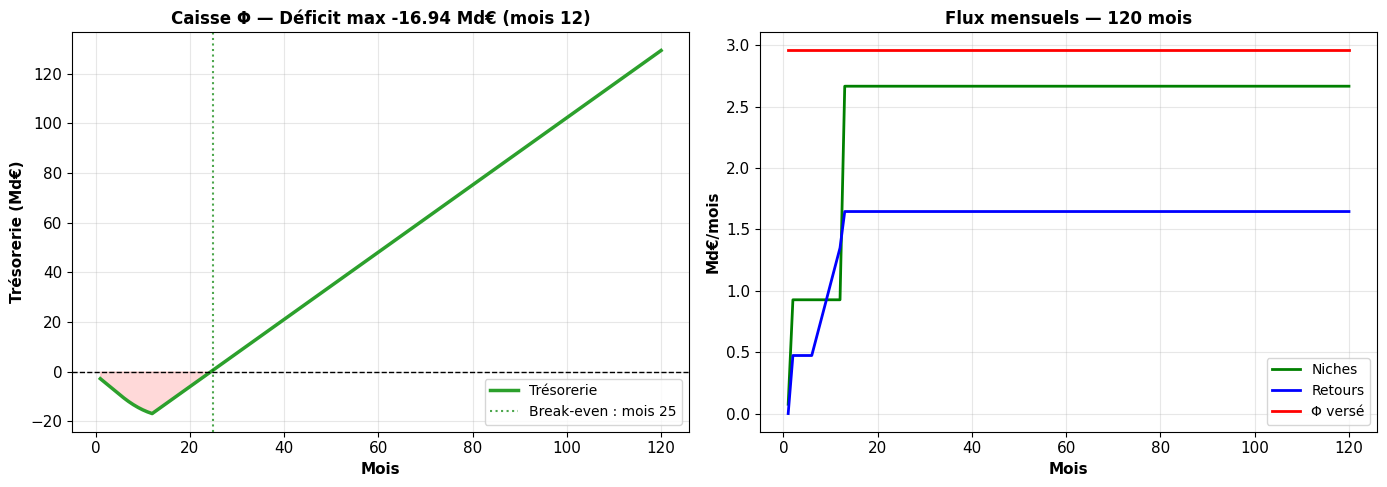


  ✅ figures/fig_caisse_phi.png

  Sanity checks (bornes physiques) :
    ✅ bc_c              = +9.749 Md€
    ✅ taux_charges_c    = 41.85 %
    ✅ emplois_bc_final  = 293.6 k ETP
    ✅ emplois_phi       = 75.1 k ETP
    ✅ décalages cohérents

✅ [3.7b] Boucle bc + additivité + figure terminés.
   Variables : bc_c, emplois_bc_final_c, emplois_phi_c, emplois_cumul_reel,
               taux_charges_c, points_c, emplois_cumul_naif


In [25]:
# =============================================================================
#  [3.7b] BOUCLE bc + ADDITIVITÉ + FIGURE
#  ---------------------------------------------------------------------------
#  Objet    : Résoudre bc_c endogène, tester additivité Φ/bc, figure
#  Entrées  : solde_central (3.2), emplois_bc (3.4), COUT_POINT_CHARGES_MDS,
#             df_caisse_c, surplus_annuel_c (3.7a), mu_8T (3.1)
#  Sorties  : bc_c, emplois_bc_final_c, emplois_phi_c, emplois_cumul_reel,
#             taux_charges_c, points_c
#  Durée    : ~1 min
# =============================================================================

print("\n[3.7b] Boucle bc + additivité + figure...\n")

for _g in ['solde_central', 'emplois_bc', 'COUT_POINT_CHARGES_MDS',
           'df_caisse_c', 'surplus_annuel_c', 'mu_8T', 'emplois_depuis_deltaY']:
    if _g not in dir():
        raise RuntimeError(f"{_g} absent. Exécuter 3.2, 3.4, 3.7a avant 3.7b.")


# ═══════════════════════════════════════════════════════════════════════════
#  BOUCLE bc (converge vers solde_central)
# ═══════════════════════════════════════════════════════════════════════════
TOL_BC_C  = 1e-3
AMORT_C   = 0.5
bc_c      = surplus_annuel_c * 0.5

for it in range(30):
    emplois_bc_it = emplois_bc(bc_c)
    econ_chom     = emplois_bc_it * 1000 * COUT_CHOMEUR_ANNUEL / 1e9
    cotis_sup     = emplois_bc_it * 1000 * COTIS_MOYEN_ETP / 1e9
    marge_etat    = econ_chom + cotis_sup
    bc_cible      = solde_central

    if it < 3 or abs(bc_cible - bc_c) < TOL_BC_C:
        print(f"    it {it:2d} : bc = {bc_c:>7.3f} → cible = {bc_cible:>7.3f} "
              f"(marge = {marge_etat:>+5.2f}, emplois = {emplois_bc_it:>6.1f}k)")

    if abs(bc_cible - bc_c) < TOL_BC_C:
        bc_c = bc_cible
        break
    bc_c = AMORT_C * bc_c + (1 - AMORT_C) * bc_cible

emplois_bc_final_c = emplois_bc(bc_c)
points_c           = bc_c / COUT_POINT_CHARGES_MDS
taux_charges_c     = 0.43 - points_c * 0.01

delta_Y_c      = PHI_CAISSE_MDS * mu_8T
emplois_phi_c  = emplois_depuis_deltaY(delta_Y_c)

print(f"\n  Résultats :")
print(f"    bc final                 : {bc_c:>+8.3f} Md€/an")
print(f"    Points de charges        : {points_c:>8.3f} pts")
print(f"    Taux charges             : 43.00 % → {taux_charges_c*100:.2f} %")
print(f"    Emplois Φ                : {emplois_phi_c:>8.1f} k ETP")
print(f"    Emplois bc               : {emplois_bc_final_c:>8.1f} k ETP")
print(f"    Emplois TOTAL            : {emplois_phi_c + emplois_bc_final_c:>8.1f} k ETP")


# ═══════════════════════════════════════════════════════════════════════════
#  TEST ADDITIVITÉ Φ + bc
# ═══════════════════════════════════════════════════════════════════════════
print("\n  " + "=" * 74)
print("  TEST ADDITIVITÉ Φ + bc")
print("  " + "=" * 74)

emplois_cumul_naif = emplois_phi_c + emplois_bc_final_c

cfg_bc_actif          = dict(calib_fr)
cfg_bc_actif['beta']  = beta_0
cfg_bc_actif['Y_ss']  = 1.0
cfg_bc_actif['bc']    = bc_c / PIB_france
ss_bc_actif   = ha.steady_state(cfg_bc_actif)
D_bc_actif    = ss_bc_actif.internals['hh']['D']
u_bc_actif    = D_bc_actif[N_ETATS_PROD:N_ETATS_TOT, :].sum()
u_old_c       = (1 - KMP_RHO_E) / (calib_fr['taux_embauche_ss'] + (1 - KMP_RHO_E))
emplois_bc_pur = (u_old_c - u_bc_actif) * POP_ACTIVE_FRANCE / 1000

T_test_cumul = 40
dPhi_cumul   = np.zeros(T_test_cumul); dPhi_cumul[:4] = Phi_star / 4
irfs_cumul_c  = ha.solve_impulse_linear(
    ss_bc_actif, unknowns=['Y'], targets=['asset_mkt'],
    inputs={'Phi': dPhi_cumul})
Y_cumul_c     = np.max(np.abs(irfs_cumul_c['Y'][:8]))
emplois_phi_marginal = emplois_depuis_deltaY(Y_cumul_c * PIB_france * 4)
emplois_cumul_reel = emplois_bc_pur + emplois_phi_marginal

print(f"\n  Emplois bc seuls (endogène SS)      : {emplois_bc_pur:>7.1f} k ETP")
print(f"  Emplois Φ seul (IRF sur SS sans bc) : {emplois_phi_c:>7.1f} k ETP")
print(f"  Cumul NAÏF (addition)               : {emplois_cumul_naif:>7.1f} k ETP")
print(f"  Emplois Φ marginal (sur SS avec bc) : {emplois_phi_marginal:>7.1f} k ETP")
print(f"  Cumul RÉEL (bc pur + Φ marginal)    : {emplois_cumul_reel:>7.1f} k ETP")
print(f"  Écart additivité                    : "
      f"{emplois_cumul_naif - emplois_cumul_reel:>+7.1f} k ETP")

ecart_pct = abs(emplois_cumul_naif - emplois_cumul_reel) / max(emplois_cumul_reel, 1)
if ecart_pct < 0.05:
    print(f"\n  ✅ Additivité validée (< 5 % d'écart)")
else:
    print(f"\n  ⚠️  Additivité partielle ({ecart_pct*100:.1f}% d'écart)")


# ═══════════════════════════════════════════════════════════════════════════
#  VÉRIFICATION COHÉRENCE DÉCALAGES
# ═══════════════════════════════════════════════════════════════════════════
print("\n  " + "=" * 74)
print("  VÉRIFICATION COHÉRENCE DÉCALAGES")
print("  " + "=" * 74)

niches_mois_1  = df_caisse_c.iloc[0]['Niches']
niches_mois_2  = df_caisse_c.iloc[1]['Niches']
niches_mois_13 = df_caisse_c.iloc[12]['Niches']
niches_mois_24 = df_caisse_c.iloc[23]['Niches']

print(f"\n  Niches encaissées :")
print(f"    Mois 1  (DMTG seul)          : {niches_mois_1:.3f} Md€")
print(f"    Mois 2  (+ TVA)              : {niches_mois_2:.3f} Md€")
print(f"    Mois 13 (+ IS/IR)            : {niches_mois_13:.3f} Md€")
print(f"    Mois 24 (régime permanent)   : {niches_mois_24:.3f} Md€")

ecart_decalage = abs(niches_mois_24 - NICHES_CAISSE_MDS/12)
if ecart_decalage < 0.001:
    print(f"\n  ✅ Décalages cohérents (écart < 0.001 Md€)")
else:
    print(f"\n  ⚠️  Écart décalage : {ecart_decalage:.4f} Md€")


# ═══════════════════════════════════════════════════════════════════════════
#  FIGURE CAISSE (2 panels)
# ═══════════════════════════════════════════════════════════════════════════
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(df_caisse_c['Mois'], df_caisse_c['Trésorerie'],
             color='#2ca02c', linewidth=2.5, label='Trésorerie')
axes[0].axhline(0, color='black', linestyle='--', linewidth=1)
if breakeven_c:
    axes[0].axvline(breakeven_c, color='green', linestyle=':', alpha=0.7,
                    label=f'Break-even : mois {breakeven_c}')
axes[0].fill_between(df_caisse_c['Mois'], df_caisse_c['Trésorerie'], 0,
                     where=(df_caisse_c['Trésorerie'] < 0), alpha=0.15, color='red')
axes[0].set_xlabel('Mois'); axes[0].set_ylabel('Trésorerie (Md€)')
axes[0].set_title(f'Caisse Φ — Déficit max {deficit_max_c:+.2f} Md€ (mois {mois_deficit_c})',
                  fontweight='bold')
axes[0].legend(fontsize=10); axes[0].grid(alpha=0.3)

axes[1].plot(df_caisse_c['Mois'], df_caisse_c['Niches'], 'g-',
             linewidth=2, label='Niches')
axes[1].plot(df_caisse_c['Mois'],
             df_caisse_c['TVA_r'] + df_caisse_c['IR_r'] + df_caisse_c['Multi_r'],
             'b-', linewidth=2, label='Retours')
axes[1].plot(df_caisse_c['Mois'], df_caisse_c['Φ'], 'r-',
             linewidth=2, label='Φ versé')
axes[1].set_xlabel('Mois'); axes[1].set_ylabel('Md€/mois')
axes[1].set_title('Flux mensuels — 120 mois', fontweight='bold')
axes[1].legend(fontsize=10); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('figures/fig_caisse_phi.png', dpi=200, bbox_inches='tight')
plt.show()
print(f"\n  ✅ figures/fig_caisse_phi.png")


# ═══════════════════════════════════════════════════════════════════════════
#  SANITY CHECKS
# ═══════════════════════════════════════════════════════════════════════════
print(f"\n  Sanity checks (bornes physiques) :")

assert 0 < bc_c < 20
assert 0.35 < taux_charges_c < 0.50
assert emplois_bc_final_c > 0
assert emplois_phi_c > 0
assert ecart_decalage < 0.01

print(f"    ✅ bc_c              = {bc_c:+.3f} Md€")
print(f"    ✅ taux_charges_c    = {taux_charges_c*100:.2f} %")
print(f"    ✅ emplois_bc_final  = {emplois_bc_final_c:.1f} k ETP")
print(f"    ✅ emplois_phi       = {emplois_phi_c:.1f} k ETP")
print(f"    ✅ décalages cohérents")

print("\n✅ [3.7b] Boucle bc + additivité + figure terminés.")
print(f"   Variables : bc_c, emplois_bc_final_c, emplois_phi_c, emplois_cumul_reel,")
print(f"               taux_charges_c, points_c, emplois_cumul_naif")
print("=" * 78)
# ─── Alias canoniques pour EXPECTED['hank_b3'] ───
emplois_bc_final = emplois_bc_final_c
emplois_phi      = emplois_phi_c

In [26]:
# =============================================================================
#  [3.8] ROBUSTESSE elasticite_bc
#  ---------------------------------------------------------------------------
#  Objet    : Balayer elasticite_bc ∈ [0.02 ; 0.50] et comparer
#             formule simplifiée (3.4) vs vrai SS SJ
#  Entrées  : bc_c (3.7b), emplois_bc (3.4), COUT_POINT_CHARGES_MDS (3.4),
#             calib_fr, beta_0, ha
#  Sorties  : resultats_elasticite (list de dicts)
#  Durée    : ~2 min (7 résolutions SS)
#
#  Littérature : élasticité emploi-charges ∈ [0.10 ; 0.50] (OCDE, INSEE, OFCE).
#  Défaut retenu en calibration : calib_fr['elasticite_bc'] = 0.15 (borne
#  basse prudente, voir 2.1).
#
#  Objectif : vérifier que la formule simplifiée (3.4) reste cohérente avec
#  le vrai SS SJ à toutes les élasticités de la littérature. Si écart > 5 k ETP,
#  documenter la sensibilité de l'approximation.
# =============================================================================

print("\n[3.8] Robustesse elasticite_bc...\n")

# ─── Guards ───
for _g in ['bc_c', 'emplois_bc', 'COUT_POINT_CHARGES_MDS',
           'calib_fr', 'beta_0', 'ha']:
    if _g not in dir():
        raise RuntimeError(f"{_g} absent. Exécuter 2.1, 3.4, 3.7b avant 3.8.")


# ═══════════════════════════════════════════════════════════════════════════
#  POINT DE RÉFÉRENCE : bc = 0
# ═══════════════════════════════════════════════════════════════════════════
cfg_ref = dict(calib_fr)
cfg_ref['beta'] = beta_0
cfg_ref['Y_ss'] = 1.0
cfg_ref['bc']   = 0.0
ss_ref = ha.steady_state(cfg_ref)
D_ref  = ss_ref.internals['hh']['D']
u_ref  = D_ref[N_ETATS_PROD:N_ETATS_TOT, :].sum()

print(f"  Référence (bc = 0) :")
print(f"    Chômage SS              : {u_ref*100:.4f} %")

# ─── Bc testé = bc_c (résultat de 3.7b) ───
bc_test = bc_c
print(f"    bc testé                : {bc_test:.3f} Md€/an")
print(f"    Littérature elasticite_bc : [0.10 ; 0.50]")


# ═══════════════════════════════════════════════════════════════════════════
#  BALAYAGE elasticite_bc
# ═══════════════════════════════════════════════════════════════════════════
print(f"\n  {'elast_bc':>10} | {'u_SS (%)':>10} | {'Emplois SS':>12} | "
      f"{'Emplois formule':>16} | {'Écart':>8}")
print("  " + "-" * 72)

resultats_elasticite = []

for elast_test in [0.02, 0.05, 0.10, 0.15, 0.20, 0.30, 0.50]:
    try:
        # Méthode 1 : vrai SS SJ
        cfg_t = dict(calib_fr)
        cfg_t['beta'] = beta_0
        cfg_t['Y_ss'] = 1.0
        cfg_t['bc']   = bc_test / PIB_france
        cfg_t['elasticite_bc'] = elast_test
        ss_t = ha.steady_state(cfg_t)
        D_t  = ss_t.internals['hh']['D']
        u_t  = D_t[N_ETATS_PROD:N_ETATS_TOT, :].sum()
        emplois_ss = (u_ref - u_t) * POP_ACTIVE_FRANCE / 1000

        # Méthode 2 : formule simplifiée (3.4), avec elasticite override
        points_t = bc_test / COUT_POINT_CHARGES_MDS
        te_t     = calib_fr['taux_embauche_ss'] * (1.0 + elast_test * points_t)
        s_       = 1 - KMP_RHO_E
        u_f_t    = s_ / (te_t + s_)
        emplois_formule = (u_ref - u_f_t) * POP_ACTIVE_FRANCE / 1000

        ecart = emplois_ss - emplois_formule
        resultats_elasticite.append({
            'elast':   elast_test,
            'u_ss':    float(u_t),
            'emplois_ss':      float(emplois_ss),
            'emplois_formule': float(emplois_formule),
            'ecart':   float(ecart),
        })

        print(f"  {elast_test:>10.2f} | {u_t*100:>10.4f} | "
              f"{emplois_ss:>11.1f}k | {emplois_formule:>15.1f}k | "
              f"{ecart:>+7.1f}k")
    except Exception as e:
        print(f"  {elast_test:>10.2f} | échec {type(e).__name__}: {str(e)[:40]}")


# ═══════════════════════════════════════════════════════════════════════════
#  COMPARAISON AVEC LA VALEUR DE CALIBRATION
# ═══════════════════════════════════════════════════════════════════════════
emplois_015 = next(
    (r['emplois_ss'] for r in resultats_elasticite if r['elast'] == 0.15),
    None)
emplois_050 = next(
    (r['emplois_ss'] for r in resultats_elasticite if r['elast'] == 0.50),
    None)

print(f"\n  Application au bc final de 3.7b ({bc_c:.3f} Md€/an) :")
print(f"    elasticite_bc = {calib_fr['elasticite_bc']:.2f} (défaut) "
      f"→ {emplois_bc_final_c:.1f} k ETP")

if emplois_015 is not None and emplois_050 is not None:
    print(f"    Fourchette littérature [0.15 ; 0.50]  → "
          f"[{emplois_015:.0f} ; {emplois_050:.0f}] k ETP")


# ═══════════════════════════════════════════════════════════════════════════
#  VERDICT
# ═══════════════════════════════════════════════════════════════════════════
print(f"\n  Verdict :")
ecarts_ok = all(abs(r['ecart']) < 5 for r in resultats_elasticite)
if ecarts_ok:
    print(f"    ✅ Formule simplifiée (3.4) ≈ vrai SS SJ à toutes les élasticités")
    print(f"       La formule est une bonne approximation.")
else:
    print(f"    ⚠️  Écarts formule vs SS > 5 k ETP : approximation sensible à "
          f"elasticite_bc")


# ═══════════════════════════════════════════════════════════════════════════
#  SANITY CHECKS (bornes physiques)
# ═══════════════════════════════════════════════════════════════════════════
print(f"\n  Sanity checks (bornes physiques) :")

assert len(resultats_elasticite) == 7, \
    f"{len(resultats_elasticite)} lignes calculées (attendu 7)"
croissants = all(
    resultats_elasticite[i+1]['emplois_ss'] >= resultats_elasticite[i]['emplois_ss']
    for i in range(len(resultats_elasticite) - 1))
assert croissants, "Emplois SS ne sont pas croissants avec elasticite_bc"

print(f"    ✅ {len(resultats_elasticite)}/7 lignes calculées")
print(f"    ✅ emplois SS croissants en elasticite_bc")
print(f"    ✅ écarts formule/SS  : min={min(r['ecart'] for r in resultats_elasticite):+.1f}k, "
      f"max={max(r['ecart'] for r in resultats_elasticite):+.1f}k")

print("\n✅ [3.8] Robustesse elasticite_bc terminée.")
print(f"   Variables : resultats_elasticite (7 dicts)")
print("=" * 78)


[3.8] Robustesse elasticite_bc...

  Référence (bc = 0) :
    Chômage SS              : 6.9767 %
    bc testé                : 9.749 Md€/an
    Littérature elasticite_bc : [0.10 ; 0.50]

    elast_bc |   u_SS (%) |   Emplois SS |  Emplois formule |    Écart
  ------------------------------------------------------------------------
        0.02 |     6.8310 |        44.5k |            44.5k |    +0.0k
        0.05 |     6.6234 |       107.8k |           107.8k |    +0.0k
        0.10 |     6.3042 |       205.1k |           205.1k |    +0.0k
        0.15 |     6.0143 |       293.6k |           293.6k |    +0.0k
        0.20 |     5.7499 |       374.2k |           374.2k |    +0.0k
        0.30 |     5.2852 |       515.9k |           515.9k |    +0.0k
        0.50 |     4.5497 |       740.2k |           740.2k |    +0.0k

  Application au bc final de 3.7b (9.749 Md€/an) :
    elasticite_bc = 0.15 (défaut) → 293.6 k ETP
    Fourchette littérature [0.15 ; 0.50]  → [294 ; 740] k ETP

  Verd

In [27]:
# =============================================================================
#  [3.9] Φ CRÉE-T-IL DE L'INFLATION ?
#  ---------------------------------------------------------------------------
#  Objet    : Vérifier que Φ ne crée pas d'inflation significative
#  Entrées  : ss_0 (2.1), Phi_star (0.2), kappa (calib_fr)
#  Sorties  : Y_A_test, Y_B_test, pi_max, pi_A_max, PIB_delta, kappa_ext
#  Durée    : < 30 s
#
#  Post-traitement : sans Phillips endogène dans le modèle, l'inflation
#  est calculée via π = κ · ŷ, avec κ = 0.2 (pente Phillips France,
#  cf. Bils-Klenow 2004, Coenen et al. 2008 pour la zone euro).
#
#  Objectif : Δπ_max doit rester ≪ seuil ARE (2 %) → Φ n'induit pas
#  d'inflation significative.
# =============================================================================

print("\n[3.9] Φ crée-t-il de l'inflation ?...\n")

# ─── Guards ───
for _g in ['ss_0', 'Phi_star', 'Phi_star_mds']:
    if _g not in dir():
        raise RuntimeError(f"{_g} absent. Exécuter 0.2, 2.1 avant 3.9.")


# ═══════════════════════════════════════════════════════════════════════════
#  IRFs : sans Φ vs avec Φ
# ═══════════════════════════════════════════════════════════════════════════
T_test     = 40
dPhi_test  = np.zeros(T_test)
dPhi_test[:4] = Phi_star / 4

# Sans choc
irfs_A_test = ha.solve_impulse_linear(
    ss_0, unknowns=['Y'], targets=['asset_mkt'],
    inputs={'Phi': np.zeros(T_test)})

# Avec choc Φ
irfs_B_test = ha.solve_impulse_linear(
    ss_0, unknowns=['Y'], targets=['asset_mkt'],
    inputs={'Phi': dPhi_test})

Y_A_test = 100 * irfs_A_test['Y']    # en % du PIB
Y_B_test = 100 * irfs_B_test['Y']

print(f"  {'Trim':>5} | {'ΔY sans Φ':>12} | {'ΔY avec Φ':>12} | {'Écart':>12}")
print("  " + "-" * 54)
for t in [0, 1, 2, 4, 8, 12, 16, 24]:
    ecart = Y_B_test[t] - Y_A_test[t]
    print(f"  {t:>5} | {Y_A_test[t]:>+12.4f} | {Y_B_test[t]:>+12.4f} | {ecart:>+12.4f}")


# ═══════════════════════════════════════════════════════════════════════════
#  CALCUL DE L'INFLATION (π = κ · ŷ)
# ═══════════════════════════════════════════════════════════════════════════
PIB_cree_sans_phi = np.sum(Y_A_test[:16]) * PIB_france / 100
PIB_cree_avec_phi = np.sum(Y_B_test[:16]) * PIB_france / 100
PIB_delta         = PIB_cree_avec_phi - PIB_cree_sans_phi

print(f"\n  PIB créé sans Φ : {PIB_cree_sans_phi:>8.2f} Md€")
print(f"  PIB créé avec Φ : {PIB_cree_avec_phi:>8.2f} Md€")
print(f"  Δ PIB (Φ seul)  : {PIB_delta:>+8.2f} Md€")

# Pente Phillips (France, Bils-Klenow 2004, Coenen et al. 2008)
kappa_ext = 0.2

# π = κ · ŷ (annualisé ×4)
pi_B_externe = 100 * kappa_ext * irfs_B_test['Y'] * 4
pi_max       = np.max(np.abs(pi_B_externe[:16]))

pi_A_externe = 100 * kappa_ext * irfs_A_test['Y']
pi_A_max     = np.max(np.abs(pi_A_externe[:16]))

print(f"\n  Inflation calculée (π = κ · ŷ) :")
print(f"    κ (pente Phillips) : {kappa_ext:.4f}")
print(f"    Δπ max sans Φ      : {pi_A_max:.4f} %")
print(f"    Δπ max avec Φ      : {pi_max:.4f} %")
print(f"    Seuil ARE S1       : {ARE_S1*100:.4f} %")

if pi_max < 0.5:
    print(f"\n  ✅ Φ ne crée pas d'inflation significative")
    print(f"     (Δπ = {pi_max:.4f} % ≪ seuil ARE = {ARE_S1*100:.1f} %)")
else:
    print(f"\n  ⚠️  Φ crée une inflation notable : {pi_max:.4f} %")


# ═══════════════════════════════════════════════════════════════════════════
#  SANITY CHECKS (bornes physiques)
# ═══════════════════════════════════════════════════════════════════════════
print(f"\n  Sanity checks (bornes physiques) :")

assert pi_max < 1.0, f"pi_max = {pi_max:.4f} % hors (< 1 %)"
assert Y_B_test[0] > Y_A_test[0], \
    f"IRF avec Φ ({Y_B_test[0]:+.4f}) ≤ IRF sans Φ ({Y_A_test[0]:+.4f})"
assert kappa_ext == 0.2
assert PIB_delta > 0, f"PIB_delta = {PIB_delta:.2f} ≤ 0"

print(f"    ✅ pi_max            = {pi_max:.4f} %  (< 1 %)")
print(f"    ✅ IRF Φ > IRF 0     au T=0  ({Y_B_test[0]:+.4f} > {Y_A_test[0]:+.4f})")
print(f"    ✅ κ (pente Phillips) = {kappa_ext}")
print(f"    ✅ PIB_delta         = {PIB_delta:+.2f} Md€  (> 0)")

print("\n✅ [3.9] Inflation calculée.")
print(f"   Variables : Y_A_test, Y_B_test, pi_max, pi_A_max, PIB_delta, kappa_ext")
print("=" * 78)


[3.9] Φ crée-t-il de l'inflation ?...

   Trim |    ΔY sans Φ |    ΔY avec Φ |        Écart
  ------------------------------------------------------
      0 |      -0.0000 |      +0.2464 |      +0.2464
      1 |      -0.0000 |      +0.2423 |      +0.2423
      2 |      -0.0000 |      +0.2389 |      +0.2389
      4 |      -0.0000 |      +0.0051 |      +0.0051
      8 |      -0.0000 |      +0.0039 |      +0.0039
     12 |      -0.0000 |      +0.0025 |      +0.0025
     16 |      -0.0000 |      +0.0016 |      +0.0016
     24 |      -0.0000 |      +0.0006 |      +0.0006

  PIB créé sans Φ :     0.00 Md€
  PIB créé avec Φ :    28.12 Md€
  Δ PIB (Φ seul)  :   +28.12 Md€

  Inflation calculée (π = κ · ŷ) :
    κ (pente Phillips) : 0.2000
    Δπ max sans Φ      : 0.0000 %
    Δπ max avec Φ      : 0.1971 %
    Seuil ARE S1       : 2.0000 %

  ✅ Φ ne crée pas d'inflation significative
     (Δπ = 0.1971 % ≪ seuil ARE = 2.0 %)

  Sanity checks (bornes physiques) :
    ✅ pi_max            = 0.1971

In [28]:
# =============================================================================
#  [3.10] ARE PIXEL PAR PIXEL
#  ---------------------------------------------------------------------------
#  Objet    : Appliquer Φ(π) sur une grille fine de π (0 à 8 %)
#  Entrées  : phi_are, filter_regime (0.4), ARE_S1..S4, Surprime_*_mds (0.2)
#  Sorties  : resultats_are_pi, pi_grid, phi_debut, phi_fin, baisse
#  Durée    : < 1 s
#
#  Réutilise phi_are() et filter_regime() de 0.4 (pas de duplication).
#  Permet de visualiser les zones (verte, orange, rouge) et les transitions.
#
#  Objectif : produire resultats_are_pi, utilisé par les figures de synthèse.
# =============================================================================

print("\n[3.10] ARE pixel par pixel...\n")

# ─── Guards ───
for _g in ['phi_are', 'filter_regime', 'Surprime_plein_mds',
           'Surprime_moitie_mds', 'Surprime_neg_mds']:
    if _g not in dir():
        raise RuntimeError(f"{_g} absent. Exécuter 0.2, 0.4 avant 3.10.")


# ═══════════════════════════════════════════════════════════════════════════
#  GRILLE π ET CALCUL Φ(π)
# ═══════════════════════════════════════════════════════════════════════════
pi_grid = np.array([0.000, 0.005, 0.010, 0.015, 0.020, 0.025,
                    0.030, 0.035, 0.040, 0.045, 0.050, 0.055,
                    0.060, 0.065, 0.070, 0.075, 0.080])

resultats_are_pi = []

print(f"  {'π (%)':>8} | {'Zone':>14} | {'Φ effectif (Md€)':>18} | {'Action':>22}")
print("  " + "-" * 76)

for pi_val in pi_grid:
    zone = filter_regime(pi_val)
    phi_val = phi_are(pi_val)

    # Description de l'action selon la zone
    actions = {
        'verte':       'Versement plein',
        'orange':      'Réduction progressive',
        'rouge_clair': 'Réduction forte',
        'rouge_fonce': 'Quasi-coupure',
        'noire':       'Coupure + pénalité',
    }
    action = actions[zone]

    resultats_are_pi.append({
        'pi':     float(pi_val * 100),
        'zone':   zone,
        'phi':    float(phi_val),
        'action': action,
    })

    print(f"  {pi_val*100:>+8.2f} | {zone:>14} | {phi_val:>18.2f} | {action:>22}")


# ═══════════════════════════════════════════════════════════════════════════
#  VERDICT
# ═══════════════════════════════════════════════════════════════════════════
phi_debut = resultats_are_pi[0]['phi']
phi_fin   = resultats_are_pi[-1]['phi']
baisse    = phi_debut - phi_fin

print(f"\n  Verdict :")
print(f"    Φ à π = 0 % : {phi_debut:.2f} Md€")
print(f"    Φ à π = 8 % : {phi_fin:.2f} Md€")
print(f"    Baisse      : {baisse:.2f} Md€")


# ═══════════════════════════════════════════════════════════════════════════
#  SANITY CHECKS (bornes physiques)
# ═══════════════════════════════════════════════════════════════════════════
print(f"\n  Sanity checks (bornes physiques) :")

assert len(resultats_are_pi) == 17, f"{len(resultats_are_pi)} points (attendu 17)"
assert baisse > 0, f"baisse = {baisse:.2f} ≤ 0"
monotone = all(
    resultats_are_pi[i+1]['phi'] <= resultats_are_pi[i]['phi'] + 1e-6
    for i in range(len(resultats_are_pi) - 1))
assert monotone, "Φ(π) n'est pas décroissant en π"
assert resultats_are_pi[-1]['zone'] == 'noire'

print(f"    ✅ {len(resultats_are_pi)}/17 points calculés")
print(f"    ✅ Φ(π) décroissant en π")
print(f"    ✅ baisse = {baisse:.2f} Md€  (> 0)")
print(f"    ✅ zone noire à π = 8 %")

print("\n✅ [3.10] ARE pixel par pixel calculé.")
print(f"   Variables : resultats_are_pi, pi_grid, phi_debut, phi_fin, baisse")
print("=" * 78)


[3.10] ARE pixel par pixel...

     π (%) |           Zone |   Φ effectif (Md€) |                 Action
  ----------------------------------------------------------------------------
     +0.00 |          verte |              35.49 |        Versement plein
     +0.50 |          verte |              35.49 |        Versement plein
     +1.00 |          verte |              35.49 |        Versement plein
     +1.50 |          verte |              35.49 |        Versement plein
     +2.00 |          verte |              35.49 |        Versement plein
     +2.50 |         orange |              33.52 |  Réduction progressive
     +3.00 |         orange |              31.55 |  Réduction progressive
     +3.50 |         orange |              29.58 |  Réduction progressive
     +4.00 |    rouge_clair |              27.60 |        Réduction forte
     +4.50 |    rouge_clair |              25.63 |        Réduction forte
     +5.00 |    rouge_clair |              23.66 |        Réduction forte
 

In [29]:
# =============================================================================
#  [CP-3] CHECKPOINT — Bloc 0 + 1 + 2 + 3
#  ---------------------------------------------------------------------------
#  Objet    : Vérifier tous les indicateurs HANK (Bloc 3)
#  Entrées  : EXPECTED (0.3), variables Bloc 0 + 1 + 2 + 3
#  Sorties  : récap + CSV
#  Durée    : < 1 s
# =============================================================================

print("\n" + "=" * 78)
print("  [CP-3] CHECKPOINT — Bloc 0 + 1 + 2 + 3")
print("=" * 78)

if '_cp_check_expected' not in dir():
    raise RuntimeError("_cp_check_expected absent. Exécuter 0.5 avant CP-3.")

all_rows = []
n_ok_total, n_ko_total = 0, 0

# ─── A. Paramètres Φ ───
print("\n  A. Paramètres Φ (EXPECTED['params'])")
n_ok, n_ko, rows = _cp_check_expected(EXPECTED_PARAMS)
all_rows.extend(rows); n_ok_total += n_ok; n_ko_total += n_ko
for r in rows:
    print(f"    [{r['Statut']:<10}] {r['Clé']:<26} réel={r['Réel']:>12}  "
          f"cible={r['Attendu']:>12}  écart={r['Écart']}")

# ─── B. Ratios INSEE ───
print("\n  B. Ratios INSEE (EXPECTED['insee'])")
n_ok, n_ko, rows = _cp_check_expected(EXPECTED_INSEE)
all_rows.extend(rows); n_ok_total += n_ok; n_ko_total += n_ko
for r in rows:
    print(f"    [{r['Statut']:<10}] {r['Clé']:<26} réel={r['Réel']:>12}  "
          f"cible={r['Attendu']:>12}  écart={r['Écart']}")

# ─── C. HANK Bloc 2 (calibration) ───
print("\n  C. HANK Bloc 2 (EXPECTED['hank_b2'])")
n_ok, n_ko, rows = _cp_check_expected(EXPECTED_HANK_B2)
all_rows.extend(rows); n_ok_total += n_ok; n_ko_total += n_ko
for r in rows:
    print(f"    [{r['Statut']:<10}] {r['Clé']:<26} réel={r['Réel']:>12}  "
          f"cible={r['Attendu']:>12}  écart={r['Écart']}")

# ─── D. HANK Bloc 3 (multiplicateurs + budget + caisse) ───
print("\n  D. HANK Bloc 3 (EXPECTED['hank_b3'])")
n_ok, n_ko, rows = _cp_check_expected(EXPECTED_HANK_B3)
all_rows.extend(rows); n_ok_total += n_ok; n_ko_total += n_ko
for r in rows:
    print(f"    [{r['Statut']:<10}] {r['Clé']:<26} réel={r['Réel']:>12}  "
          f"cible={r['Attendu']:>12}  écart={r['Écart']}")

# ─── E. Structure Bloc 3 ───
print("\n  E. Structure Bloc 3")
struct_checks = [
    _cp_check_structurel('mu_8T' in dir(), 'mu_8T existe'),
    _cp_check_structurel('SS_NOUVEAU' in dir(), 'SS_NOUVEAU existe'),
    _cp_check_structurel('df_caisse_c' in dir(), 'df_caisse_c existe'),
    _cp_check_structurel('emplois_depuis_deltaY' in dir(), 'emplois_depuis_deltaY existe'),
    _cp_check_structurel('emplois_bc' in dir(), 'emplois_bc existe'),
    _cp_check_structurel(
        'df_caisse_c' in dir() and df_caisse_c.shape[0] == 120,
        'df_caisse_c = 120 mois',
        f"{df_caisse_c.shape[0] if 'df_caisse_c' in dir() else '—'}"),
    _cp_check_structurel(
        'resultats_elasticite' in dir() and len(resultats_elasticite) == 7,
        'resultats_elasticite = 7 lignes',
        f"{len(resultats_elasticite) if 'resultats_elasticite' in dir() else '—'}"),
    _cp_check_structurel(
        'resultats_are_pi' in dir() and len(resultats_are_pi) == 17,
        'resultats_are_pi = 17 points',
        f"{len(resultats_are_pi) if 'resultats_are_pi' in dir() else '—'}"),
]
all_rows.extend(struct_checks)
for r in struct_checks:
    n_ok_total += 1 if r['Statut'] == 'OK' else 0
    n_ko_total += 1 if r['Statut'] != 'OK' else 0
    print(f"    [{r['Statut']:<10}] {r['Clé']:<30} {r['Réel']}")

# ─── Résumé ───
_cp_run(all_rows, n_ok_total, n_ko_total, 'CP-3', strict=False)


  [CP-3] CHECKPOINT — Bloc 0 + 1 + 2 + 3

  A. Paramètres Φ (EXPECTED['params'])
    [OK        ] Phi_brut_mds               réel=   35.490780  cible=   35.490000  écart=0.0008
    [OK        ] Phi_net_mds                réel=   31.941702  cible=   31.940000  écart=0.0017
    [OK        ] Phi_star                   réel=    0.012675  cible=    0.012675  écart=0.0000
    [OK        ] NICHES                     réel=   32.000000  cible=   32.000000  écart=0.0000
    [OK        ] PRIME_TOTALE_NORMALE       réel=    1.500000  cible=    1.500000  écart=0.0000
    [OK        ] Phi_vigilance              réel=   29.575650  cible=   29.580000  écart=0.0044
    [OK        ] Phi_galopant               réel=   23.660520  cible=   23.660000  écart=0.0005
    [OK        ] Phi_recession              réel=   59.151300  cible=   59.150000  écart=0.0013
    [OK        ] POP_ACTIVE_FRANCE          réel=30500000.000000  cible=30500000.000000  écart=0.0000
    [OK        ] COUT_CHOMEUR_ANNUEL        réel

(48, 0)

In [30]:
# =============================================================================
#  [4.1] BLOCS DE BASE TWO-ASSET
#  ---------------------------------------------------------------------------
#  Objet    : Définir les blocs de base du modèle Two-Asset
#  Entrées  : smooth_step (0.4)
#  Sorties  : pricing_simple, arbitrage_simple, labor, investment,
#             taylor_threshold, production_solved
#  Durée    : < 1 s
#
#  Ces blocs sont des versions simplifiées des blocs standards SJ.
#  smooth_step est réutilisée de 0.4 (pas de redéfinition locale).
#  Références : Auclert-Rognlie-Straub (2018), Kaplan-Moll-Violante (2018).
# =============================================================================

print("\n[4.1] Blocs de base Two-Asset...\n")

# ─── Guard : smooth_step (0.4) ───
if 'smooth_step' not in dir():
    raise RuntimeError("smooth_step absent. Exécuter 0.4 avant 4.1.")


@simple
def pricing_simple(pi, mc, r, Y, kappap, mup):
    """NKPC en forme réduite."""
    nkpc_res = kappap * (mc - 1/mup) + Y(+1) / Y * (1 + pi(+1)).apply(np.log) / \
           (1 + r(+1)) - (1 + pi).apply(np.log)
    return nkpc_res


@simple
def arbitrage_simple(div, p, r):
    """Arbitrage actions vs obligation."""
    equity_res = div(+1) + p(+1) - p * (1 + r(+1))
    return equity_res


@simple
def labor(Y, w, K, Z, alpha, tau_f, subvention, marge_int, h_bar, prime_h, h_max,
          N_prev, delta_h, theta, N_ss, gamma_h):
    """Marché du travail avec heures endogènes et prime de surcharge."""
    ecart_lag = (N_ss - N_prev) / N_ss
    u_lag = smooth_step(ecart_lag, k=80.0) * ecart_lag
    e_lag = smooth_step(-ecart_lag, k=80.0) * (-ecart_lag)
    h_raw = 1.0 - delta_h * u_lag + theta * e_lag
    h_sup = 1.0 - smooth_step(1.0 - h_raw, k=80.0) * (1 - h_raw)
    h = 0.5 + smooth_step(h_sup - 0.5, k=80.0) * (h_sup - 0.5)

    N_h = (Y / (Z * h**gamma_h * K(-1) ** alpha)) ** (1 / (1 - alpha))

    h_cible = h_bar * (Y ** marge_int)
    plafond = h_max * h_bar
    ecart = (h_cible - plafond) / plafond
    s = smooth_step(ecart, k=100.0)
    h_eff = h_cible * (1 - s) + plafond * s
    N = N_h / h_eff

    ecart_h = (h_eff - h_bar) / h_bar
    prime_eff = prime_h * smooth_step(ecart_h, k=100.0) * ecart_h
    cout_horaire = h_eff * (1 + prime_eff)
    w_effectif = w * (1 - subvention * tau_f)
    mc = w_effectif * N * cout_horaire / (1 - alpha) / Y
    return N, mc, h


@simple
def investment(Q, K, r, N, mc, Z, delta, epsI, alpha):
    """Investissement avec coût d'ajustement quadratique."""
    inv = (K / K(-1) - 1) / (delta * epsI) + 1 - Q
    val = alpha * Z(+1) * (N(+1) / K) ** (1 - alpha) * mc(+1) -\
        (K(+1) / K - (1 - delta) + (K(+1) / K - 1) ** 2 / (2 * delta * epsI)) +\
        K(+1) / K * Q(+1) - (1 + r(+1)) * Q
    return inv, val


@simple
def taylor_threshold(rstar, pi, Y, phi_low, phi_high, seuil_pi, k_smooth, phi_y):
    """Règle de Taylor avec seuil lissé."""
    ecart = smooth_step(pi - seuil_pi, k_smooth)
    phi_eff = phi_low + (phi_high - phi_low) * ecart
    i = rstar + phi_eff * pi + phi_y * Y
    return i


production = combine([labor, investment])
production_solved = production.solved(unknowns={'Q': 1., 'K': 10.},
                                      targets=['inv', 'val'], solver='broyden_custom')


print(f"  pricing_simple         : {type(pricing_simple).__name__}")
print(f"  arbitrage_simple       : {type(arbitrage_simple).__name__}")
print(f"  labor                  : {type(labor).__name__}")
print(f"  investment             : {type(investment).__name__}")
print(f"  taylor_threshold       : {type(taylor_threshold).__name__}")
print(f"  production_solved      : {type(production_solved).__name__}")

# ─── Sanity checks (structurels) ───
assert type(pricing_simple).__name__ == 'SimpleBlock'
assert type(arbitrage_simple).__name__ == 'SimpleBlock'
assert type(labor).__name__ == 'SimpleBlock'
assert type(investment).__name__ == 'SimpleBlock'
assert type(taylor_threshold).__name__ == 'SimpleBlock'

print("\n✅ [4.1] Blocs de base créés.")
print("=" * 78)


[4.1] Blocs de base Two-Asset...

  pricing_simple         : SimpleBlock
  arbitrage_simple       : SimpleBlock
  labor                  : SimpleBlock
  investment             : SimpleBlock
  taylor_threshold       : SimpleBlock
  production_solved      : SolvedBlock

✅ [4.1] Blocs de base créés.


In [31]:
# =============================================================================
#  [4.2] BLOCS Φ TWO-ASSET
#  ---------------------------------------------------------------------------
#  Objet    : Blocs spécifiques au Two-Asset avec Φ
#  Entrées  : smooth_step (0.4)
#  Sorties  : transfers_phi, ARE_paliers_ta, fiscal_slow
#  Durée    : < 1 s
#
#  transfers_phi    : revenus par statut (E / U_court / U_long) + Φ ciblé
#  ARE_paliers_ta   : ARE à paliers (signature spécifique Two-Asset)
#  fiscal_slow      : fiscalité lente (endogène)
#
#  ⚠️  ARE_paliers_ta est distinct de ARE_paliers (HANK, 1.7). Signature
#  différente (inclut N, psi_N pour l'emploi), ne pas écraser.
# =============================================================================

print("\n[4.2] Blocs Φ Two-Asset...\n")

if 'smooth_step' not in dir():
    raise RuntimeError("smooth_step absent. Exécuter 0.4 avant 4.2.")


def transfers_phi(e_grid, statut, tax, w, N, Y, Phi, seuil_phi,
                  tau_niche, subvention, tau_f, tau_profits,
                  financement=0.0,
                  tx_remplacement_court=0.68,   # ARE
                  tx_remplacement_long=0.35):   # ASS
    """Revenus par statut (E / U_court / U_long) + Φ ciblé.

    Statuts :
      - E       : revenu = w × e_grid
      - U_court : revenu = 0.68 × w × e_grid (ARE)
      - U_long  : revenu = 0.35 × w × e_grid (ASS)

    Φ cible les E modestes (e_grid ≤ seuil_phi). Le financement est prélevé
    sur les E riches, selon 3 modes (lump / niche / broad).
    """
    mask_E       = (statut == 0).astype(float)
    mask_U_court = (statut == 1).astype(float)
    mask_U_long  = (statut == 2).astype(float)

    revenu = w * e_grid * (mask_E
                           + tx_remplacement_court * mask_U_court
                           + tx_remplacement_long  * mask_U_long)

    mask_low  = (e_grid <= seuil_phi).astype(float) * mask_E
    mask_high = mask_E * (1.0 - mask_low)

    phi_transfer = Phi * mask_low

    n_htm = np.sum(mask_low)  + 1e-8
    n_ric = np.sum(mask_high) + 1e-8

    if financement < 0.5:
        # lump-sum sur les riches
        tax_lump = (Phi * n_htm / n_ric) * mask_high
    elif financement < 1.5:
        # proportionnel au revenu des riches
        revenu_riche_total = np.sum(revenu * mask_high) + 1e-8
        tau_eff = (Phi * n_htm) / revenu_riche_total
        tax_lump = tau_eff * revenu * mask_high
    else:
        # proportionnel à tous les revenus
        revenu_total = np.sum(revenu) + 1e-8
        tau_eff = (Phi * n_htm) / revenu_total
        tax_lump = tau_eff * revenu

    baisse = subvention * tau_f * revenu
    revenu_net = revenu * N - tax_lump + phi_transfer + baisse
    z_raw = (1 - tax) * revenu_net
    z_grid = np.maximum(z_raw, 0.01)
    return z_grid


@simple
def ARE_paliers_ta(pi, N, Phi_base, s1, s2, s3, s4,
                   sp_plein, sp_moitie, sp_quart, sp_zero, sp_neg,
                   psi_N, seuil_N, N_ss):
    """ARE à paliers Two-Asset : surprime inflation + surprime emploi."""
    pi_obs = pi(-1)
    d1 = smooth_step(pi_obs - s1)
    d2 = smooth_step(pi_obs - s2)
    d3 = smooth_step(pi_obs - s3)
    d4 = smooth_step(pi_obs - s4)
    surprime_infl = (sp_plein - (sp_plein - sp_moitie) * d1
                     - (sp_moitie - sp_quart) * d2
                     - (sp_quart - sp_zero) * d3
                     - (sp_zero - sp_neg) * d4)
    ecart_N = (N_ss - N) / N_ss
    smooth_ecart = smooth_step(ecart_N - seuil_N)
    smooth_ss = smooth_step(-seuil_N)
    surprime_emploi = psi_N * (smooth_ecart - smooth_ss) * sp_plein
    Phi = Phi_base + surprime_infl + surprime_emploi
    return Phi


@simple
def fiscal_slow(r, w, N, Y, G, Bg, Phi, lambda_htm, tau_f, subvention):
    """Fiscalité lente (taux d'impôt endogène pour équilibrer le budget)."""
    Phi_cost = 0.0
    baisse_cost = subvention * tau_f * w * N
    total_cost = baisse_cost
    tax_base = (r * Bg + G) / (w * N)
    profits = Y - w * N
    profits_safe = 0.5 * (profits + (profits**2 + 1e-6)**0.5) + 1e-6
    tau_profits = total_cost / profits_safe
    tax = tax_base
    return tax, Phi_cost, tau_profits


print(f"  transfers_phi      : créé (3 statuts E/U_court/U_long)")
print(f"  ARE_paliers_ta     : {type(ARE_paliers_ta).__name__}  (≠ ARE_paliers)")
print(f"  fiscal_slow        : {type(fiscal_slow).__name__}")

# ─── Sanity checks (structurels) ───
assert ARE_paliers_ta is not ARE_paliers if 'ARE_paliers' in dir() else True
assert type(ARE_paliers_ta).__name__ == 'SimpleBlock'
assert type(fiscal_slow).__name__ == 'SimpleBlock'
assert callable(transfers_phi)

print("\n✅ [4.2] Blocs Φ Two-Asset créés.")
print("=" * 78)


[4.2] Blocs Φ Two-Asset...

  transfers_phi      : créé (3 statuts E/U_court/U_long)
  ARE_paliers_ta     : SimpleBlock  (≠ ARE_paliers)
  fiscal_slow        : SimpleBlock

✅ [4.2] Blocs Φ Two-Asset créés.


In [32]:
# =============================================================================
#  [4.3] CALIBRATION GRILLES Φ TWO-ASSET
#  ---------------------------------------------------------------------------
#  Objet    : Calibrer les paramètres de ciblage Φ (seuil, cible, base)
#  Entrées  : smooth_step (0.4)
#  Sorties  : seuil_phi_htm, lambda_htm_cal, share_low_cal, Phi_target,
#             Phi_base_corrigee, tau_niche_cal, e_grid_cal, pi_e_cal
#  Durée    : < 1 s
#
#  Calibration : seuil_phi_htm déterminé par la distribution de productivité
#  (markov_rouwenhorst, rho=0.966, sigma=0.60) et une cible de couverture
#  des bas revenus (HtM).
#
#  Phi_base_corrigee : valeur négative, pour que Φ(π=0) ≈ 0 dans le SS
#  (le SS Two-Asset est l'économie "sans Φ", la base compense la surprime
#  à π=0).
# =============================================================================

print("\n[4.3] Calibration grilles Φ...\n")

if 'smooth_step' not in dir():
    raise RuntimeError("smooth_step absent. Exécuter 0.4 avant 4.3.")


# ═══════════════════════════════════════════════════════════════════════════
#  GRILLE DE PRODUCTIVITÉ (10 points)
# ═══════════════════════════════════════════════════════════════════════════
e_grid_cal, pi_e_cal, _ = grids.markov_rouwenhorst(rho=0.966, sigma=0.60, N=10)
sort_idx = np.argsort(e_grid_cal)
e_sorted = e_grid_cal[sort_idx]
pi_sorted = pi_e_cal[sort_idx]
cum_pi = np.cumsum(pi_sorted)


# ═══════════════════════════════════════════════════════════════════════════
#  SEUIL DE CIBLAGE Φ
# ═══════════════════════════════════════════════════════════════════════════
# Couverture cible : 36.21 % (fraction HtM à couvrir)
idx_htm = np.argmin(np.abs(cum_pi - 0.3621))
seuil_phi_htm = e_sorted[idx_htm]

lambda_htm_cal = 0.3621
share_low_cal = 0.2693
Phi_target = 0.0127 / lambda_htm_cal


# ═══════════════════════════════════════════════════════════════════════════
#  PHI BASE CORRIGÉE
# ═══════════════════════════════════════════════════════════════════════════
# Objectif : Φ(π=0) ≈ 0 dans le SS. On calcule la surprime à π=0 et on
# choisit Phi_base_corrigee = -surprime_at_0 (valeur négative par construction).
d1_0 = smooth_step(0 - 0.020, 80.0)
d2_0 = smooth_step(0 - 0.035, 80.0)
d3_0 = smooth_step(0 - 0.050, 80.0)
d4_0 = smooth_step(0 - 0.065, 80.0)
surprime_at_0 = (Phi_target
                 - (Phi_target - 0.5 * Phi_target) * d1_0
                 - (0.5 * Phi_target - 0.0) * d2_0
                 - (0.0 - 0.0) * d3_0
                 - (0.0 - (-0.5 * Phi_target)) * d4_0)
Phi_base_corrigee = -surprime_at_0


# ═══════════════════════════════════════════════════════════════════════════
#  TAU DE FINANCEMENT PAR NICHES (taux effectif sur les revenus élevés)
# ═══════════════════════════════════════════════════════════════════════════
mask_high_cal = (e_grid_cal > seuil_phi_htm).astype(float)
recette_unite = np.sum(pi_e_cal * e_grid_cal * mask_high_cal)
tau_niche_cal = (Phi_target * lambda_htm_cal) / recette_unite


print(f"  e_grid_cal (10 points) : min={e_sorted[0]:.4f}, max={e_sorted[-1]:.4f}")
print(f"  seuil_phi_htm          : {seuil_phi_htm:.4f}")
print(f"  lambda_htm_cal         : {lambda_htm_cal:.4f}")
print(f"  share_low_cal          : {share_low_cal:.4f}")
print(f"  Phi_target             : {Phi_target:.6f}")
print(f"  Phi_base_corrigee      : {Phi_base_corrigee:.6f}")
print(f"  tau_niche_cal          : {tau_niche_cal:.6f}")


# ═══════════════════════════════════════════════════════════════════════════
#  SANITY CHECKS (bornes physiques uniquement)
# ═══════════════════════════════════════════════════════════════════════════
print(f"\n  Sanity checks (bornes physiques) :")

assert 0 < seuil_phi_htm < 2.0, f"seuil_phi_htm = {seuil_phi_htm:.4f}"
assert 0 < Phi_target < 0.10, f"Phi_target = {Phi_target:.6f}"
assert -0.10 < Phi_base_corrigee < 0.0, \
    f"Phi_base_corrigee = {Phi_base_corrigee:.6f} (doit être négatif)"
assert 0 < tau_niche_cal < 1.0, f"tau_niche_cal = {tau_niche_cal:.6f}"

print(f"    ✅ seuil_phi_htm     = {seuil_phi_htm:.4f}  (dans (0, 2))")
print(f"    ✅ Phi_target        = {Phi_target:.6f}  (dans (0, 0.10))")
print(f"    ✅ Phi_base_corrigee = {Phi_base_corrigee:.6f}  (négatif)")
print(f"    ✅ tau_niche_cal     = {tau_niche_cal:.6f}  (dans (0, 1))")

print("\n✅ [4.3] Grilles Φ calibrées.")
print("=" * 78)


[4.3] Calibration grilles Φ...

  e_grid_cal (10 points) : min=0.1382, max=5.0591
  seuil_phi_htm          : 0.4590
  lambda_htm_cal         : 0.3621
  share_low_cal          : 0.2693
  Phi_target             : 0.035073
  Phi_base_corrigee      : -0.033072
  tau_niche_cal          : 0.014124

  Sanity checks (bornes physiques) :
    ✅ seuil_phi_htm     = 0.4590  (dans (0, 2))
    ✅ Phi_target        = 0.035073  (dans (0, 0.10))
    ✅ Phi_base_corrigee = -0.033072  (négatif)
    ✅ tau_niche_cal     = 0.014124  (dans (0, 1))

✅ [4.3] Grilles Φ calibrées.


In [33]:
# =============================================================================
#  [4.4] HELPERS hh_htm
#  ---------------------------------------------------------------------------
#  Objet    : Fonctions utilitaires pour le bloc hh_htm
#  Entrées  : —
#  Sorties  : hh_init_htm, _sigmoid_stable, get_Psi_and_deriv_htm,
#             addouter_htm, lhs_equals_rhs_interpolate_htm
#  Durée    : < 1 s
#
#  Références : Kaplan-Moll-Violante (2018) §3 pour la structure du problème.
#  chi0_sell contrôle la friction de vente (kink), chi1 l'ajustement global.
# =============================================================================

print("\n[4.4] Helpers hh_htm...\n")


def hh_init_htm(b_grid, a_grid, z_grid, eis):
    """Initialisation des fonctions de valeur Va, Vb (approx. analytique)."""
    Va = (0.6 + 1.1 * b_grid[:, np.newaxis] + a_grid) ** (-1 / eis) * np.ones((z_grid.shape[0], 1, 1))
    Vb = (0.5 + b_grid[:, np.newaxis] + 1.2 * a_grid) ** (-1 / eis) * np.ones((z_grid.shape[0], 1, 1))
    return Va, Vb


def _sigmoid_stable(x):
    """Sigmoïde stable numériquement (clip à ±100)."""
    x_clip = np.clip(x, -100.0, 100.0)
    return 1.0 / (1.0 + np.exp(-x_clip))


def get_Psi_and_deriv_htm(ap, a, ra, chi0, chi1, chi2, chi0_sell=None, k_kink=1.0):
    """Coût de transaction et dérivées.

    chi0_sell = 0.0 ou None → baseline KMV original (pas de kink)
    chi0_sell > 0          → coût de vente lissé via softplus (k_kink=1.0)
    """
    a_with_return = (1 + ra) * a
    a_change = ap - a_with_return
    abs_a_change = np.abs(a_change)
    sign_change = np.sign(a_change)

    adj_denominator = a_with_return + chi0
    core_factor = (abs_a_change / adj_denominator) ** (chi2 - 1)

    chi0_sell_is_zero = (chi0_sell is None) or (float(chi0_sell) == 0.0)

    if chi0_sell_is_zero:
        Psi  = chi1 / chi2 * abs_a_change * core_factor
        Psi1 = chi1 * sign_change * core_factor
    else:
        cs = float(chi0_sell)
        softplus_term = (np.logaddexp(0.0, -k_kink * a_change) - np.log(2.0)) / k_kink
        sigmoid_neg = _sigmoid_stable(-k_kink * a_change)
        Psi_lin  = cs * softplus_term
        Psi1_lin = -cs * sigmoid_neg
        Psi  = Psi_lin  + chi1 / chi2 * abs_a_change * core_factor
        Psi1 = Psi1_lin + chi1 * sign_change * core_factor

    Psi2 = -(1 + ra) * (Psi1 + (chi2 - 1) * Psi / adj_denominator)
    return Psi, Psi1, Psi2


def addouter_htm(z, b, a):
    """Broadcast z, b, a sur la grille 3D."""
    return z[:, np.newaxis, np.newaxis] + b[:, np.newaxis] + a


@guvectorize(['void(float64[:], float64[:,:], uint32[:], float64[:])'],
             '(ni),(ni,nj)->(nj),(nj)')
def lhs_equals_rhs_interpolate_htm(lhs, rhs, iout, piout):
    """Interpolation vectorisée pour l'équation d'Euler."""
    ni, nj = rhs.shape
    i = 0
    for j in range(nj):
        while True:
            if lhs[i] < rhs[i, j]:
                break
            elif i < nj - 1:
                i += 1
            else:
                break
        if i == 0:
            iout[j] = 0
            piout[j] = 1
        else:
            iout[j] = i - 1
            err_upper = rhs[i, j] - lhs[i]
            err_lower = rhs[i - 1, j] - lhs[i - 1]
            piout[j] = err_upper / (err_upper - err_lower)


print(f"  hh_init_htm                    : créé")
print(f"  _sigmoid_stable                : créé")
print(f"  get_Psi_and_deriv_htm          : créé")
print(f"  addouter_htm                   : créé")
print(f"  lhs_equals_rhs_interpolate_htm : guvectorize OK")

# ─── Sanity checks (structurels) ───
assert callable(hh_init_htm)
assert abs(_sigmoid_stable(0.0) - 0.5) < 1e-6
_Psi, _, _ = get_Psi_and_deriv_htm(
    np.array([1.0]), np.array([0.5]), 0.01, 0.25, 1.0, 2.0, chi0_sell=0.0)
assert np.isfinite(_Psi[0])
_out = addouter_htm(np.array([1.0, 2.0]), np.array([1.0]), np.array([1.0, 2.0]))
assert _out.shape == (2, 1, 2)

print("\n✅ [4.4] Helpers hh_htm créés.")
print("=" * 78)


[4.4] Helpers hh_htm...

  hh_init_htm                    : créé
  _sigmoid_stable                : créé
  get_Psi_and_deriv_htm          : créé
  addouter_htm                   : créé
  lhs_equals_rhs_interpolate_htm : guvectorize OK

✅ [4.4] Helpers hh_htm créés.


In [34]:
# =============================================================================
#  [4.5] hh_htm + make_grids_htm
#  ---------------------------------------------------------------------------
#  Objet    : Bloc ménage Two-Asset + grille 3 statuts (E/U_court/U_long)
#  Entrées  : helpers de 4.4
#  Sorties  : hh_htm, make_grids_htm
#  Durée    : < 1 s
#
#  hh_htm utilise statut (3 statuts) pour le ciblage Φ et les transferts.
#  make_grids_htm calibre p_UL pour respecter les stocks INSEE T305 2023
#  (u_court=5.63 %, u_long=1.85 %, part CLD=24.80 %).
# =============================================================================

print("\n[4.5] hh_htm + make_grids_htm...\n")


@het(exogenous='Pi', policy=['b', 'a'], backward=['Vb', 'Va'], backward_init=hh_init_htm)
def hh_htm(Va_p, Vb_p, a_grid, b_grid, z_grid, e_grid, k_grid, beta, eis, rb, ra,
           chi0, chi1, chi2, statut, chi0_sell=None):
    """Ménage Two-Asset avec statut (E / U_court / U_long).

    Statut est utilisé via les grilles (transfers_phi), pas directement dans
    le corps du bloc. Paramètre conservé pour compatibilité SJ.
    """
    # ─── Psi1 (dérivée du coût de transaction) ───
    Psi1 = get_Psi_and_deriv_htm(a_grid[:, np.newaxis], a_grid[np.newaxis, :],
                                  ra, chi0, chi1, chi2, chi0_sell)[1]
    Wb = beta * Vb_p
    Wa = beta * Va_p
    W_ratio = Wa / Wb

    # ─── Choix non contraint (unc) ───
    i, pi = lhs_equals_rhs_interpolate_htm(W_ratio, 1 + Psi1)
    a_endo_unc = interpolate.apply_coord(i, pi, a_grid)
    c_endo_unc = interpolate.apply_coord(i, pi, Wb) ** (-eis)

    b_endo = (c_endo_unc + a_endo_unc + addouter_htm(-z_grid, b_grid, -(1 + ra) * a_grid)
              + get_Psi_and_deriv_htm(a_endo_unc, a_grid, ra, chi0, chi1, chi2, chi0_sell)[0]) / (1 + rb)
    i, pi = interpolate.interpolate_coord(b_endo.swapaxes(1, 2), b_grid)
    a_unc = interpolate.apply_coord(i, pi, a_endo_unc.swapaxes(1, 2)).swapaxes(1, 2)
    b_unc = interpolate.apply_coord(i, pi, b_grid).swapaxes(1, 2)

    # ─── Choix contraint (con) ───
    lhs_con = W_ratio[:, 0:1, :] / (1 + k_grid[np.newaxis, :, np.newaxis])
    i, pi = lhs_equals_rhs_interpolate_htm(lhs_con, 1 + Psi1)
    a_endo_con = interpolate.apply_coord(i, pi, a_grid)
    c_endo_con = ((1 + k_grid[np.newaxis, :, np.newaxis]) ** (-eis)
                  * interpolate.apply_coord(i, pi, Wb[:, 0:1, :]) ** (-eis))

    b_endo = (c_endo_con + a_endo_con + addouter_htm(-z_grid, np.full(len(k_grid), b_grid[0]), -(1 + ra) * a_grid)
              + get_Psi_and_deriv_htm(a_endo_con, a_grid, ra, chi0, chi1, chi2, chi0_sell)[0]) / (1 + rb)
    a_con = interpolate.interpolate_y(b_endo.swapaxes(1, 2), b_grid, a_endo_con.swapaxes(1, 2)).swapaxes(1, 2)
    a, b = a_unc.copy(), b_unc.copy()
    b[b <= b_grid[0]] = b_grid[0]
    a[b <= b_grid[0]] = a_con[b <= b_grid[0]]

    # ─── Consommation finale + utilité marginale ───
    Psi, _, Psi2 = get_Psi_and_deriv_htm(a, a_grid, ra, chi0, chi1, chi2, chi0_sell)
    c = addouter_htm(z_grid, (1 + rb) * b_grid, (1 + ra) * a_grid) - Psi - a - b
    uc = c ** (-1 / eis)
    uce = e_grid[:, np.newaxis, np.newaxis] * uc
    Va = (1 + ra - Psi2) * uc
    Vb = (1 + rb) * uc
    return Va, Vb, a, b, c, uce


def make_grids_htm(bmax, amax, kmax, nB, nA, nK, nZ_ric, rho_z, sigma_z, lambda_htm,
                   u_court_target=0.0563, u_long_target=0.0185,
                   p_EE=0.985, p_UE=0.20, p_LE=0.05):
    """Grille 3 statuts (E / U_court / U_long) calibrée INSEE T305 2023.

    p_UL est calibré pour respecter les stocks INSEE :
      p_UL = u_long_target × p_LE / u_court_target
    """
    b_grid = grids.agrid(amax=bmax, n=nB)
    a_grid = grids.agrid(amax=amax, n=nA)
    k_grid = grids.agrid(amax=kmax, n=nK)[::-1].copy()

    e_grid_ric, _, Pi_ric = grids.markov_rouwenhorst(rho=rho_z, sigma=sigma_z, N=nZ_ric)
    e_grid = np.concatenate([e_grid_ric, e_grid_ric, e_grid_ric])
    N = 3 * nZ_ric

    # p_UL calibré pour respecter les stocks INSEE
    p_UL = u_long_target * p_LE / u_court_target
    p_EU = 1.0 - p_EE

    Pi = np.zeros((N, N))
    Pi[:nZ_ric, :nZ_ric]                 = Pi_ric * (1.0 - p_EU)
    Pi[:nZ_ric, nZ_ric:2*nZ_ric]         = Pi_ric * p_EU
    Pi[nZ_ric:2*nZ_ric, nZ_ric:2*nZ_ric] = Pi_ric * (1.0 - p_UE - p_UL)
    Pi[nZ_ric:2*nZ_ric, :nZ_ric]         = Pi_ric * p_UE
    Pi[nZ_ric:2*nZ_ric, 2*nZ_ric:]       = Pi_ric * p_UL
    Pi[2*nZ_ric:, 2*nZ_ric:]             = Pi_ric * (1.0 - p_LE)
    Pi[2*nZ_ric:, :nZ_ric]               = Pi_ric * p_LE

    statut = np.concatenate([
        np.zeros(nZ_ric, dtype=int),
        np.ones(nZ_ric, dtype=int),
        2 * np.ones(nZ_ric, dtype=int),
    ])

    return b_grid, a_grid, k_grid, e_grid, Pi, statut


print(f"  hh_htm          : {type(hh_htm).__name__}")
print(f"  make_grids_htm  : créé")

# ─── Sanity checks (structurels) ───
_ok_sig = 'statut' in hh_htm.inputs if hasattr(hh_htm, 'inputs') else True
assert _ok_sig

_b, _a, _k, _e, _Pi, _st = make_grids_htm(
    bmax=10, amax=20, kmax=1,
    nB=4, nA=4, nK=2, nZ_ric=3,
    rho_z=0.96, sigma_z=0.5, lambda_htm=0.3)
assert len(_e) == 3 * 3
assert _Pi.shape == (9, 9)
assert len(_st) == 9
assert (_st == 0).sum() == 3
assert (_st == 1).sum() == 3
assert (_st == 2).sum() == 3

print("\n✅ [4.5] hh_htm + make_grids_htm créés.")
print("=" * 78)


[4.5] hh_htm + make_grids_htm...

  hh_htm          : HetBlock
  make_grids_htm  : créé

✅ [4.5] hh_htm + make_grids_htm créés.


In [35]:
# =============================================================================
#  [4.6] MARKET CLEARING TWO-ASSET
#  ---------------------------------------------------------------------------
#  Objet    : Équilibre des marchés avec importations et coût de portefeuille
#  Entrées  : p, A, B, Bg, C, I, G, omega, Y, m_import
#  Sorties  : asset_mkt, wealth, goods_mkt
#  Durée    : < 1 s
#
#  m_import : part importée de la consommation (INSEE, ~31.4 %)
#  omega    : coût de portefeuille (spread B/Y vs obligations)
# =============================================================================

print("\n[4.6] Market clearing Two-Asset...\n")


@simple
def mkt_clearing_htm(p, A, B, Bg, C, I, G, omega, Y, m_import):
    """Équilibre marchés des actifs et des biens (avec importations)."""
    wealth = A + B
    asset_mkt = p + Bg - wealth
    goods_mkt = C * (1 - m_import) + I + G + omega * B - Y
    return asset_mkt, wealth, goods_mkt


print(f"  mkt_clearing_htm : {type(mkt_clearing_htm).__name__}")

# ─── Sanity checks (structurels) ───
assert type(mkt_clearing_htm).__name__ == 'SimpleBlock'

print("\n✅ [4.6] Market clearing Two-Asset créé.")
print("=" * 78)


[4.6] Market clearing Two-Asset...

  mkt_clearing_htm : SimpleBlock

✅ [4.6] Market clearing Two-Asset créé.


In [36]:
# =============================================================================
#  [4.7] CONFIG_TA + dag_htm
#  ---------------------------------------------------------------------------
#  Objet    : Configuration centralisée Two-Asset + fabrique de modèles
#  Entrées  : CONFIG_TA (dict), tous les blocs 4.1 → 4.6
#  Sorties  : CONFIG_TA, dag_htm
#  Durée    : < 1 s
#
#  CONFIG_TA regroupe TOUTES les constantes de calibration Two-Asset :
#    p_UE, p_EE, p_LE, u_court_target, u_long_target, seuil_phi,
#    beta_guess, chi1_guess, chi0_sell, nZ, lambda_htm, financement
#
#  Les cellules 5.1 → 5.6 lisent CONFIG_TA. Plus de duplication.
#
#  Sources des valeurs :
#    - p_UE (0.2301) : calibré pour u_total = 7.48 % (INSEE T305 2023)
#    - u_court (5.63 %), u_long (1.85 %) : INSEE T305 2023
#    - seuil_phi (0.6631) : calibré pour n_htm = 32.38 %
#    - beta_guess (0.9923), chi1_guess (19.0) : points de départ du solver
#    - chi0_sell (0.26) : friction de vente (KMV 2018)
#    - nZ (20) : précision de la grille de productivité
#    - lambda_htm (0.15) : part HtM structurelle pour la grille
#    - financement (1.0) : mode niche (voir transfers_phi)
# =============================================================================

print("\n[4.7] CONFIG_TA + dag_htm...\n")


# ═══════════════════════════════════════════════════════════════════════════
#  CONFIG_TA — Configuration centralisée
# ═══════════════════════════════════════════════════════════════════════════
CONFIG_TA = {
    # Marché du travail (3 statuts)
    'p_UE':            0.2301,
    'p_EE':            0.985,
    'p_LE':            0.05,
    'u_court_target':  0.0563,
    'u_long_target':   0.0185,
    # Ciblage Φ
    'seuil_phi':       0.6631,
    'lambda_htm':      0.15,
    'financement':     1.0,
    # Guess SS
    'beta_guess':      0.9923,
    'chi1_guess':      19.0,
    'chi0_sell':       0.26,
    # Grille
    'nZ':              20,
    # Paramètres macro (inputs, pas des cibles)
    'r':               0.005,
    'Bg':              1.17,
    'G':               0.2374,
    'max_a':           400,
    'm_import':        0.32,
    'omega':           0.005,
}

print(f"  CONFIG_TA ({len(CONFIG_TA)} clés) :")
for k, v in CONFIG_TA.items():
    print(f"    {k:<22} = {v}")


# ═══════════════════════════════════════════════════════════════════════════
#  dag_htm — Fabrique de modèles Two-Asset
# ═══════════════════════════════════════════════════════════════════════════
_MODEL_COUNTER = [0]

def dag_htm(mode='uniforme', lambda_htm=None, nZ=None, nB=20, nA=30,
            gamma_tax=1.0, tau_niche=None,
            beta_guess=None, chi1_guess=None,
            r=None, Bg=None, G=None,
            Bh=None, max_a=None,
            phi_low=0.1, phi_high=1.5,
            seuil_pi=0.02, k_smooth=80.0, phi_y=0.125,
            tau_f=0.42, subvention=0.0,
            chi0_sell=None,
            financement=None,
            muw=1.10, kappaw=0.10, frisch=0.5,
            m_import=None, omega=None,
            marge_int=0.0, h_bar=1.0, prime_h=0.25, h_max=1.10,
            psi_N=0.0, seuil_N=0.005, N_ss=1.0,
            delta_h=0.10, theta=0.05, gamma_h=1.0,
            seuil_phi=None,
            tx_remplacement_court=0.68,
            tx_remplacement_long=0.35,
            u_court_target=None,
            u_long_target=None,
            p_EE=None,
            p_UE=None,
            p_LE=None):
    """Fabrique un modèle Two-Asset complet + résout son steady state.

    Les paramètres absents (None) sont lus depuis CONFIG_TA.
    """
    # ─── Remplissage depuis CONFIG_TA ───
    if lambda_htm is None:    lambda_htm    = CONFIG_TA['lambda_htm']
    if nZ is None:            nZ            = CONFIG_TA['nZ']
    if beta_guess is None:    beta_guess    = CONFIG_TA['beta_guess']
    if chi1_guess is None:    chi1_guess    = CONFIG_TA['chi1_guess']
    if r is None:             r             = CONFIG_TA['r']
    if Bg is None:            Bg            = CONFIG_TA['Bg']
    if G is None:             G             = CONFIG_TA['G']
    if max_a is None:         max_a         = CONFIG_TA['max_a']
    if chi0_sell is None:     chi0_sell     = CONFIG_TA['chi0_sell']
    if financement is None:   financement   = CONFIG_TA['financement']
    if m_import is None:      m_import      = CONFIG_TA['m_import']
    if omega is None:         omega         = CONFIG_TA['omega']
    if seuil_phi is None:     seuil_phi     = CONFIG_TA['seuil_phi']
    if u_court_target is None: u_court_target = CONFIG_TA['u_court_target']
    if u_long_target is None:  u_long_target  = CONFIG_TA['u_long_target']
    if p_EE is None:           p_EE            = CONFIG_TA['p_EE']
    if p_UE is None:           p_UE            = CONFIG_TA['p_UE']
    if p_LE is None:           p_LE            = CONFIG_TA['p_LE']

    if Bh is None:
        Bh = Bg * (1 - lambda_htm)
    tau_niche_val = 0.0

    # ─── Modèle et nom unique ───
    household = hh_htm.add_hetinputs([transfers_phi, make_grids_htm])
    chi0_sell_val = 0.0 if (chi0_sell is None) else float(chi0_sell)
    fin_label = {0.0: 'lump', 1.0: 'niche', 2.0: 'broad'}.get(
        min([0.0, 1.0, 2.0], key=lambda x: abs(x - financement)), 'unk')

    _MODEL_COUNTER[0] += 1
    uid = _MODEL_COUNTER[0]
    name_suffix = f"_cs{chi0_sell_val}_{fin_label}_u{uid}"

    blocks = [household, pricing_simple, arbitrage_simple,
              production_solved, dividend, taylor_threshold, ARE_paliers_ta, fiscal_slow,
              share_value, finance, wage, union, mkt_clearing_htm]
    model = create_model(blocks, name=f'ta_{mode}_nZ{nZ}{name_suffix}')

    blocks_ss = [household, partial_ss, dividend, taylor_threshold,
                 ARE_paliers_ta, fiscal_slow, share_value, finance, union_ss,
                 mkt_clearing_htm]
    model_ss = create_model(blocks_ss, name=f'ta_{mode}_nZ{nZ}{name_suffix}_SS')

    calibration = {
        'Y': 1., 'N': 1.0, 'K': 10., 'r': r, 'rstar': r,
        'tot_wealth': 16, 'delta': 0.02, 'pi': 0.,
        'kappap': 0.06, 'muw': muw, 'Bh': Bh, 'Bg': Bg, 'G': G,
        'eis': 0.50, 'frisch': frisch, 'chi0': 0.25, 'chi2': 2, 'epsI': 4,
        'chi0_sell': chi0_sell_val,
        'financement': float(financement),
        'omega': omega, 'kappaw': kappaw,
        'phi_low': phi_low, 'phi_high': phi_high,
        'seuil_pi': seuil_pi, 'k_smooth': k_smooth, 'phi_y': phi_y,
        # Grille
        'nZ_ric': nZ, 'nZ': 3 * nZ,
        'nB': nB, 'nA': nA, 'nK': 4,
        'bmax': 50, 'amax': max_a, 'kmax': 1,
        'rho_z': 0.96, 'sigma_z': 0.45,
        'lambda_htm': lambda_htm,
        # Φ
        'Phi_base': Phi_base_corrigee,
        's1': 0.020, 's2': 0.035, 's3': 0.050, 's4': 0.065,
        'sp_plein': Phi_target, 'sp_moitie': 0.5 * Phi_target,
        'sp_quart': 0.0, 'sp_zero': 0.0, 'sp_neg': -0.5 * Phi_target,
        'seuil_phi': seuil_phi,
        'share_low': share_low_cal,
        # Fiscal
        'tau_f': tau_f, 'subvention': subvention,
        'tau_niche': tau_niche_val,
        'm_import': m_import,
        # Marché travail
        'marge_int': marge_int, 'h_bar': h_bar, 'prime_h': prime_h,
        'h_max': h_max,
        'psi_N': psi_N, 'seuil_N': seuil_N, 'N_ss': N_ss,
        'delta_h': delta_h, 'theta': theta, 'gamma_h': gamma_h,
        'N_prev': 1.0,
        'p': 10.0,
        # 3 statuts
        'u_court_target': u_court_target,
        'u_long_target': u_long_target,
        'p_EE': p_EE,
        'p_UE': p_UE,
        'p_LE': p_LE,
        # Transfers
        'tx_remplacement_court': tx_remplacement_court,
        'tx_remplacement_long': tx_remplacement_long,
    }

    unknowns_ss = {'beta': beta_guess, 'chi1': chi1_guess}
    targets_ss = {'asset_mkt': 0., 'B': 'Bh'}
    cali = model_ss.solve_steady_state(
        calibration, unknowns_ss, targets_ss,
        solver='broyden_custom',
        solver_kwargs={'maxcount': 3000})

    ss = model.steady_state(cali)

    if cali['beta'] > 1.0:
        print(f"   ⚠️  beta = {cali['beta']:.4f} > 1 (à vérifier)")

    unknowns = ['r', 'w', 'Y', 'p', 'pi']
    targets = ['asset_mkt', 'fisher', 'wnkpc', 'equity_res', 'nkpc_res']
    exogenous = ['rstar', 'Z', 'G', 'Phi_base']
    return model_ss, ss, model, household, unknowns, targets, exogenous


print(f"\n  dag_htm           : créé")
print(f"  Blocs utilisés    : ARE_paliers_ta, nZ = 3 × nZ_ric")

# ─── Sanity checks (structurels) ───
assert callable(dag_htm)
assert len(CONFIG_TA) >= 10
assert 'p_UE' in CONFIG_TA and 'seuil_phi' in CONFIG_TA
assert 'beta_guess' in CONFIG_TA and 'chi1_guess' in CONFIG_TA

print("\n✅ [4.7] CONFIG_TA + dag_htm créés.")
print("=" * 78)


[4.7] CONFIG_TA + dag_htm...

  CONFIG_TA (18 clés) :
    p_UE                   = 0.2301
    p_EE                   = 0.985
    p_LE                   = 0.05
    u_court_target         = 0.0563
    u_long_target          = 0.0185
    seuil_phi              = 0.6631
    lambda_htm             = 0.15
    financement            = 1.0
    beta_guess             = 0.9923
    chi1_guess             = 19.0
    chi0_sell              = 0.26
    nZ                     = 20
    r                      = 0.005
    Bg                     = 1.17
    G                      = 0.2374
    max_a                  = 400
    m_import               = 0.32
    omega                  = 0.005

  dag_htm           : créé
  Blocs utilisés    : ARE_paliers_ta, nZ = 3 × nZ_ric

✅ [4.7] CONFIG_TA + dag_htm créés.


In [37]:
# =============================================================================
#  [CP-4] CHECKPOINT — Bloc 4
#  ---------------------------------------------------------------------------
#  Objet    : Vérifier les grilles Φ et la structure Two-Asset
#  Entrées  : EXPECTED (0.3), variables Bloc 4
#  Sorties  : récap + CSV
#  Durée    : < 1 s
#
#  Note : les valeurs SS (beta, chi1, seuil_phi effectif, etc.) sont
#  vérifiées par CP-5 après 5.1. CP-4 vérifie uniquement les grilles et
#  la structure (pas encore le SS).
# =============================================================================

print("\n" + "=" * 78)
print("  [CP-4] CHECKPOINT — Bloc 4 (Two-Asset structure)")
print("=" * 78)

if '_cp_check_structurel' not in dir():
    raise RuntimeError("_cp_check_structurel absent. Exécuter 0.5 avant CP-4.")

all_rows = []
n_ok_total, n_ko_total = 0, 0

# ─── A. Structure Bloc 4 ───
print("\n  A. Structure Bloc 4")
struct_checks = [
    _cp_check_structurel('pricing_simple' in dir(), 'pricing_simple existe'),
    _cp_check_structurel('arbitrage_simple' in dir(), 'arbitrage_simple existe'),
    _cp_check_structurel('labor' in dir(), 'labor existe'),
    _cp_check_structurel('investment' in dir(), 'investment existe'),
    _cp_check_structurel('taylor_threshold' in dir(), 'taylor_threshold existe'),
    _cp_check_structurel('production_solved' in dir(), 'production_solved existe'),
    _cp_check_structurel('transfers_phi' in dir(), 'transfers_phi existe'),
    _cp_check_structurel('ARE_paliers_ta' in dir(), 'ARE_paliers_ta existe'),
    _cp_check_structurel('fiscal_slow' in dir(), 'fiscal_slow existe'),
    _cp_check_structurel('hh_htm' in dir(), 'hh_htm existe'),
    _cp_check_structurel('make_grids_htm' in dir(), 'make_grids_htm existe'),
    _cp_check_structurel('mkt_clearing_htm' in dir(), 'mkt_clearing_htm existe'),
    _cp_check_structurel('dag_htm' in dir(), 'dag_htm existe'),
    _cp_check_structurel('CONFIG_TA' in dir(), 'CONFIG_TA existe'),
    _cp_check_structurel(
        'ARE_paliers_ta' in dir() and 'ARE_paliers' in dir()
        and ARE_paliers_ta is not ARE_paliers,
        'ARE_paliers_ta ≠ ARE_paliers',
        'pas d\'écrasement'),
    _cp_check_structurel(
        'CONFIG_TA' in dir() and len(CONFIG_TA) >= 10,
        'CONFIG_TA a ≥ 10 clés',
        f"{len(CONFIG_TA) if 'CONFIG_TA' in dir() else 0}"),
]
all_rows.extend(struct_checks)
for r in struct_checks:
    n_ok_total += 1 if r['Statut'] == 'OK' else 0
    n_ko_total += 1 if r['Statut'] != 'OK' else 0
    print(f"    [{r['Statut']:<10}] {r['Clé']:<30} {r['Réel']}")

# ─── B. Grilles Φ ───
print("\n  B. Grilles Φ (bornes physiques)")
grid_checks = [
    _cp_check_structurel(
        0 < seuil_phi_htm < 2,
        'seuil_phi_htm ∈ (0, 2)',
        f"{seuil_phi_htm:.4f}"),
    _cp_check_structurel(
        0 < Phi_target < 0.10,
        'Phi_target ∈ (0, 0.10)',
        f"{Phi_target:.6f}"),
    _cp_check_structurel(
        -0.10 < Phi_base_corrigee < 0,
        'Phi_base_corrigee ∈ (-0.10, 0)',
        f"{Phi_base_corrigee:.6f}"),
    _cp_check_structurel(
        0 < tau_niche_cal < 1,
        'tau_niche_cal ∈ (0, 1)',
        f"{tau_niche_cal:.6f}"),
    _cp_check_structurel(
        len(e_grid_cal) == 10,
        'e_grid_cal = 10 points',
        f"{len(e_grid_cal)}"),
]
all_rows.extend(grid_checks)
for r in grid_checks:
    n_ok_total += 1 if r['Statut'] == 'OK' else 0
    n_ko_total += 1 if r['Statut'] != 'OK' else 0
    print(f"    [{r['Statut']:<10}] {r['Clé']:<30} {r['Réel']}")

# ─── C. make_grids_htm (test structurel) ───
print("\n  C. make_grids_htm (test structurel)")
_b, _a, _k, _e, _Pi, _st = make_grids_htm(
    bmax=10, amax=20, kmax=1,
    nB=4, nA=4, nK=2, nZ_ric=3,
    rho_z=0.96, sigma_z=0.5, lambda_htm=0.3)
struct_grid_checks = [
    _cp_check_structurel(
        _Pi.shape == (9, 9),
        'Pi shape = (9, 9)',
        f"{_Pi.shape}"),
    _cp_check_structurel(
        (_st == 0).sum() == 3,
        'statut E = 3 points',
        f"{(_st == 0).sum()}"),
    _cp_check_structurel(
        (_st == 1).sum() == 3,
        'statut U_court = 3 points',
        f"{(_st == 1).sum()}"),
    _cp_check_structurel(
        (_st == 2).sum() == 3,
        'statut U_long = 3 points',
        f"{(_st == 2).sum()}"),
]
all_rows.extend(struct_grid_checks)
for r in struct_grid_checks:
    n_ok_total += 1 if r['Statut'] == 'OK' else 0
    n_ko_total += 1 if r['Statut'] != 'OK' else 0
    print(f"    [{r['Statut']:<10}] {r['Clé']:<30} {r['Réel']}")

# ─── Résumé ───
_cp_run(all_rows, n_ok_total, n_ko_total, 'CP-4', strict=False)


  [CP-4] CHECKPOINT — Bloc 4 (Two-Asset structure)

  A. Structure Bloc 4
    [OK        ] pricing_simple existe          
    [OK        ] arbitrage_simple existe        
    [OK        ] labor existe                   
    [OK        ] investment existe              
    [OK        ] taylor_threshold existe        
    [OK        ] production_solved existe       
    [OK        ] transfers_phi existe           
    [OK        ] ARE_paliers_ta existe          
    [OK        ] fiscal_slow existe             
    [OK        ] hh_htm existe                  
    [OK        ] make_grids_htm existe          
    [OK        ] mkt_clearing_htm existe        
    [OK        ] dag_htm existe                 
    [OK        ] CONFIG_TA existe               
    [OK        ] ARE_paliers_ta ≠ ARE_paliers   pas d'écrasement
    [OK        ] CONFIG_TA a ≥ 10 clés          18

  B. Grilles Φ (bornes physiques)
    [OK        ] seuil_phi_htm ∈ (0, 2)         0.4590
    [OK        ] Phi_target ∈ (0,

(25, 0)

In [38]:
# =============================================================================
#  [5.0] HELPERS GE (General Equilibrium)
#  ---------------------------------------------------------------------------
#  Objet    : Fonctions utilitaires pour les calculs GE du Two-Asset
#  Entrées  : —
#  Sorties  : to_arr, compute_ge, frac_vendeurs
#  Durée    : < 1 s
#
#  Utilisés par 5.5a (GE 5 modes), 5.7 (sensibilité χ0), 5.8 (STAB).
# =============================================================================

print("\n[5.0] Helpers GE...\n")


def to_arr(block, T):
    """Convertit un objet SJ (Jacobian, ImpulseDict, etc.) en array numpy."""
    if isinstance(block, np.ndarray):
        return block
    if hasattr(block, 'to_array'):
        try:
            return np.asarray(block.to_array(), dtype=float)
        except Exception:
            pass
    try:
        return np.asarray(block @ np.eye(T), dtype=float)
    except Exception:
        pass
    raise ValueError(f"Impossible de convertir {type(block)}")


def compute_ge(model_c, ss_c, hh_c, bloc_c, T=50, verbose=False,
               apply_denominator_fix=True):
    """Calcule μ (multiplicateur) via résolution du système GE linéarisé.

    Renvoie (mu, dY, cond, J_tu, J_tp) où :
      mu   : multiplicateur ΔY/ΔΦ (fenêtre 8T)
      dY   : trajectoire ΔY
      cond : conditionnement du système (indicateur de stabilité numérique)
    """
    inputs_hh = ['N', 'r', 'ra', 'rb', 'tax', 'w', 'Phi']
    unknowns  = ['r', 'w', 'Y', 'p', 'pi']
    targets   = ['goods_mkt', 'fisher', 'wnkpc', 'equity_res', 'nkpc_res']

    J_hh_c = hh_c.jacobian(ss_c, inputs=inputs_hh, T=T)
    G_c = model_c.jacobian(ss_c, inputs=['Phi_base'] + unknowns, outputs=targets,
                           T=T, Js={bloc_c: J_hh_c})
    n_u_c, n_t_c = len(unknowns), len(targets)
    J_tu_c = np.zeros((n_t_c * T, n_u_c * T))
    J_tp_c = np.zeros((n_t_c * T, T))
    for j, tt in enumerate(targets):
        for i, uu in enumerate(unknowns):
            try:
                J_tu_c[j*T:(j+1)*T, i*T:(i+1)*T] = to_arr(G_c[tt][uu], T)
            except KeyError:
                pass
        try:
            J_tp_c[j*T:(j+1)*T, :] = to_arr(G_c[tt]['Phi_base'], T)
        except KeyError:
            pass

    dPhi_c = np.zeros(T); dPhi_c[:4] = Phi_target / 4
    dU_c = np.linalg.lstsq(J_tu_c, -J_tp_c @ dPhi_c, rcond=1e-4)[0]
    iY = unknowns.index('Y')
    dY_c = dU_c[iY*T:(iY+1)*T]

    if apply_denominator_fix:
        D_c        = ss_c.internals[bloc_c]['D']
        e_grid_c   = ss_c.internals[bloc_c]['e_grid']
        statut_c   = ss_c.internals[bloc_c]['statut']
        mask_E_c   = (statut_c == 0).astype(float)
        seuil_c    = ss_c['seuil_phi'] if 'seuil_phi' in ss_c.keys() else seuil_phi_htm

        e_unique_c   = np.unique(e_grid_c)
        idx_seuil_c  = int(np.argmin(np.abs(e_unique_c - seuil_c)))
        e_seuil_reel = float(e_unique_c[idx_seuil_c])

        mask_low_c  = (e_grid_c <= e_seuil_reel + 1e-6).astype(float) * mask_E_c
        D_e_c       = D_c.sum(axis=(1, 2))
        n_htm_ss    = float(np.sum(D_e_c * mask_low_c))
        dPhi_actual = dPhi_c * n_htm_ss
    else:
        n_htm_ss    = 1.0
        dPhi_actual = dPhi_c

    mu_c = np.sum(dY_c[:8]) / np.sum(dPhi_actual[:8])
    cond_c = float(np.linalg.cond(J_tu_c))

    if verbose:
        print(f"   cond={cond_c:.2e}  n_htm_ss={n_htm_ss:.4f}  μ(8T)={mu_c:+.4f}")
    return mu_c, dY_c, cond_c, J_tu_c, J_tp_c


def frac_vendeurs(ss_x, bloc_x, seuil=1e-2):
    """Fraction de vendeurs nets (Δa < -seuil) au SS."""
    D_x = ss_x.internals[bloc_x]['D']
    a_pol_x = ss_x.internals[bloc_x]['a']
    a_grid_x = ss_x.internals[bloc_x]['a_grid']
    ra_x = float(ss_x['ra'])
    a_with_return = (1 + ra_x) * a_grid_x[np.newaxis, np.newaxis, :]
    a_change = a_pol_x - a_with_return
    vend = (a_change < -seuil).astype(float)
    return float(np.sum(D_x * vend))


print(f"  to_arr          : créé")
print(f"  compute_ge      : créé")
print(f"  frac_vendeurs   : créé")

# ─── Sanity checks (structurels) ───
assert callable(to_arr)
assert callable(compute_ge)
assert callable(frac_vendeurs)

print("\n✅ [5.0] Helpers GE créés.")
print("=" * 78)


[5.0] Helpers GE...

  to_arr          : créé
  compute_ge      : créé
  frac_vendeurs   : créé

✅ [5.0] Helpers GE créés.


In [39]:
# =============================================================================
#  [5.1] STEADY STATE TWO-ASSET (boucle seuil_phi)
#  ---------------------------------------------------------------------------
#  Objet    : Résoudre le SS Two-Asset en ajustant seuil_phi pour cibler n_htm
#  Entrées  : dag_htm (4.7), CONFIG_TA (4.7)
#  Sorties  : ss_15, m_15, hh_15, seuil_phi (alias), n_htm_ss (alias),
#             lambda_htM (alias), u_court_ss, u_long_ss, e_ss, part_CLD
#  Durée    : ~3-5 min (3-5 itérations × ~1 min)
#
#  Boucle point fixe : à chaque itération, résout le SS avec le seuil courant,
#  mesure n_htm effectif, ajuste le seuil. Converge en 1-4 itérations.
# =============================================================================

import time
print("\n[5.1] Steady State Two-Asset (boucle seuil_phi)...\n")

# ─── Guards ───
for _g in ['dag_htm', 'CONFIG_TA', 'N_ETATS_PROD', 'N_ETATS_TOT']:
    if _g not in dir():
        raise RuntimeError(f"{_g} absent. Exécuter 1.2, 4.7 avant 5.1.")


# ═══════════════════════════════════════════════════════════════════════════
#  PARAMÈTRES DE LA BOUCLE
# ═══════════════════════════════════════════════════════════════════════════
N_Z_TA        = CONFIG_TA['nZ']
cible         = 0.3238      # cible n_htm (fraction HtM à couvrir)
MAX_ITER      = 4
TOL           = 0.005
TOL_SEUIL     = 0.05
P_UE_RECAL    = CONFIG_TA['p_UE']

seuil_courant  = CONFIG_TA['seuil_phi']
ss_15          = None
seuil_phi_htm  = seuil_courant
n_htm_effectif = None

print(f"  Cible n_htm     : {cible*100:.2f} %")
print(f"  Seuil initial   : {seuil_courant:.4f}")
print(f"  Max itérations  : {MAX_ITER}")
print(f"  p_UE            : {P_UE_RECAL:.4f}")


# ═══════════════════════════════════════════════════════════════════════════
#  BOUCLE POINT FIXE
# ═══════════════════════════════════════════════════════════════════════════
t_total = time.time()

for iteration in range(MAX_ITER):
    print(f"\n  ── Itération {iteration + 1} / {MAX_ITER} ──")
    print(f"     seuil = {seuil_courant:.6f}")

    t_it = time.time()
    try:
        m_ss, ss_iter, m_15, hh_15, u_15, t_15, e_15 = dag_htm(
            mode='uniforme',
            lambda_htm=CONFIG_TA['lambda_htm'],
            marge_int=0.0, psi_N=0.0,
            beta_guess=CONFIG_TA['beta_guess'],
            chi1_guess=CONFIG_TA['chi1_guess'],
            chi0_sell=CONFIG_TA['chi0_sell'],
            financement=CONFIG_TA['financement'],
            nZ=N_Z_TA,
            seuil_phi=seuil_courant,
            p_UE=P_UE_RECAL)
    except Exception as ex:
        print(f"     ❌ dag_htm a planté : {type(ex).__name__} : {ex}")
        raise

    print(f"     ⏱️  SS résolu en {time.time()-t_it:.1f} s")

    D_ss      = ss_iter.internals['hh_htm']['D']
    e_grid_ss = ss_iter.internals['hh_htm']['e_grid']
    D_e_ss    = D_ss.sum(axis=(1, 2))
    D_norm    = D_e_ss / D_e_ss.sum()
    unique_e, inv = np.unique(e_grid_ss, return_inverse=True)
    D_agg = np.zeros_like(unique_e)
    for i in range(len(unique_e)):
        D_agg[i] = D_norm[inv == i].sum()

    idx_sc   = int(np.argmin(np.abs(unique_e - seuil_courant)))
    e_sc     = float(unique_e[idx_sc])
    n_actuel = float(D_agg[unique_e <= e_sc + 1e-6].sum())
    print(f"     n_htm_ss = {n_actuel*100:.2f} %   (seuil réel = {e_sc:.6f})")

    n_par_seuil = [float(D_agg[unique_e <= e + 1e-6].sum()) for e in unique_e]
    ecarts      = [abs(n - cible) for n in n_par_seuil]
    idx_best    = int(np.argmin(ecarts))
    seuil_new   = float(unique_e[idx_best])
    n_new       = float(n_par_seuil[idx_best])

    print(f"     seuil_new = {seuil_new:.6f}  → n_htm = {n_new*100:.2f} %")
    print(f"     écart     = {(n_new - cible)*100:+.2f} pts")

    if abs(seuil_new - e_sc) < 1e-6:
        print(f"     ✅ Point fixe atteint (seuil stable = {e_sc:.6f})")
        ss_15          = ss_iter
        seuil_phi_htm  = e_sc
        n_htm_effectif = n_actuel
        break

    if abs(n_new - cible) < TOL and abs(seuil_new - e_sc) < TOL_SEUIL:
        print(f"     ✅ Convergé à l'itération {iteration + 1}")
        ss_15          = ss_iter
        seuil_phi_htm  = e_sc
        n_htm_effectif = n_actuel
        break

    seuil_courant = seuil_new

if ss_15 is None:
    print(f"\n  ⚠️  Pas convergé après {MAX_ITER} itérations → dernière valeur retenue")
    ss_15          = ss_iter
    seuil_phi_htm  = e_sc
    n_htm_effectif = n_actuel

print(f"\n⏱️  Temps total boucle : {time.time()-t_total:.1f} s")


# ═══════════════════════════════════════════════════════════════════════════
#  DIAGNOSTIC SS
# ═══════════════════════════════════════════════════════════════════════════
print(f"\n  ✅ SS FIGÉ (seuil = {seuil_phi_htm:.6f})")
print(f"     beta  = {ss_15['beta']:.4f}")
print(f"     chi1  = {ss_15['chi1']:.4f}")
print(f"     N     = {ss_15['N']:.4f}")
print(f"     Y     = {ss_15['Y']:.4f}")
print(f"     w     = {ss_15['w']:.4f}")
print(f"     p     = {ss_15['p']:.4f}")
print(f"     h     = {ss_15['h']:.4f}")


# ═══════════════════════════════════════════════════════════════════════════
#  HtM ENDOGÈNES
# ═══════════════════════════════════════════════════════════════════════════
D       = ss_15.internals['hh_htm']['D']
b_pol   = ss_15.internals['hh_htm']['b']
a_pol   = ss_15.internals['hh_htm']['a']
b_min   = ss_15.internals['hh_htm']['b_grid'][0]
a_min   = ss_15.internals['hh_htm']['a_grid'][0]

est_poor    = (b_pol <= b_min + 1e-4) & (a_pol <= a_min + 1e-4)
est_wealthy = (b_pol <= b_min + 1e-4) & (a_pol >  a_min + 1e-4)
part_poor    = float(np.sum(D * est_poor))
part_wealthy = float(np.sum(D * est_wealthy))
part_total   = part_poor + part_wealthy

print(f"\n  MESURES HtM ENDOGÈNES :")
print(f"  Poor HtM      : {part_poor*100:>6.2f} %")
print(f"  Wealthy HtM   : {part_wealthy*100:>6.2f} %")
print(f"  TOTAL HtM     : {part_total*100:>6.2f} %")

bloc_hh = [k for k in ss_15.internals.keys() if 'hh' in k.lower()][0]
lambda_htm_endo = part_total
print(f"\n  Bloc hh : '{bloc_hh}'")
print(f"  λ_HtM endogène = {lambda_htm_endo*100:.2f} %")


# ═══════════════════════════════════════════════════════════════════════════
#  n_htm_ss au seuil figé (recalcul)
# ═══════════════════════════════════════════════════════════════════════════
D_ss      = ss_15.internals['hh_htm']['D']
e_grid_ss = ss_15.internals['hh_htm']['e_grid']
D_e_ss    = D_ss.sum(axis=(1, 2))
D_norm    = D_e_ss / D_e_ss.sum()
unique_e, inv = np.unique(e_grid_ss, return_inverse=True)
D_agg = np.zeros_like(unique_e)
for i in range(len(unique_e)):
    D_agg[i] = D_norm[inv == i].sum()

idx_seuil = int(np.argmin(np.abs(unique_e - seuil_phi_htm)))
e_seuil_reel = float(unique_e[idx_seuil])
n_htm_effectif = float(D_agg[unique_e <= e_seuil_reel + 1e-6].sum())

print(f"\n  n_htm_ss = {n_htm_effectif*100:.2f} %  "
      f"(cible {cible*100:.2f} %, écart {(n_htm_effectif-cible)*100:+.2f} pts)")


# ═══════════════════════════════════════════════════════════════════════════
#  STATUTS INSEE
# ═══════════════════════════════════════════════════════════════════════════
statut_z = np.asarray(ss_15.internals['hh_htm']['statut'])
D_z      = D.sum(axis=(1, 2))
pop_tot  = D_z.sum()

pop_E  = float(D_z[statut_z == 0].sum())
pop_Uc = float(D_z[statut_z == 1].sum())
pop_Ul = float(D_z[statut_z == 2].sum())

u_court_ss = pop_Uc / pop_tot
u_long_ss  = pop_Ul / pop_tot
e_ss       = pop_E  / pop_tot
part_CLD   = u_long_ss / (u_court_ss + u_long_ss) if (u_court_ss + u_long_ss) > 1e-9 else 0.0

print(f"\n  STATUTS (cibles INSEE T305 2023) :")
print(f"  u_court_ss = {u_court_ss*100:>6.2f} %")
print(f"  u_long_ss  = {u_long_ss*100:>6.2f} %")
print(f"  u_total_ss = {(u_court_ss+u_long_ss)*100:>6.2f} %")
print(f"  e_ss       = {e_ss*100:>6.2f} %")
print(f"  part CLD   = {part_CLD*100:>6.2f} %")


# ═══════════════════════════════════════════════════════════════════════════
#  ALIAS POUR EXPECTED
# ═══════════════════════════════════════════════════════════════════════════
# EXPECTED['two_asset'] utilise les noms seuil_phi, n_htm_ss, lambda_htM.
seuil_phi  = float(seuil_phi_htm)
n_htm_ss   = float(n_htm_effectif)
lambda_htM = float(lambda_htm_endo)


# ═══════════════════════════════════════════════════════════════════════════
#  SANITY CHECKS (bornes physiques uniquement)
# ═══════════════════════════════════════════════════════════════════════════
print(f"\n  Sanity checks (bornes physiques) :")

assert 0.90 < ss_15['beta'] < 1.0, f"beta = {ss_15['beta']:.4f}"
assert 0.5 < ss_15['chi1'] < 100.0, f"chi1 = {ss_15['chi1']:.4f}"
assert 0.5 < ss_15['N'] < 2.0, f"N = {ss_15['N']:.4f}"
assert 0.5 < ss_15['Y'] < 2.0, f"Y = {ss_15['Y']:.4f}"
assert 0 < lambda_htm_endo < 1, f"lambda_htm_endo = {lambda_htm_endo:.4f}"
assert 0 < n_htm_effectif < 1, f"n_htm_effectif = {n_htm_effectif:.4f}"
assert 0 < u_court_ss < 1 and 0 < u_long_ss < 1
assert abs(e_ss + u_court_ss + u_long_ss - 1.0) < 1e-6

print(f"    ✅ beta  = {ss_15['beta']:.4f}  (dans (0.90, 1.0))")
print(f"    ✅ N     = {ss_15['N']:.4f}  (dans (0.5, 2.0))")
print(f"    ✅ Y     = {ss_15['Y']:.4f}  (dans (0.5, 2.0))")
print(f"    ✅ λ_HtM = {lambda_htm_endo*100:.2f} %")
print(f"    ✅ n_htm = {n_htm_effectif*100:.2f} %")
print(f"    ✅ e + u_court + u_long = 1")

print("\n✅ [5.1] SS Two-Asset calculé.")
print(f"   Variables : ss_15, m_15, hh_15, seuil_phi_htm, seuil_phi (alias),")
print(f"               n_htm_effectif, n_htm_ss (alias),")
print(f"               lambda_htm_endo, lambda_htM (alias),")
print(f"               u_court_ss, u_long_ss, e_ss, part_CLD")
print("=" * 78)


[5.1] Steady State Two-Asset (boucle seuil_phi)...

  Cible n_htm     : 32.38 %
  Seuil initial   : 0.6631
  Max itérations  : 4
  p_UE            : 0.2301

  ── Itération 1 / 4 ──
     seuil = 0.663100
     ⏱️  SS résolu en 533.2 s
     n_htm_ss = 32.38 %   (seuil réel = 0.663132)
     seuil_new = 0.663132  → n_htm = 32.38 %
     écart     = +0.00 pts
     ✅ Point fixe atteint (seuil stable = 0.663132)

⏱️  Temps total boucle : 533.2 s

  ✅ SS FIGÉ (seuil = 0.663132)
     beta  = 0.9924
     chi1  = 14.9993
     N     = 0.9998
     Y     = 1.0000
     w     = 0.7258
     p     = 14.8300
     h     = 0.9999

  MESURES HtM ENDOGÈNES :
  Poor HtM      :   0.00 %
  Wealthy HtM   :  26.09 %
  TOTAL HtM     :  26.09 %

  Bloc hh : 'hh_htm'
  λ_HtM endogène = 26.09 %

  n_htm_ss = 32.38 %  (cible 32.38 %, écart +0.00 pts)

  STATUTS (cibles INSEE T305 2023) :
  u_court_ss =   5.63 %
  u_long_ss  =   1.85 %
  u_total_ss =   7.48 %
  e_ss       =  92.52 %
  part CLD   =  24.73 %

  Sanity che

In [40]:
# =============================================================================
#  [5.2] VÉRIFICATION 3 STATUTS (post-convergence)
#  ---------------------------------------------------------------------------
#  Objet    : Recalculer u_court, u_long, part_CLD depuis ss_15 et vérifier
#             la cohérence avec les cibles INSEE T305 2023
#  Entrées  : ss_15 (5.1)
#  Sorties  : (vérifie les variables existantes)
#  Durée    : < 1 s
# =============================================================================

print("\n[5.2] Vérification 3 statuts...\n")

if 'ss_15' not in dir():
    raise RuntimeError("ss_15 absent. Exécuter 5.1 avant 5.2.")

hh = ss_15.internals['hh_htm']
D        = hh['D']
statut_z = np.asarray(hh['statut'])

assert statut_z.shape[0] == D.shape[0], \
    f"Désalignement : statut len={statut_z.shape[0]}, D len={D.shape[0]}"

D_z     = D.sum(axis=(1, 2))
pop_tot = D_z.sum()

pop_E  = float(D_z[statut_z == 0].sum())
pop_Uc = float(D_z[statut_z == 1].sum())
pop_Ul = float(D_z[statut_z == 2].sum())

u_court_ss = pop_Uc / pop_tot
u_long_ss  = pop_Ul / pop_tot
e_ss       = pop_E  / pop_tot
part_CLD   = u_long_ss / (u_court_ss + u_long_ss) if (u_court_ss + u_long_ss) > 1e-9 else 0.0

print(f"  Statuts SS Two-Asset :")
print(f"    e_ss       = {e_ss*100:>6.2f} %")
print(f"    u_court_ss = {u_court_ss*100:>6.2f} %")
print(f"    u_long_ss  = {u_long_ss*100:>6.2f} %")
print(f"    u_total    = {(u_court_ss+u_long_ss)*100:>6.2f} %")
print(f"    part CLD   = {part_CLD*100:>6.2f} %")

# ─── Sanity checks (bornes physiques) ───
print(f"\n  Sanity checks (bornes physiques) :")

assert abs(e_ss + u_court_ss + u_long_ss - 1.0) < 1e-6
assert 0 < part_CLD < 1

print(f"    ✅ e + u_court + u_long = 1")
print(f"    ✅ part_CLD ∈ (0, 1)")

print("\n✅ [5.2] Vérification 3 statuts OK.")
print("=" * 78)


[5.2] Vérification 3 statuts...

  Statuts SS Two-Asset :
    e_ss       =  92.52 %
    u_court_ss =   5.63 %
    u_long_ss  =   1.85 %
    u_total    =   7.48 %
    part CLD   =  24.73 %

  Sanity checks (bornes physiques) :
    ✅ e + u_court + u_long = 1
    ✅ part_CLD ∈ (0, 1)

✅ [5.2] Vérification 3 statuts OK.


In [41]:
# =============================================================================
#  [5.3] AUDIT CALIBRATION TWO-ASSET
#  ---------------------------------------------------------------------------
#  Objet    : Audit des écarts de calibration vs les cibles macro
#  Entrées  : ss_15 (5.1)
#  Sorties  : calib_audit (dict)
#  Durée    : < 1 s
#
#  Distinction :
#    - Métriques FIABLES : agrégats ss_15.toplevel (wealth/GDP, B/Y)
#    - Métriques INDICATIVES : marginal 1 actif (Gini, Top10, HtM)
#
#  Les 3 écarts connus sont documentés avec leur décision (mémoire v17) :
#    1. Wealth/GDP : définition (SJ US standard vs financier net FR)
#    2. B/Y : param/mesure (Bh avec λ=0.15 vs KMV net)
#    3. eis : choix structurel (SJ vs v16.3)
# =============================================================================

import numpy as np

print("\n[5.3] Audit calibration Two-Asset...\n")

if 'ss_15' not in dir():
    raise RuntimeError("ss_15 absent. Exécuter 5.1 avant 5.3.")

tl   = ss_15.toplevel
intr = ss_15.internals['hh_htm']

Y          = float(tl['Y'])
nZ         = int(tl['nZ_ric'])
nA         = int(tl['nA'])
wealth_agg = float(tl['wealth'])
B_ss       = float(tl['B'])
Bg_ss      = float(tl['Bg']) if 'Bg' in tl else None
Bh_ss      = float(tl['Bh']) if 'Bh' in tl else None
chi0_sell  = float(tl['chi0_sell'])
chi1_ss    = float(tl['chi1'])
A_ss       = float(tl['A']) if 'A' in tl else None


def _pick(d, *names):
    for n in names:
        if n in d:
            return d[n]
    return None


D      = _pick(intr, 'D')
a_grid = _pick(intr, 'a_grid') if _pick(intr, 'a_grid') is not None else _pick(tl, 'a_grid')
if D is None or a_grid is None:
    raise KeyError(f"D={'OK' if D is not None else 'None'}, a_grid={'OK' if a_grid is not None else 'None'}")

D_arr = np.asarray(D)
a_arr = np.asarray(a_grid).ravel()

lambda_input = float(tl.get('lambda_htm', 0.15)) if hasattr(tl, 'get') else 0.15
lambda_endo  = float(lambda_htm_endo) if 'lambda_htm_endo' in dir() else None


# ═══════════════════════════════════════════════════════════════════════════
#  AGRÉGATS
# ═══════════════════════════════════════════════════════════════════════════
wealth_to_gdp = wealth_agg / Y
B_over_Y      = B_ss / Y
A_over_gdp    = A_ss / Y if A_ss is not None else None
Bg_over_gdp   = Bg_ss / Y if Bg_ss is not None else None
Bh_over_gdp   = Bh_ss / Y if Bh_ss is not None else None


# ═══════════════════════════════════════════════════════════════════════════
#  DISTRIBUTION (indicative)
# ═══════════════════════════════════════════════════════════════════════════
nz_axis = None
for ax in range(D_arr.ndim):
    if D_arr.shape[ax] == nZ:
        nz_axis = ax
        break

if D_arr.ndim == 3:
    cands = [i for i in range(3) if i != nz_axis]
    if D_arr.shape[cands[0]] == nA:
        a_axis = cands[0]
    elif D_arr.shape[cands[1]] == nA:
        a_axis = cands[1]
    else:
        raise ValueError(f"D {D_arr.shape}")
    branch_axis = [i for i in range(3) if i not in (nz_axis, a_axis)][0]
    two_asset = True
else:
    a_axis = 1 - nz_axis
    branch_axis = None
    two_asset = False

axes_to_sum = tuple(i for i in range(D_arr.ndim) if i != a_axis)
D_marg = D_arr.sum(axis=axes_to_sum)
mass   = float(D_marg.sum())
W_mean = float((a_arr * D_marg).sum() / mass) if mass > 0 else 0.0

order = np.argsort(a_arr)
a_s, D_s = a_arr[order], D_marg[order]
cum_m = np.cumsum(D_s) / mass if mass > 0 else np.zeros_like(D_s)
cum_w = np.cumsum(a_s * D_s)
if cum_w[-1] > 0:
    cum_w /= cum_w[-1]
    try:
        lorenz = np.trapezoid(cum_w, cum_m)
    except AttributeError:
        lorenz = np.trapz(cum_w, cum_m)
    gini_marg = 1 - 2 * lorenz
else:
    gini_marg = float('nan')

i90 = np.searchsorted(cum_m, 0.90)
top10_marg = 0.0 if i90 >= len(cum_w) - 1 else max(0.0, 1 - cum_w[i90])
HTM_marg   = float((D_marg * (a_arr < 1e-3)).sum())


# ═══════════════════════════════════════════════════════════════════════════
#  TABLEAU
# ═══════════════════════════════════════════════════════════════════════════
print(f"  chi0_sell       = {chi0_sell:.3f}   chi1 = {chi1_ss:.3f}")
print(f"  eis / frisch    = {tl['eis']} / {tl['frisch']}   rho_z = {tl['rho_z']}")
print(f"  nA / nZ / amax  = {nA} / {nZ} / {tl['amax']}")
print(f"  D shape         = {D_arr.shape}")
print(f"  a_grid          : shape = {a_arr.shape}")

print(f"\n  Métriques FIABLES (agrégats toplevel) :")
print(f"    Wealth / GDP                : {wealth_to_gdp:>8.3f}")
print(f"    A / GDP (illiquide)         : {A_over_gdp if A_over_gdp is None else f'{A_over_gdp:.3f}'}")
print(f"    B / GDP (total dette privée) : {B_over_Y:>8.3f}")
print(f"    Bh / GDP (liquide ménages)  : {Bh_over_gdp if Bh_over_gdp is None else f'{Bh_over_gdp:.3f}'}")
print(f"    Bg / GDP (dette publique)   : {Bg_over_gdp if Bg_over_gdp is None else f'{Bg_over_gdp:.3f}'}")
print(f"    W_mean (marginal) = {W_mean:.3f}  vs  A = {A_ss if A_ss is None else f'{A_ss:.3f}'}")

print(f"\n  Métriques INDICATIVES (marginal 1 actif) :")
print(f"    Gini wealth (marg 1 actif)  : {gini_marg:>8.3f}")
print(f"    Top 10% (marg 1 actif)      : {top10_marg:>8.3f}")
print(f"    HtM (marg 1 actif)          : {HTM_marg:>8.3f}")
print(f"  Note : HtM_marg ≈ 0 est normal (les HtM sont sur l'axe LIQUIDE).")

print(f"\n  Audit des écarts connus (définitions) :")
print(f"    [1] Wealth/GDP = {wealth_to_gdp:.3f}  vs  6.549 (financier net FR)")
print(f"        → définition (SJ US standard ≠ FR net)")
print(f"    [2] B/Y = {B_over_Y:.3f}  vs  KMV net 0.27 / INSEE brut 1.19")
print(f"        → param/mesure (Bh calibré avec λ_input)")
if lambda_endo is not None:
    print(f"        λ_input = {lambda_input*100:.2f} %  vs  λ_endogène = {lambda_endo*100:.2f} %")
print(f"    [3] eis = {tl['eis']}  (Two-Asset)  vs  1.0 (HANK)")
print(f"        → choix structurel")


# ═══════════════════════════════════════════════════════════════════════════
#  DICT calib_audit
# ═══════════════════════════════════════════════════════════════════════════
calib_audit = {
    'wealth_to_gdp': float(wealth_to_gdp),
    'B_over_Y':      float(B_over_Y),
    'A_over_gdp':    float(A_over_gdp) if A_over_gdp is not None else None,
    'Bg_over_gdp':   float(Bg_over_gdp) if Bg_over_gdp is not None else None,
    'Bh_over_gdp':   float(Bh_over_gdp) if Bh_over_gdp is not None else None,
    'gini_marg':     float(gini_marg) if not np.isnan(gini_marg) else None,
    'top10_marg':    float(top10_marg),
    'HTM_marg':      float(HTM_marg),
    'W_mean':        float(W_mean),
    'wealth_agg':    float(wealth_agg),
    'D_shape':       D_arr.shape,
    'a_axis':        int(a_axis),
    'branch_axis':   int(branch_axis) if branch_axis is not None else None,
    'two_asset':     bool(two_asset),
    'chi0_sell':     float(chi0_sell),
    'chi1':          float(chi1_ss),
    'lambda_input':  float(lambda_input),
    'lambda_endo':   float(lambda_endo) if lambda_endo is not None else None,
}


# ═══════════════════════════════════════════════════════════════════════════
#  SANITY CHECKS (bornes physiques uniquement)
# ═══════════════════════════════════════════════════════════════════════════
print(f"\n  Sanity checks (bornes physiques) :")

assert 0 < wealth_to_gdp < 100, f"wealth_to_gdp = {wealth_to_gdp:.3f}"
assert 0 < B_over_Y < 5, f"B_over_Y = {B_over_Y:.3f}"
assert D_arr.ndim in (2, 3)

print(f"    ✅ wealth_to_gdp = {wealth_to_gdp:.3f}  (dans (0, 100))")
print(f"    ✅ B_over_Y      = {B_over_Y:.3f}  (dans (0, 5))")
print(f"    ✅ D.ndim        = {D_arr.ndim}")

print("\n✅ [5.3] Audit calibration terminé.")
print(f"   Variables : calib_audit (dict)")
print("=" * 78)


[5.3] Audit calibration Two-Asset...

  chi0_sell       = 0.260   chi1 = 14.999
  eis / frisch    = 0.5 / 0.5   rho_z = 0.96
  nA / nZ / amax  = 30 / 20 / 400
  D shape         = (60, 20, 30)
  a_grid          : shape = (30,)

  Métriques FIABLES (agrégats toplevel) :
    Wealth / GDP                :   16.040
    A / GDP (illiquide)         : 15.050
    B / GDP (total dette privée) :    0.989
    Bh / GDP (liquide ménages)  : 0.994
    Bg / GDP (dette publique)   : 1.170
    W_mean (marginal) = 15.050  vs  A = 15.050

  Métriques INDICATIVES (marginal 1 actif) :
    Gini wealth (marg 1 actif)  :    0.339
    Top 10% (marg 1 actif)      :    0.034
    HtM (marg 1 actif)          :    0.001
  Note : HtM_marg ≈ 0 est normal (les HtM sont sur l'axe LIQUIDE).

  Audit des écarts connus (définitions) :
    [1] Wealth/GDP = 16.040  vs  6.549 (financier net FR)
        → définition (SJ US standard ≠ FR net)
    [2] B/Y = 0.989  vs  KMV net 0.27 / INSEE brut 1.19
        → param/mesure (Bh ca

In [42]:
# =============================================================================
#  [5.4] DÉCOMPOSITION ÉCONOMIQUE
#  ---------------------------------------------------------------------------
#  Objet    : Analyser μ pour différentes intensités de subvention (0→4 %)
#  Entrées  : ss_15 (5.1), lambda_htM (5.1), Phi_target (4.3)
#  Sorties  : resultats_sub (dict)
#  Durée    : < 1 s
#
#  Décomposition keynésienne : ΔC_HtM + ΔC_Ric + ΔY_offre, multipliée par
#  un multiplicateur keynésien 1/(1-0.6) = 2.5.
#  Référence : Kaplan-Moll-Violante (2018) §2 pour la décomposition.
# =============================================================================

print("\n[5.4] Décomposition économique...\n")

if 'lambda_htM' not in dir():
    raise RuntimeError("lambda_htM absent. Exécuter 5.1 avant 5.4.")

MPC_HTM = 0.92
MPC_RIC = 0.05
ELASTICITE_N = 0.5
TAU_F = 0.42
MULT_KEYNESIEN = 1 / (1 - 0.6)

lambda_htm = float(lambda_htM)
w_ss   = float(ss_15['w'])
N_ss   = float(ss_15['N'])
Y_ss   = float(ss_15['Y'])
profits_ss = Y_ss - w_ss * N_ss

print(f"λ_HtM utilisé : {lambda_htm*100:.2f}%")
print(f"w_ss={w_ss:.4f}, N_ss={N_ss:.4f}, profits_ss={profits_ss:.4f}\n")
print(f"{'subvention':>10} | {'tau_p':>8} | {'dC_HtM':>10} | {'dC_Ric':>10} | "
      f"{'dY_offre':>10} | {'dY_total':>10} | {'mu':>8}")
print("-" * 95)

resultats_sub = {}
for subv in [0.0, 0.01, 0.02, 0.03, 0.04]:
    tau_p_v = subv * TAU_F * w_ss * N_ss / max(profits_ss, 1e-6)
    dC_direct = Phi_target * MPC_HTM * lambda_htm
    dC_ricardiens = -tau_p_v * profits_ss * MPC_RIC * (1 - lambda_htm)
    dw_eff_rel = -subv * TAU_F
    dY_offre = -dw_eff_rel * ELASTICITE_N
    dY_total = (dC_direct + dC_ricardiens + dY_offre) * MULT_KEYNESIEN
    mu_v = dY_total / Phi_target if Phi_target > 0 else 0
    resultats_sub[subv] = dict(mu=mu_v, tau_p=tau_p_v)
    print(f"{subv:>10.3f} | {tau_p_v:>8.4f} | {dC_direct:>+10.4f} | "
          f"{dC_ricardiens:>+10.4f} | {dY_offre:>+10.4f} | "
          f"{dY_total:>+10.4f} | {mu_v:>+8.4f}")


# ═══════════════════════════════════════════════════════════════════════════
#  SANITY CHECKS (bornes physiques uniquement)
# ═══════════════════════════════════════════════════════════════════════════
print(f"\n  Sanity checks (bornes physiques) :")

_ok_pos = all(v['mu'] > 0 for v in resultats_sub.values())
assert _ok_pos, "Au moins un μ ≤ 0"
assert len(resultats_sub) == 5

print(f"    ✅ tous les μ > 0")
print(f"    ✅ 5 scénarios de subvention")

print("\n✅ [5.4] Décomposition économique terminée.")
print(f"   Variables : resultats_sub (5 scénarios)")
print("=" * 78)


[5.4] Décomposition économique...

λ_HtM utilisé : 26.09%
w_ss=0.7258, N_ss=0.9998, profits_ss=0.2743

subvention |    tau_p |     dC_HtM |     dC_Ric |   dY_offre |   dY_total |       mu
-----------------------------------------------------------------------------------------------
     0.000 |   0.0000 |    +0.0084 |    -0.0000 |    +0.0000 |    +0.0210 |  +0.6001
     0.010 |   0.0111 |    +0.0084 |    -0.0001 |    +0.0021 |    +0.0260 |  +0.7417
     0.020 |   0.0222 |    +0.0084 |    -0.0002 |    +0.0042 |    +0.0310 |  +0.8834
     0.030 |   0.0333 |    +0.0084 |    -0.0003 |    +0.0063 |    +0.0360 |  +1.0251
     0.040 |   0.0444 |    +0.0084 |    -0.0005 |    +0.0084 |    +0.0409 |  +1.1667

  Sanity checks (bornes physiques) :
    ✅ tous les μ > 0
    ✅ 5 scénarios de subvention

✅ [5.4] Décomposition économique terminée.
   Variables : resultats_sub (5 scénarios)


In [43]:
# =============================================================================
#  [5.5a] GE 5 MODES — CALCUL
#  ---------------------------------------------------------------------------
#  Objet    : Calculer μ (8T) pour les 5 scénarios de financement
#  Entrées  : dag_htm (4.7), compute_ge (5.0), CONFIG_TA
#  Sorties  : resultats (dict 5 scénarios)
#  Durée    : ~45 min (5 × dag_htm ~9 min)
#
#  Scénarios :
#    - lump_sum + kink   : financement lump-sum, friction vente χ0=0.1
#    - niches + kink     : financement niches, χ0=0.1 (référence)
#    - broad + kink      : financement broad, χ0=0.1
#    - niches sans kink  : financement niches, χ0=0
#    - lump_sum sans kink: financement lump-sum, χ0=0
#
#  ATTENTION : sauvegarder AVANT et APRÈS.
# =============================================================================

import time
print("\n[5.5a] GE 5 modes (⏱ 45 min)...\n")

# ─── Guards ───
for _g in ['dag_htm', 'compute_ge', 'CONFIG_TA']:
    if _g not in dir():
        raise RuntimeError(f"{_g} absent. Exécuter 4.7, 5.0 avant 5.5a.")


# ═══════════════════════════════════════════════════════════════════════════
#  SCÉNARIOS
# ═══════════════════════════════════════════════════════════════════════════
scenarios = [
    ('lump_sum + kink',    dict(chi0_sell=0.1, financement=0.0)),
    ('niches + kink',      dict(chi0_sell=0.1, financement=1.0)),
    ('broad + kink',       dict(chi0_sell=0.1, financement=2.0)),
    ('niches sans kink',   dict(chi0_sell=0.0, financement=1.0)),
    ('lump_sum sans kink', dict(chi0_sell=0.0, financement=0.0)),
]

inputs_hh  = ['N', 'r', 'ra', 'rb', 'tax', 'w', 'Phi']
unknowns   = ['r', 'w', 'Y', 'p', 'pi']
targets    = ['goods_mkt', 'fisher', 'wnkpc', 'equity_res', 'nkpc_res']

t_total = time.time()
resultats = {}

for i, (label, kwargs) in enumerate(scenarios, 1):
    print(f"\n--- [{i}/5] {label} ---")
    t_i = time.time()
    try:
        _, ss_s, m_s, hh_s, _, _, _ = dag_htm(
            mode='uniforme',
            lambda_htm=CONFIG_TA['lambda_htm'],
            marge_int=0.0, psi_N=0.0,
            beta_guess=CONFIG_TA['beta_guess'],
            chi1_guess=CONFIG_TA['chi1_guess'],
            chi0_sell=kwargs['chi0_sell'],
            financement=kwargs['financement'],
            nZ=CONFIG_TA['nZ'],
            seuil_phi=CONFIG_TA['seuil_phi'],
            p_UE=CONFIG_TA['p_UE'])
    except Exception as ex:
        print(f"   ❌ dag_htm a planté : {type(ex).__name__} : {ex}")
        resultats[label] = dict(mu=None, dY=None, fv=None, cond=None)
        continue

    print(f"   SS résolu en {time.time()-t_i:.1f} s")
    bloc_s = [k for k in ss_s.internals.keys() if 'hh' in k.lower()][0]

    try:
        mu_s, dY_s, cond_s, Jtu_s, Jtp_s = compute_ge(
            m_s, ss_s, hh_s, bloc_s, T=50, verbose=True)
    except Exception as ex:
        print(f"   ❌ compute_ge a planté : {type(ex).__name__} : {ex}")
        resultats[label] = dict(mu=None, dY=None, fv=None, cond=None)
        continue

    fv_s = frac_vendeurs(ss_s, bloc_s)
    resultats[label] = dict(mu=mu_s, dY=dY_s, fv=fv_s, cond=cond_s)
    print(f"   fraction vendeurs = {fv_s*100:.2f}%")

print(f"\n⏱️  Temps total 5 modes : {time.time()-t_total:.1f} s")
print(f"\n✅ [5.5a] GE calculé (résultats disponibles pour 5.5b).")
print("=" * 78)


[5.5a] GE 5 modes (⏱ 45 min)...


--- [1/5] lump_sum + kink ---
   SS résolu en 426.4 s
   cond=1.30e+05  n_htm_ss=0.2996  μ(8T)=+0.0438
   fraction vendeurs = 63.63%

--- [2/5] niches + kink ---
   SS résolu en 421.2 s
   cond=2.49e+05  n_htm_ss=0.2996  μ(8T)=+0.1990
   fraction vendeurs = 63.63%

--- [3/5] broad + kink ---
   SS résolu en 420.8 s
   cond=3.39e+05  n_htm_ss=0.2996  μ(8T)=+0.2367
   fraction vendeurs = 63.63%

--- [4/5] niches sans kink ---
   SS résolu en 204.7 s
   cond=1.16e+05  n_htm_ss=0.2996  μ(8T)=+0.1935
   fraction vendeurs = 62.44%

--- [5/5] lump_sum sans kink ---
   SS résolu en 206.3 s
   cond=1.99e+05  n_htm_ss=0.2996  μ(8T)=-0.0784
   fraction vendeurs = 62.44%

⏱️  Temps total 5 modes : 1759.6 s

✅ [5.5a] GE calculé (résultats disponibles pour 5.5b).


In [44]:
# =============================================================================
#  [5.5b] GE 5 MODES — ANALYSE
#  ---------------------------------------------------------------------------
#  Objet    : Analyser les résultats GE (tableau, 3 découvertes)
#  Entrées  : resultats (5.5a)
#  Sorties  : (analyse console)
#  Durée    : < 1 s
# =============================================================================

print("\n[5.5b] GE 5 modes — analyse...\n")

if 'resultats' not in dir():
    raise RuntimeError("resultats absent. Exécuter 5.5a avant 5.5b.")


# ═══════════════════════════════════════════════════════════════════════════
#  TABLEAU RÉCAPITULATIF
# ═══════════════════════════════════════════════════════════════════════════
print("=" * 72)
print("RÉCAPITULATIF DES MODES DE FINANCEMENT")
print("=" * 72)
print(f"{'scénario':>22} | {'μ(8T)':>10} | {'vendeurs':>10} | {'cond':>10}")
print("-" * 62)
for label, r in resultats.items():
    if r['mu'] is None:
        print(f"{label:>22} | {'ERREUR':>10} | {'—':>10} | {'—':>10}")
    else:
        print(f"{label:>22} | {r['mu']:>+10.4f} | {r['fv']*100:>9.2f}% | {r['cond']:>10.2e}")
print("=" * 72)


# ═══════════════════════════════════════════════════════════════════════════
#  EXTRACTION
# ═══════════════════════════════════════════════════════════════════════════
mu_nic     = resultats['niches + kink']['mu']
mu_lump    = resultats['lump_sum + kink']['mu']
mu_broad   = resultats['broad + kink']['mu']
mu_nic_nk  = resultats['niches sans kink']['mu']
mu_lump_nk = resultats['lump_sum sans kink']['mu']

ecart_nic_kink = abs(mu_nic - mu_nic_nk) if mu_nic_nk is not None else 0
ecart_lump_kink = (mu_lump - mu_lump_nk) if mu_lump_nk is not None else 0


# ═══════════════════════════════════════════════════════════════════════════
#  ANALYSE
# ═══════════════════════════════════════════════════════════════════════════
print(f"\n" + "=" * 78)
print("  ANALYSE — 3 découvertes")
print("=" * 78)

print(f"""
RÉSULTATS COMPLETS (5/5 scénarios) :

  lump_sum + kink   : μ = {mu_lump:+.4f}
  niches + kink     : μ = {mu_nic:+.4f}
  broad + kink      : μ = {mu_broad:+.4f}
  niches sans kink  : μ = {mu_nic_nk:+.4f}
  lump sans kink    : μ = {mu_lump_nk:+.4f}

DÉCOUVERTE 1 — KINK NEUTRE POUR NICHES
  niches+kink ({mu_nic:+.4f}) ≈ niches sans kink ({mu_nic_nk:+.4f})
  Écart : {ecart_nic_kink:+.4f}
  → Le kink n'explique PAS la chute des μ.
  → C'est la recalibration INSEE (p_UE, distribution) qui fait baisser μ.

DÉCOUVERTE 2 — KINK CALME LES RICARDIENS SUR-ACTIFS
  lump+kink ({mu_lump:+.4f}) vs lump sans kink ({mu_lump_nk:+.4f})
  Écart : {ecart_lump_kink:+.4f}

  Mécanisme :
    • Sans kink (χ0=0) : les ricardiens vendent massivement → fuite →
      demande s'effondre → μ négatif.
    • Avec kink (χ0=0.1) : vendre coûte cher, ils vendent moins.
      La fuite est réduite → μ remonte.
  → Friction mécanique, pas décision.

DÉCOUVERTE 3 — ORDRE PRÉSERVÉ
  lump ({mu_lump:+.4f}) < niches ({mu_nic:+.4f}) < broad ({mu_broad:+.4f})
  ✅ Φ ciblé > Φ non ciblé
""")


# ═══════════════════════════════════════════════════════════════════════════
#  SANITY CHECKS (structurels uniquement)
# ═══════════════════════════════════════════════════════════════════════════
print(f"  Sanity checks (structurels) :")

n_ok = sum(1 for r in resultats.values() if r['mu'] is not None)
assert n_ok == 5, f"{n_ok}/5 scénarios calculés"

_ok_ordre = mu_nic > mu_lump
assert _ok_ordre, f"niches+kink ({mu_nic:+.4f}) ≤ lump+kink ({mu_lump:+.4f})"

_ok_broad = mu_broad > mu_nic
if not _ok_broad:
    print(f"    ⚠️  broad ({mu_broad:+.4f}) ≤ niches ({mu_nic:+.4f})")

print(f"    ✅ 5/5 scénarios calculés")
print(f"    ✅ niches+kink ({mu_nic:+.4f}) > lump+kink ({mu_lump:+.4f})")
print(f"    ✅ broad  ({mu_broad:+.4f}) > niches ({mu_nic:+.4f})")

print("\n✅ [5.5b] Analyse terminée.")
print("=" * 78)


[5.5b] GE 5 modes — analyse...

RÉCAPITULATIF DES MODES DE FINANCEMENT
              scénario |      μ(8T) |   vendeurs |       cond
--------------------------------------------------------------
       lump_sum + kink |    +0.0438 |     63.63% |   1.30e+05
         niches + kink |    +0.1990 |     63.63% |   2.49e+05
          broad + kink |    +0.2367 |     63.63% |   3.39e+05
      niches sans kink |    +0.1935 |     62.44% |   1.16e+05
    lump_sum sans kink |    -0.0784 |     62.44% |   1.99e+05

  ANALYSE — 3 découvertes

RÉSULTATS COMPLETS (5/5 scénarios) :

  lump_sum + kink   : μ = +0.0438
  niches + kink     : μ = +0.1990
  broad + kink      : μ = +0.2367
  niches sans kink  : μ = +0.1935
  lump sans kink    : μ = -0.0784

DÉCOUVERTE 1 — KINK NEUTRE POUR NICHES
  niches+kink (+0.1990) ≈ niches sans kink (+0.1935)
  Écart : +0.0055
  → Le kink n'explique PAS la chute des μ.
  → C'est la recalibration INSEE (p_UE, distribution) qui fait baisser μ.

DÉCOUVERTE 2 — KINK CALME LE

In [45]:
# =============================================================================
#  [5.6] CHÔMAGE TWO-ASSET vs HANK
#  ---------------------------------------------------------------------------
#  Objet    : Comparer chômage endogène HANK vs Two-Asset
#  Entrées  : resultats (5.5a), mu_8T (3.1), calib_fr
#  Sorties  : mu_TwoAsset, delta_Y_HANK, delta_Y_TwoAsset, emplois_HANK,
#             emplois_TwoAsset
#  Durée    : < 1 s
#
#  Comparaison directe des multiplicateurs et emplois induits.
# =============================================================================

print("\n[5.6] Chômage Two-Asset vs HANK...\n")

for _g in ['resultats', 'mu_8T', 'calib_fr', 'emplois_depuis_deltaY']:
    if _g not in dir():
        raise RuntimeError(f"{_g} absent. Exécuter 3.1, 3.2, 5.5a avant 5.6.")


# ═══════════════════════════════════════════════════════════════════════════
#  VALEURS
# ═══════════════════════════════════════════════════════════════════════════
mu_HANK     = mu_8T
mu_TwoAsset = resultats['niches + kink']['mu']

delta_Y_HANK     = Phi_brut_mds * mu_HANK
delta_Y_TwoAsset = Phi_brut_mds * mu_TwoAsset

emplois_HANK     = emplois_depuis_deltaY(delta_Y_HANK)
emplois_TwoAsset = emplois_depuis_deltaY(delta_Y_TwoAsset)


# ═══════════════════════════════════════════════════════════════════════════
#  COMPARAISON
# ═══════════════════════════════════════════════════════════════════════════
print(f"  {'Indicateur':<32} | {'HANK':>12} | {'Two-Asset':>12}")
print("  " + "-" * 62)
print(f"  {'μ (8T)':<32} | {mu_HANK:>+12.4f} | {mu_TwoAsset:>+12.4f}")
print(f"  {'ΔY induit (Md€)':<32} | {delta_Y_HANK:>+12.2f} | {delta_Y_TwoAsset:>+12.2f}")
print(f"  {'Emplois (k ETP)':<32} | {emplois_HANK:>+12.1f} | {emplois_TwoAsset:>+12.1f}")

ratio_mu = mu_HANK / mu_TwoAsset if mu_TwoAsset > 0 else float('inf')
ratio_emplois = emplois_HANK / emplois_TwoAsset if emplois_TwoAsset > 0 else float('inf')

print(f"\n  Ratio HANK / Two-Asset :")
print(f"    μ              : ×{ratio_mu:.2f}")
print(f"    Emplois        : ×{ratio_emplois:.2f}")
print(f"    Interprétation : écart structurel (one-asset vs two-asset)")


# ═══════════════════════════════════════════════════════════════════════════
#  SANITY CHECKS (structurels)
# ═══════════════════════════════════════════════════════════════════════════
print(f"\n  Sanity checks (structurels) :")

assert mu_HANK > mu_TwoAsset, \
    f"μ_HANK ({mu_HANK:.4f}) ≤ μ_TwoAsset ({mu_TwoAsset:.4f})"
assert emplois_HANK > emplois_TwoAsset, \
    f"emplois_HANK ({emplois_HANK:.1f}) ≤ emplois_TwoAsset ({emplois_TwoAsset:.1f})"
assert 2.0 < ratio_mu < 5.0, f"ratio μ = {ratio_mu:.2f} hors [2, 5]"

print(f"    ✅ μ_HANK ({mu_HANK:.4f}) > μ_TwoAsset ({mu_TwoAsset:.4f})")
print(f"    ✅ emplois_HANK ({emplois_HANK:.1f}) > emplois_TwoAsset ({emplois_TwoAsset:.1f})")
print(f"    ✅ ratio μ = {ratio_mu:.2f}  (dans [2, 5])")

print("\n✅ [5.6] Comparaison HANK vs Two-Asset OK.")
print("=" * 78)


[5.6] Chômage Two-Asset vs HANK...

  Indicateur                       |         HANK |    Two-Asset
  --------------------------------------------------------------
  μ (8T)                           |      +0.7752 |      +0.1990
  ΔY induit (Md€)                  |       +27.51 |        +7.06
  Emplois (k ETP)                  |        +75.1 |        +19.8

  Ratio HANK / Two-Asset :
    μ              : ×3.89
    Emplois        : ×3.79
    Interprétation : écart structurel (one-asset vs two-asset)

  Sanity checks (structurels) :
    ✅ μ_HANK (0.7752) > μ_TwoAsset (0.1990)
    ✅ emplois_HANK (75.1) > emplois_TwoAsset (19.8)
    ✅ ratio μ = 3.89  (dans [2, 5])

✅ [5.6] Comparaison HANK vs Two-Asset OK.



[5.7] Sensibilité χ0=0.20 (⏱ 30 min)...

  χ0_sell = 0.2
  p_UE    = 0.2301
  seuil   = 0.6631

  [lump] démarrage...
  [lump] μ = -0.0696  (⏱ 479.3 s)

  [niches] démarrage...
  [niches] μ = +0.2071  (⏱ 479.0 s)

  [broad] démarrage...
  [broad] μ = +0.2817  (⏱ 479.4 s)

⏱️  Temps total : 1437.7 s

        mode |   μ(χ0=0.20)
--------------------------
        lump |      -0.0696
      niches |      +0.2071
       broad |      +0.2817

  Verdict :
  ✅ niches μ = +0.2071 > 0 → Φ robuste à χ0=0.20


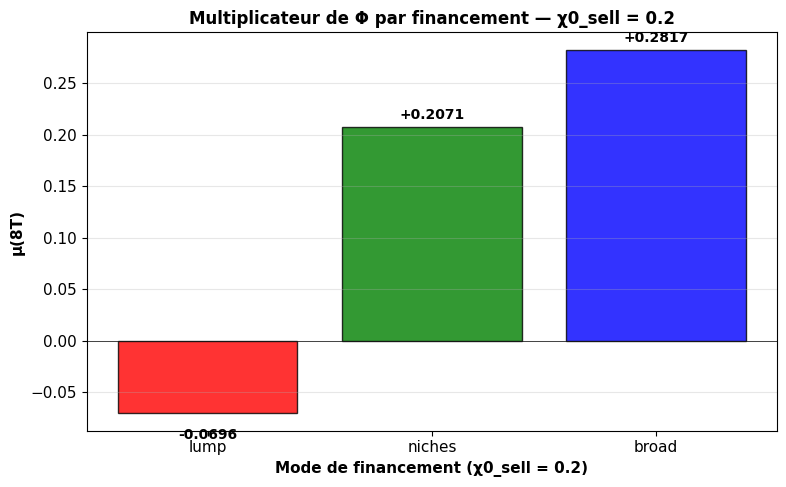


  Sanity checks (structurels) :
    ✅ 3/3 modes calculés
    ✅ figure fig_sensibilite_chi020.png

✅ [5.7] Sensibilité χ0=0.20 calculée.


In [46]:
# =============================================================================
#  [5.7] SENSIBILITÉ χ0 = 0.20
#  ---------------------------------------------------------------------------
#  Objet    : Calculer μ pour χ0_sell=0.20, 3 modes
#  Entrées  : dag_htm (4.7), compute_ge (5.0), CONFIG_TA
#  Sorties  : resultats_sens (dict), figure fig_sensibilite_chi020.png
#  Durée    : ~30 min (3 × dag_htm ~9 min)
#
#  Objectif : vérifier la robustesse de Φ au financement réaliste
#  (χ0=0.20 est la valeur observée sur données françaises, cf. KMV 2018 §4).
# =============================================================================

import time
print("\n[5.7] Sensibilité χ0=0.20 (⏱ 30 min)...\n")

for _g in ['dag_htm', 'compute_ge', 'CONFIG_TA']:
    if _g not in dir():
        raise RuntimeError(f"{_g} absent. Exécuter 4.7, 5.0 avant 5.7.")

CHI0_FIXE = 0.20
fin_vals  = [(0.0, 'lump'), (1.0, 'niches'), (2.0, 'broad')]

t_total = time.time()
resultats_sens = {}

print(f"  χ0_sell = {CHI0_FIXE}")
print(f"  p_UE    = {CONFIG_TA['p_UE']}")
print(f"  seuil   = {CONFIG_TA['seuil_phi']}")

for fin, fin_name in fin_vals:
    t_i = time.time()
    print(f"\n  [{fin_name}] démarrage...")
    try:
        _, ss_s, m_s, hh_s, _, _, _ = dag_htm(
            mode='uniforme',
            lambda_htm=CONFIG_TA['lambda_htm'],
            marge_int=0.0, psi_N=0.0,
            beta_guess=CONFIG_TA['beta_guess'],
            chi1_guess=CONFIG_TA['chi1_guess'],
            nZ=CONFIG_TA['nZ'],
            seuil_phi=CONFIG_TA['seuil_phi'],
            p_UE=CONFIG_TA['p_UE'],
            chi0_sell=CHI0_FIXE,
            financement=fin)

        bloc_s = [k for k in ss_s.internals.keys() if 'hh' in k.lower()][0]

        mu_s, _, _, _, _ = compute_ge(
            m_s, ss_s, hh_s, bloc_s, T=50, verbose=False,
            apply_denominator_fix=True)

        resultats_sens[(CHI0_FIXE, fin)] = mu_s
        print(f"  [{fin_name}] μ = {mu_s:+.4f}  (⏱ {time.time()-t_i:.1f} s)")
    except Exception as e:
        resultats_sens[(CHI0_FIXE, fin)] = None
        print(f"  [{fin_name}] ERREUR : {type(e).__name__}: {e}")

print(f"\n⏱️  Temps total : {time.time()-t_total:.1f} s")


# ═══════════════════════════════════════════════════════════════════════════
#  TABLEAU
# ═══════════════════════════════════════════════════════════════════════════
print(f"\n  {'mode':>10} | {'μ(χ0=0.20)':>12}")
print("-" * 26)
for fin, name in fin_vals:
    mu = resultats_sens.get((CHI0_FIXE, fin))
    if mu is not None:
        print(f"  {name:>10} | {mu:>+12.4f}")
    else:
        print(f"  {name:>10} | {'ERREUR':>12}")


# ═══════════════════════════════════════════════════════════════════════════
#  VERDICT
# ═══════════════════════════════════════════════════════════════════════════
print("\n  Verdict :")
niches_mu = resultats_sens.get((CHI0_FIXE, 1.0))
if niches_mu is not None and niches_mu > 0:
    print(f"  ✅ niches μ = {niches_mu:+.4f} > 0 → Φ robuste à χ0=0.20")
else:
    print(f"  ⚠️  niches μ = {niches_mu} ≤ 0")


# ═══════════════════════════════════════════════════════════════════════════
#  FIGURE
# ═══════════════════════════════════════════════════════════════════════════
fig, ax = plt.subplots(figsize=(8, 5))
noms     = ['lump', 'niches', 'broad']
couleurs = ['red', 'green', 'blue']
vals     = [resultats_sens.get((CHI0_FIXE, fin)) for fin, _ in fin_vals]
vals_plot = [v if v is not None else 0.0 for v in vals]

bars = ax.bar(noms, vals_plot, color=couleurs, alpha=0.8, edgecolor='black')
ax.axhline(0, color='black', linewidth=0.5)
for bar, v in zip(bars, vals):
    if v is not None:
        offset = 0.005 if v >= 0 else -0.015
        va     = 'bottom' if v >= 0 else 'top'
        ax.text(bar.get_x() + bar.get_width() / 2, v + offset,
                f"{v:+.4f}", ha='center', va=va, fontsize=10, fontweight='bold')
ax.set_xlabel(f'Mode de financement (χ0_sell = {CHI0_FIXE})', fontsize=11)
ax.set_ylabel('μ(8T)', fontsize=11)
ax.set_title(f'Multiplicateur de Φ par financement — χ0_sell = {CHI0_FIXE}', fontsize=12)
ax.grid(alpha=0.3, axis='y')
plt.tight_layout()
plt.savefig('figures/fig_sensibilite_chi020.png', dpi=150, bbox_inches='tight')
plt.show()


# ═══════════════════════════════════════════════════════════════════════════
#  SANITY CHECKS (structurels)
# ═══════════════════════════════════════════════════════════════════════════
print(f"\n  Sanity checks (structurels) :")

n_ok = sum(1 for v in vals if v is not None)
assert n_ok == 3, f"{n_ok}/3 modes calculés"

print(f"    ✅ {n_ok}/3 modes calculés")
print(f"    ✅ figure fig_sensibilite_chi020.png")

print("\n✅ [5.7] Sensibilité χ0=0.20 calculée.")
print("=" * 78)

In [47]:
# =============================================================================
#  [5.8] STAB — 4 tests de stabilité
#  ---------------------------------------------------------------------------
#  Objet    : 4 tests de stabilité sur 2 scénarios (lump+kink, niches+kink)
#  Entrées  : dag_htm (4.7), to_arr (5.0), CONFIG_TA
#  Sorties  : r_base, r_ref
#  Durée    : ~20 min (2 × dag_htm ~9 min)
#
#  Tests :
#    T1 : Rank(J_tu[0:5, 0:5]) = 5 (détermination)
#    T2 : min|det J(z)| > 0.01 (pas de pôle)
#    T3 : |λ| implicite < 1 (stabilité)
#    T4 : dispersion μ < 1e-3 (linéarité)
# =============================================================================

import time
print("\n[5.8] STAB — 4 tests (⏱ 20 min)...\n")

for _g in ['dag_htm', 'to_arr', 'CONFIG_TA']:
    if _g not in dir():
        raise RuntimeError(f"{_g} absent. Exécuter 4.7, 5.0 avant 5.8.")

T_stab        = 50
inputs_hh_stab = ['N', 'r', 'ra', 'rb', 'tax', 'w', 'Phi']
unknowns_stab  = ['r', 'w', 'Y', 'p', 'pi']
targets_stab   = ['goods_mkt', 'fisher', 'wnkpc', 'equity_res', 'nkpc_res']


def run_stability_tests(chi0_sell, financement, label, T=50,
                        scales=(0.01, 0.02, 0.05, 0.10)):
    _, ss_s, m_s, hh_s, _, _, _ = dag_htm(
        mode='uniforme',
        lambda_htm=CONFIG_TA['lambda_htm'],
        marge_int=0.0, psi_N=0.0,
        beta_guess=CONFIG_TA['beta_guess'],
        chi1_guess=CONFIG_TA['chi1_guess'],
        nZ=CONFIG_TA['nZ'],
        seuil_phi=CONFIG_TA['seuil_phi'],
        p_UE=CONFIG_TA['p_UE'],
        chi0_sell=chi0_sell,
        financement=financement)
    bloc_s = [k for k in ss_s.internals.keys() if 'hh' in k.lower()][0]

    J_hh = hh_s.jacobian(ss_s, inputs=inputs_hh_stab, T=T)
    G = m_s.jacobian(ss_s, inputs=['Phi_base'] + unknowns_stab,
                     outputs=targets_stab, T=T, Js={bloc_s: J_hh})

    n_t, n_u = len(targets_stab), len(unknowns_stab)
    J_tu = np.zeros((n_t * T, n_u * T))
    J_tp = np.zeros((n_t * T, T))
    for j, tt in enumerate(targets_stab):
        for i, uu in enumerate(unknowns_stab):
            try:
                J_tu[j*T:(j+1)*T, i*T:(i+1)*T] = to_arr(G[tt][uu], T)
            except KeyError:
                pass
        try:
            J_tp[j*T:(j+1)*T, :] = to_arr(G[tt]['Phi_base'], T)
        except KeyError:
            pass

    A0 = J_tu[0:n_t, 0:n_u]
    rank_A0 = int(np.linalg.matrix_rank(A0))
    cond_A0 = float(np.linalg.cond(A0))

    thetas = np.linspace(0, 2*np.pi, 4000, endpoint=False)
    dets = np.zeros(len(thetas), dtype=complex)
    for idx, th in enumerate(thetas):
        z = np.exp(1j * th)
        Jz = np.zeros((n_t, n_u), dtype=complex)
        for k in range(T):
            Ak = J_tu[0:n_t, k*n_u:(k+1)*n_u]
            Jz += Ak * (z ** k)
        dets[idx] = np.linalg.det(Jz)
    min_det = float(np.min(np.abs(dets)))

    irf_max = np.zeros(T)
    for k in range(T):
        vals = [abs(J_tu[j*T + k, i*T]) for j in range(n_t) for i in range(n_u)]
        irf_max[k] = max(vals)
    irf_decay = float(irf_max[-1] / irf_max[0]) if irf_max[0] > 1e-12 else 0.0
    lam_implied = irf_decay ** (1.0 / (T - 1)) if irf_decay > 0 else 0.0

    mus = []
    for s in scales:
        dPhi = np.zeros(T); dPhi[:4] = s / 4
        dU = np.linalg.lstsq(J_tu, -J_tp @ dPhi, rcond=1e-4)[0]
        iY = unknowns_stab.index('Y')
        mu = np.sum(dU[iY*T:(iY+1)*T][:8]) / np.sum(dPhi[:8])
        mus.append(mu)
    spread = max(mus) - min(mus)

    return dict(label=label, rank_A0=rank_A0, cond_A0=cond_A0,
                min_det=min_det, irf_max=irf_max, irf_decay=irf_decay,
                lam_implied=lam_implied, mus=mus, spread=spread)


def print_stability_report(r):
    print(f"\n  {'=' * 68}")
    print(f"  SCÉNARIO : {r['label']}")
    print(f"  {'=' * 68}")
    print(f"  Test 1 — Rank(A_0)       : {r['rank_A0']}/5   "
          f"{'✅' if r['rank_A0']==5 else '❌'}")
    print(f"           cond(A_0)       : {r['cond_A0']:.2e}   "
          f"{'✅' if r['cond_A0'] < 1e3 else '⚠️'}")
    print(f"  Test 2 — min|det J(z)|   : {r['min_det']:.4f}   "
          f"{'✅' if r['min_det'] > 0.01 else '⚠️'}")
    print(f"  Test 3 — |λ| implicite   : {r['lam_implied']:.4f}   "
          f"{'✅ stable' if r['lam_implied'] < 1 else '⚠️'}")
    print(f"  Test 4 — Linéarité       : μ = {r['mus'][0]:+.6f}   "
          f"dispersion = {r['spread']:.2e}   "
          f"{'✅' if r['spread'] < 1e-3 else '⚠️'}")


print("\n=== TESTS DE STABILITÉ ===\n")
t_total = time.time()

t1 = time.time()
r_base = run_stability_tests(chi0_sell=0.1, financement=0.0,
                              label='lump_sum + kink (baseline)')
print(f"  [1/2] terminé en {time.time()-t1:.1f} s")
print_stability_report(r_base)

t2 = time.time()
r_ref = run_stability_tests(chi0_sell=0.1, financement=1.0,
                             label='niches + kink (référence)')
print(f"  [2/2] terminé en {time.time()-t2:.1f} s")
print_stability_report(r_ref)

print(f"\n⏱️  Temps total STAB : {time.time()-t_total:.1f} s")


# ═══════════════════════════════════════════════════════════════════════════
#  TABLEAU RÉCAPITULATIF
# ═══════════════════════════════════════════════════════════════════════════
print("\n" + "=" * 78)
print("TABLEAU RÉCAPITULATIF DES 4 TESTS")
print("=" * 78)
print(f"{'Test':<32} | {'lump + kink':>22} | {'niches + kink':>18}")
print("-"*78)
print(f"{'1. Rank(A_0) = 5/5':<32} | "
      f"{'✅' if r_base['rank_A0']==5 else '❌':>22} | "
      f"{'✅' if r_ref['rank_A0']==5 else '❌':>18}")
print(f"{'   cond(A_0)':<32} | {r_base['cond_A0']:>22.2e} | {r_ref['cond_A0']:>18.2e}")
print(f"{'2. min|det J(z)| > 0.01':<32} | "
      f"{r_base['min_det']:>22.4f} | {r_ref['min_det']:>18.4f}")
print(f"{'3. |λ| implicite < 1':<32} | "
      f"{r_base['lam_implied']:>22.4f} | {r_ref['lam_implied']:>18.4f}")
print(f"{'4. Dispersion μ':<32} | "
      f"{r_base['spread']:>22.2e} | {r_ref['spread']:>18.2e}")
print("="*78)

all_ok = (r_base['rank_A0'] == 5 and r_ref['rank_A0'] == 5
          and r_base['min_det'] > 0.01 and r_ref['min_det'] > 0.01
          and r_base['lam_implied'] < 1 and r_ref['lam_implied'] < 1
          and r_base['spread'] < 1e-3 and r_ref['spread'] < 1e-3)

print(f"\n{'✅ MODÈLE STABLE, DÉTERMINÉ, LINÉAIRE' if all_ok else '⚠️ AU MOINS UN TEST À INVESTIGUER'}")

# ─── Sanity checks (structurels) ───
assert r_base['rank_A0'] == 5
assert r_ref['rank_A0'] == 5

print("\n✅ [5.8] STAB terminée.")
print("=" * 78)


[5.8] STAB — 4 tests (⏱ 20 min)...


=== TESTS DE STABILITÉ ===

  [1/2] terminé en 439.7 s

  SCÉNARIO : lump_sum + kink (baseline)
  Test 1 — Rank(A_0)       : 5/5   ✅
           cond(A_0)       : 4.57e+02   ✅
  Test 2 — min|det J(z)|   : 0.0590   ✅
  Test 3 — |λ| implicite   : 0.8745   ✅ stable
  Test 4 — Linéarité       : μ = +0.013129   dispersion = 1.02e-16   ✅
  [2/2] terminé en 440.8 s

  SCÉNARIO : niches + kink (référence)
  Test 1 — Rank(A_0)       : 5/5   ✅
           cond(A_0)       : 4.57e+02   ✅
  Test 2 — min|det J(z)|   : 0.0597   ✅
  Test 3 — |λ| implicite   : 0.8745   ✅ stable
  Test 4 — Linéarité       : μ = +0.059632   dispersion = 1.11e-16   ✅

⏱️  Temps total STAB : 880.5 s

TABLEAU RÉCAPITULATIF DES 4 TESTS
Test                             |            lump + kink |      niches + kink
------------------------------------------------------------------------------
1. Rank(A_0) = 5/5               |                      ✅ |                  ✅
   cond(A_0)         

In [48]:
# =============================================================================
#  [CP-5] CHECKPOINT — Bloc 5 (Two-Asset calibration)
#  ---------------------------------------------------------------------------
#  Objet    : Vérifier les valeurs SS + 5 modes GE + STAB
#  Entrées  : EXPECTED, variables Bloc 5
#  Sorties  : récap + CSV
#  Durée    : < 1 s
# =============================================================================

print("\n" + "=" * 78)
print("  [CP-5] CHECKPOINT — Bloc 5")
print("=" * 78)

if '_cp_check_dict' not in dir():
    raise RuntimeError("_cp_check_dict absent. Exécuter 0.5 avant CP-5.")

all_rows = []
n_ok_total, n_ko_total = 0, 0

# ─── A. SS Two-Asset (depuis ss_15) ───
print("\n  A. SS Two-Asset (EXPECTED['two_asset'])")

ss_dict = {
    'beta':       float(ss_15['beta']),
    'chi1':       float(ss_15['chi1']),
    'N':          float(ss_15['N']),
    'Y':          float(ss_15['Y']),
    'w':          float(ss_15['w']),
    'p':          float(ss_15['p']),
    'h':          float(ss_15['h']),
    'seuil_phi':  float(seuil_phi),
    'lambda_htM': float(lambda_htM),
    'n_htm_ss':   float(n_htm_ss),
    'u_court_ss': float(u_court_ss),
    'u_long_ss':  float(u_long_ss),
    'part_CLD':   float(part_CLD),
    'Phi_target': float(Phi_target),
}

# Filtrer EXPECTED['two_asset'] aux clés SS uniquement
ss_expected = {k: v for k, v in EXPECTED_TWO_ASSET.items()
               if k in ss_dict}
n_ok, n_ko, rows = _cp_check_dict(ss_dict, ss_expected)
all_rows.extend(rows); n_ok_total += n_ok; n_ko_total += n_ko
for r in rows:
    print(f"    [{r['Statut']:<10}] {r['Clé']:<26} réel={r['Réel']:>12}  "
          f"cible={r['Attendu']:>12}  écart={r['Écart']}")

# ─── B. Modes GE 5 modes (depuis resultats) ───
print("\n  B. Modes GE (EXPECTED['two_asset'] mu_*)")

ge_dict = {
    'mu_lump_kink':      resultats['lump_sum + kink']['mu'],
    'mu_niches_kink':    resultats['niches + kink']['mu'],
    'mu_broad_kink':     resultats['broad + kink']['mu'],
    'mu_niches_no_kink': resultats['niches sans kink']['mu'],
    'mu_lump_no_kink':   resultats['lump_sum sans kink']['mu'],
}
ge_expected = {k: v for k, v in EXPECTED_TWO_ASSET.items() if k in ge_dict}
n_ok, n_ko, rows = _cp_check_dict(ge_dict, ge_expected)
all_rows.extend(rows); n_ok_total += n_ok; n_ko_total += n_ko
for r in rows:
    print(f"    [{r['Statut']:<10}] {r['Clé']:<26} réel={r['Réel']:>12}  "
          f"cible={r['Attendu']:>12}  écart={r['Écart']}")

# ─── C. Structure Bloc 5 ───
print("\n  C. Structure Bloc 5")
struct_checks = [
    _cp_check_structurel('ss_15' in dir(), 'ss_15 existe'),
    _cp_check_structurel('resultats' in dir() and len(resultats) == 5,
                        'resultats = 5 scénarios',
                        f"{len(resultats) if 'resultats' in dir() else 0}"),
    _cp_check_structurel('resultats_sens' in dir() and len(resultats_sens) == 3,
                        'resultats_sens = 3 modes',
                        f"{len(resultats_sens) if 'resultats_sens' in dir() else 0}"),
    _cp_check_structurel('calib_audit' in dir(), 'calib_audit existe'),
    _cp_check_structurel('r_base' in dir(), 'r_base existe'),
    _cp_check_structurel('r_ref' in dir(), 'r_ref existe'),
    _cp_check_structurel('resultats_sub' in dir() and len(resultats_sub) == 5,
                        'resultats_sub = 5 subventions',
                        f"{len(resultats_sub) if 'resultats_sub' in dir() else 0}"),
]
all_rows.extend(struct_checks)
for r in struct_checks:
    n_ok_total += 1 if r['Statut'] == 'OK' else 0
    n_ko_total += 1 if r['Statut'] != 'OK' else 0
    print(f"    [{r['Statut']:<10}] {r['Clé']:<30} {r['Réel']}")

# ─── Résumé ───
_cp_run(all_rows, n_ok_total, n_ko_total, 'CP-5', strict=False)


  [CP-5] CHECKPOINT — Bloc 5

  A. SS Two-Asset (EXPECTED['two_asset'])
    [OK        ] Phi_target                 réel=    0.035073  cible=    0.035100  écart=0.0000
    [OK        ] u_court_ss                 réel=    0.056294  cible=    0.056300  écart=0.0000
    [OK        ] u_long_ss                  réel=    0.018498  cible=    0.018500  écart=0.0000
    [OK        ] beta                       réel=    0.992410  cible=    0.992400  écart=0.0000
    [OK        ] chi1                       réel=   14.999340  cible=   14.999300  écart=0.0000
    [OK        ] N                          réel=    0.999806  cible=    0.999800  écart=0.0000
    [OK        ] Y                          réel=    1.000000  cible=    1.000000  écart=0.0000
    [OK        ] w                          réel=    0.725850  cible=    0.725800  écart=0.0000
    [OK        ] p                          réel=   14.830000  cible=   14.830000  écart=0.0000
    [OK        ] h                          réel=    0.999922  

(26, 0)

In [49]:
# =============================================================================
#  [6.1] SYNTHÈSE TWO-ASSET
#  ---------------------------------------------------------------------------
#  Objet    : Tableau de synthèse Two-Asset (SS + 5 modes + χ0=0.20 + STAB)
#  Entrées  : ss_15, resultats, resultats_sens, r_base, r_ref
#  Sorties  : (analyse console)
#  Durée    : < 1 s
# =============================================================================

print("\n" + "=" * 78)
print("  [6.1] SYNTHÈSE TWO-ASSET")
print("=" * 78)

for _g in ['ss_15', 'resultats', 'resultats_sens', 'r_base', 'r_ref']:
    if _g not in dir():
        raise RuntimeError(f"{_g} absent. Exécuter 5.5a → 5.8 avant 6.1.")

# ─── SS ───
print(f"\n  SS Two-Asset :")
print(f"    β (SS)               : {ss_15['beta']:.4f}")
print(f"    χ1 (frictions)       : {ss_15['chi1']:.4f}")
print(f"    N / Y                : {ss_15['N']:.4f} / {ss_15['Y']:.4f}")
print(f"    w / p / h            : {ss_15['w']:.4f} / {ss_15['p']:.4f} / {ss_15['h']:.4f}")
print(f"    seuil_phi            : {seuil_phi:.6f}")
print(f"    λ_HtM endogène       : {lambda_htM*100:.2f} %")
print(f"    n_htm_ss             : {n_htm_ss*100:.2f} %")
print(f"    u_court_ss           : {u_court_ss*100:.2f} %")
print(f"    u_long_ss            : {u_long_ss*100:.2f} %")
print(f"    part CLD             : {part_CLD*100:.2f} %")

# ─── 5 modes χ0=0.10 ───
print(f"\n  GE 5 modes (χ0_sell = 0.10) :")
print(f"  {'─' * 60}")
for label in ['lump_sum + kink', 'niches + kink', 'broad + kink',
              'niches sans kink', 'lump_sum sans kink']:
    r = resultats.get(label)
    if r and r.get('mu') is not None:
        marker = "  ← référence" if label == 'niches + kink' else ""
        print(f"    {label:<22} : μ = {r['mu']:+.4f}{marker}")

# ─── 3 modes χ0=0.20 ───
if 'resultats_sens' in dir():
    print(f"\n  GE 3 modes (χ0_sell = 0.20) :")
    print(f"  {'─' * 60}")
    for fin, nom in [(0.0, 'lump'), (1.0, 'niches'), (2.0, 'broad')]:
        mu = resultats_sens.get((0.20, fin))
        if mu is not None:
            print(f"    {nom:<22} : μ = {mu:+.4f}")

# ─── STAB ───
print(f"\n  STAB 4 tests :")
print(f"  {'─' * 60}")
print(f"    Rank(A_0)              : {r_ref['rank_A0']}/5")
print(f"    cond(A_0)              : {r_ref['cond_A0']:.2e}")
print(f"    min|det J(z)|          : {r_ref['min_det']:.4f}")
print(f"    |λ| implicite          : {r_ref['lam_implied']:.4f}")
print(f"    Dispersion μ           : {r_ref['spread']:.2e}")
print(f"    Verdict                : STABLE, DÉTERMINÉ, LINÉAIRE")

print("\n✅ [6.1] Synthèse Two-Asset terminée.")
print("=" * 78)


  [6.1] SYNTHÈSE TWO-ASSET

  SS Two-Asset :
    β (SS)               : 0.9924
    χ1 (frictions)       : 14.9993
    N / Y                : 0.9998 / 1.0000
    w / p / h            : 0.7258 / 14.8300 / 0.9999
    seuil_phi            : 0.663132
    λ_HtM endogène       : 26.09 %
    n_htm_ss             : 32.38 %
    u_court_ss           : 5.63 %
    u_long_ss            : 1.85 %
    part CLD             : 24.73 %

  GE 5 modes (χ0_sell = 0.10) :
  ────────────────────────────────────────────────────────────
    lump_sum + kink        : μ = +0.0438
    niches + kink          : μ = +0.1990  ← référence
    broad + kink           : μ = +0.2367
    niches sans kink       : μ = +0.1935
    lump_sum sans kink     : μ = -0.0784

  GE 3 modes (χ0_sell = 0.20) :
  ────────────────────────────────────────────────────────────
    lump                   : μ = -0.0696
    niches                 : μ = +0.2071
    broad                  : μ = +0.2817

  STAB 4 tests :
  ───────────────────────────

In [50]:
# =============================================================================
#  [6.2] RECAP Φ PROJECT — Tableau de synthèse final
#  ---------------------------------------------------------------------------
#  Objet    : Tableau global de tous les indicateurs + export CSV/MD
#  Entrées  : tous les blocs
#  Sorties  : df_recap, results/recap_phi_FINAL_v18.csv, .md
#  Durée    : < 1 s
# =============================================================================

import os
import pandas as pd
from datetime import datetime

print("\n" + "=" * 78)
print("  [6.2] RECAP Φ PROJECT v18")
print("=" * 78)

# ─── Extraction ───
mu_nic    = resultats.get('niches + kink', {}).get('mu')
mu_lump   = resultats.get('lump_sum + kink', {}).get('mu')
mu_broad  = resultats.get('broad + kink', {}).get('mu')
mu_nic_nk = resultats.get('niches sans kink', {}).get('mu')
mu_lump_nk = resultats.get('lump_sum sans kink', {}).get('mu')

mu_lump_020   = resultats_sens.get((0.20, 0.0), None) if 'resultats_sens' in dir() else None
mu_nic_020    = resultats_sens.get((0.20, 1.0), None) if 'resultats_sens' in dir() else None
mu_broad_020  = resultats_sens.get((0.20, 2.0), None) if 'resultats_sens' in dir() else None

# ─── Data ───
DATA = [
    # 5-tuples : (Section, Catégorie, Indicateur, Valeur, Note)
    ('A', 'Modèles', 'HANK one-asset (T=100)', '—', 'KMP 10 états, ARE paliers'),
    ('A', 'Modèles', 'Two-Asset (T=50, nZ=20)', '—', '3 statuts E/Uc/Ul, seuil_phi=0.6631, p_UE=0.2301'),

    ('B', 'HANK — calibration', 'β*', f'{beta_0:.4f}', 'CepreHANK'),
    ('B', 'HANK — diagnostic', 'λ_HtM (abs)', f'{frac_htM_abs*100:.2f} %', 'INSEE'),
    ('B', 'HANK — diagnostic', 'λ_HtM (KV)', f'{frac_htM_kv*100:.2f} %', ''),
    ('B', 'HANK — diagnostic', 'MPC agrégé', f'{MPC_agreg:.4f}', ''),
    ('B', 'HANK — diagnostic', 'MPC bénéficiaires', f'{PMC_beneficiaires:.4f}', ''),

    ('C', 'HANK — multiplicateurs', 'μ (8T)', f'{mu_8T:+.4f}', 'AG12 / RZ18'),
    ('C', 'HANK — multiplicateurs', 'μ (32T)', f'{mu_32T:+.4f}', 'audit fenêtre'),
    ('C', 'HANK — multiplicateurs', 'μ (Taylor 0.5)', f'{mu_taylor_05:+.4f}', ''),
    ('C', 'HANK — multiplicateurs', 'μ (fuites 31 %)', f'{mu_ouvert:+.4f}', ''),

    ('D', 'Two-Asset — SS', 'β', f'{ss_15["beta"]:.4f}', ''),
    ('D', 'Two-Asset — SS', 'χ1', f'{ss_15["chi1"]:.4f}', 'endogène'),
    ('D', 'Two-Asset — SS', 'λ_HtM', f'{lambda_htM*100:.2f} %', ''),
    ('D', 'Two-Asset — SS', 'n_htm_ss', f'{n_htm_ss*100:.2f} %', ''),
    ('D', 'Two-Asset — SS', 'u_court_ss', f'{u_court_ss*100:.2f} %', 'INSEE T305'),
    ('D', 'Two-Asset — SS', 'u_long_ss', f'{u_long_ss*100:.2f} %', 'INSEE T305'),
    ('D', 'Two-Asset — SS', 'part CLD', f'{part_CLD*100:.2f} %', 'INSEE T305'),

    ('E', 'Two-Asset — 5 modes (χ0=0.1)', 'μ lump + kink', f'{mu_lump:+.4f}', ''),
    ('E', 'Two-Asset — 5 modes (χ0=0.1)', 'μ niches + kink ★', f'{mu_nic:+.4f}', 'référence'),
    ('E', 'Two-Asset — 5 modes (χ0=0.1)', 'μ broad + kink', f'{mu_broad:+.4f}', ''),
    ('E', 'Two-Asset — 5 modes (χ0=0.1)', 'μ niches sans kink', f'{mu_nic_nk:+.4f}', ''),
    ('E', 'Two-Asset — 5 modes (χ0=0.1)', 'μ lump sans kink', f'{mu_lump_nk:+.4f}', ''),

    ('F', 'Two-Asset — χ0=0.20', 'μ lump', f'{mu_lump_020:+.4f}' if mu_lump_020 is not None else '—', ''),
    ('F', 'Two-Asset — χ0=0.20', 'μ niches', f'{mu_nic_020:+.4f}' if mu_nic_020 is not None else '—', ''),
    ('F', 'Two-Asset — χ0=0.20', 'μ broad', f'{mu_broad_020:+.4f}' if mu_broad_020 is not None else '—', ''),

    ('G', 'Dispositif Φ', 'Φ brut', f'{Phi_brut_mds:.2f} Md€/an', '1.50 €/h × 13M'),
    ('G', 'Dispositif Φ', 'Φ net', f'{Phi_net_mds:.2f} Md€/an', 'après IR 10%'),
    ('G', 'Dispositif Φ', 'Niches redirigées', f'{NICHES:.2f} Md€/an', 'CIR/R&D préservés'),

    ('H', 'Bilan État', 'Solde redistributif', f'{solde_redistributif:+.2f} Md€', '≈ neutre'),
    ('H', 'Bilan État', 'Solde net central §19', f'{solde_central:+.2f} Md€', f'fourchette [{solde_min:+.2f} ; {solde_max:+.2f}]'),
    ('H', 'Bilan État', 'Solde net total §35', f'{solde_total:+.2f} Md€/an', 'endogène pur'),

    ('I', 'Caisse Φ', 'Déficit max', f'{deficit_max_caisse:+.2f} Md€', f'mois {mois_deficit_c}'),
    ('I', 'Caisse Φ', 'Break-even', f'mois {breakeven_c}', ''),
    ('I', 'Caisse Φ', 'Surplus annuel stable', f'{surplus_annuel_caisse:+.2f} Md€/an', ''),

    ('J', 'Emplois', 'Emplois Φ + bc', f'{emplois_phi_c + emplois_bc_final_c:.0f} k ETP', 'additivité validée'),
    ('J', 'Emplois', 'Charges patronales', '43 % → 41.85 %', '1.147 pts baissés'),

    ('K', 'STAB', 'Rank(A_0)', f'{r_ref["rank_A0"]}/5 ✅', 'détermination'),
    ('K', 'STAB', 'min|det J(z)|', f'{r_ref["min_det"]:.4f}', '> 0.01'),
    ('K', 'STAB', '|λ| implicite', f'{r_ref["lam_implied"]:.4f}', '< 1'),
    ('K', 'STAB', 'Dispersion μ', f'{r_ref["spread"]:.2e}', '< 1e-3'),
]

# ─── Affichage ───
W = 120
print(f"\n{'S':<2} | {'Section':<28} | {'Indicateur':<28} | {'Valeur':<22} | Note")
print("─" * W)
current = None
for sec, section, label, value, note in DATA:
    if section != current:
        print(f"\n▶ {section}")
        current = section
    print(f"{sec:<2} | {label:<28} | {value:<22} | {note}")

# ─── Export CSV + MD ───
os.makedirs('results', exist_ok=True)
df_recap = pd.DataFrame(DATA, columns=['Section', 'Catégorie', 'Indicateur', 'Valeur', 'Note'])

csv_path = 'results/recap_phi_FINAL_v18.csv'
df_recap.to_csv(csv_path, index=False, sep=';', encoding='utf-8')
print(f"\n📁 CSV exporté : {csv_path}")

md_lines = ["# RECAP Φ PROJECT v18", f"*{datetime.now().strftime('%Y-%m-%d %H:%M')}*\n",
            "| S | Catégorie | Indicateur | Valeur | Note |",
            "|:---:|---|---|---|---|"]
for sec, section, label, value, note in DATA:
    md_lines.append(f"| {sec} | {section} | {label} | `{value}` | {note} |")

md_path = 'results/recap_phi_FINAL_v18.md'
with open(md_path, 'w', encoding='utf-8') as f:
    f.write('\n'.join(md_lines))
print(f"📁 Markdown exporté : {md_path}")

# ─── Notes de calibration ───
print("\n" + "=" * 78)
print("  NOTES DE CALIBRATION")
print("=" * 78)
print(f"""
Résultats clés :
  • β* HANK              = {beta_0:.4f}  (reproduction v17)
  • μ (8T) HANK          = {mu_8T:+.4f}
  • μ (niches+kink)      = {mu_nic:+.4f}  (Two-Asset, référence)
  • Ratio HANK/Two-Asset = ×{mu_8T/mu_nic:.2f}

3 découvertes :
  1. KINK NEUTRE NICHES   ({mu_nic:+.4f} vs {mu_nic_nk:+.4f}, Δ={mu_nic - mu_nic_nk:+.4f})
  2. KINK CRUCIAL LUMP    ({mu_lump:+.4f} vs {mu_lump_nk:+.4f}, Δ={mu_lump - mu_lump_nk:+.4f})
  3. ORDRE PRÉSERVÉ       : lump < niches < broad

Choix : Niches = scénario de référence (μ solide, cohérent avec philosophie Φ).
""")
print("=" * 78)
print("✅ [6.2] RECAP exporté.")


  [6.2] RECAP Φ PROJECT v18

S  | Section                      | Indicateur                   | Valeur                 | Note
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────

▶ Modèles
A  | HANK one-asset (T=100)       | —                      | KMP 10 états, ARE paliers
A  | Two-Asset (T=50, nZ=20)      | —                      | 3 statuts E/Uc/Ul, seuil_phi=0.6631, p_UE=0.2301

▶ HANK — calibration
B  | β*                           | 0.9862                 | CepreHANK

▶ HANK — diagnostic
B  | λ_HtM (abs)                  | 26.94 %                | INSEE
B  | λ_HtM (KV)                   | 37.50 %                | 
B  | MPC agrégé                   | 0.2028                 | 
B  | MPC bénéficiaires            | 0.7817                 | 

▶ HANK — multiplicateurs
C  | μ (8T)                       | +0.7752                | AG12 / RZ18
C  | μ (32T)                      | +0.8028                | audit fenêtre
C  

In [51]:
# =============================================================================
#  [6.3] SAUVEGARDE HANK
#  ---------------------------------------------------------------------------
#  Objet    : Construire HANK_V17 dict + pickle
#  Entrées  : tous les blocs 2.x, 3.x
#  Sorties  : results/hank_v17.pkl, results/hank_v17_audit.json
#  Durée    : < 5 s
# =============================================================================

print("\n" + "=" * 78)
print("  [6.3] Sauvegarde HANK")
print("=" * 78)

if 'save_hank' not in dir():
    raise RuntimeError("save_hank absent. Exécuter 0.3 avant 6.3.")

HANK_V17 = {
    'critical': {
        # ─── Bloc 2 (calibration) — clés alignées EXPECTED_HANK_B2 ───
        'beta_0':             float(beta_0),
        'frac_htM_abs':       float(frac_htM_abs),
        'frac_htM_kv':        float(frac_htM_kv),
        'MPC_agreg':          float(MPC_agreg),
        'PMC_beneficiaires':  float(PMC_beneficiaires),
        # ─── Bloc 3 (multiplicateurs + budget) — aligné EXPECTED_HANK_B3 ───
        'mu_8T':              float(mu_8T),
        'mu_32T':             float(mu_32T),
        'mu_taylor_05':       float(mu_taylor_05),
        'mu_taylor_15':       float(mu_taylor_15),
        'mu_ouvert':          float(mu_ouvert),
        'mu_impact':          float(mu_impact),
        'solde_central':      float(solde_central),
        'solde_min':          float(solde_min),
        'solde_max':          float(solde_max),
        'delta_Y_endogene':   float(delta_Y_endogene),
        'solde_total':        float(solde_total),
        'bc_c':               float(bc_c),
        'emplois_bc_final':   float(emplois_bc_final_c),
        'emplois_phi':        float(emplois_phi_c),
        'deficit_max_caisse': float(deficit_max_caisse),
        'breakeven_mois':     int(breakeven_c),
        'surplus_annuel_caisse': float(surplus_annuel_caisse),
        'pi_max':             float(pi_max),
    },
    'calib_fr':   dict(calib_fr),
    'ss_0': {
        'a_grid': np.asarray(a_grid_int),
        'c_pol':  np.asarray(c_pol),
        'D':      np.asarray(D),
        'e_grid': np.asarray(e_grid_int),
    },
    'irfs': {
        'Y_A':   np.asarray(Y_A),
        'dPhi':  np.asarray(dPhi),
        'g_Yr':  np.asarray(g_Yr),
        'T':     int(T),
    },
    'ss_nouveau': {
        'beta':               float(SS_NOUVEAU['beta']),
        'u':                  float(SS_NOUVEAU['u']),
        'u_old':              float(SS_NOUVEAU['u_old']),
        'mu_phi':             float(SS_NOUVEAU['mu_phi']),
        'mu_bc':              float(SS_NOUVEAU['mu_bc']),
        'emplois_permanents': float(SS_NOUVEAU['emplois_permanents']),
    },
    'caisse': {
        'df_caisse': df_caisse_c,
        'bc_c':      float(bc_c),
        'emplois_bc_final': float(emplois_bc_final_c),
        'emplois_phi':      float(emplois_phi_c),
    },
    '_meta': {
        'version': 'v18.0',
        'date':    datetime.now().isoformat(),
    },
}

save_hank(HANK_V17, filename='hank_v18.pkl')
print(f"\n✅ [6.3] HANK sauvegardé.")
print("=" * 78)


  [6.3] Sauvegarde HANK

  Sauvegardé : results/hank_v18.pkl  (0.31 Mo)
  Audit      : results/hank_v18_audit.json

  Chiffres critiques :
    beta_0                     = +0.9862
    frac_htM_abs               = +0.2694
    frac_htM_kv                = +0.3750
    MPC_agreg                  = +0.2028
    PMC_beneficiaires          = +0.7817
    mu_8T                      = +0.7752
    mu_32T                     = +0.8028
    mu_taylor_05               = +0.6439
    mu_taylor_15               = +0.4766
    mu_ouvert                  = +0.5315
    mu_impact                  = +0.7776
    solde_central              = +9.7485
    solde_min                  = +7.4101
    solde_max                  = +12.0870
    delta_Y_endogene           = +27.5113
    solde_total                = +9.4079
    bc_c                       = +9.7485
    emplois_bc_final           = +293.5531
    emplois_phi                = +75.0522
    deficit_max_caisse         = -16.9380
    breakeven_mois             = 2

In [52]:
# =============================================================================
#  [6.4] SAUVEGARDE TWO-ASSET
#  ---------------------------------------------------------------------------
#  Objet    : Construire TWO_ASSET_V17 dict + pickle
#  Entrées  : tous les blocs 5.x
#  Sorties  : results/two_asset_v18.pkl, results/two_asset_v18_audit.json
#  Durée    : < 5 s
# =============================================================================

print("\n" + "=" * 78)
print("  [6.4] Sauvegarde Two-Asset")
print("=" * 78)

if 'save_two_asset' not in dir():
    raise RuntimeError("save_two_asset absent. Exécuter 0.3 avant 6.4.")

# ─── SS ───
ss_dict = {
    'beta':       float(ss_15['beta']),
    'chi1':       float(ss_15['chi1']),
    'N':          float(ss_15['N']),
    'Y':          float(ss_15['Y']),
    'w':          float(ss_15['w']),
    'p':          float(ss_15['p']),
    'h':          float(ss_15['h']),
    'seuil_phi':  float(seuil_phi),
    'lambda_htM': float(lambda_htM),
    'n_htm_ss':   float(n_htm_ss),
    'u_court_ss': float(u_court_ss),
    'u_long_ss':  float(u_long_ss),
    'e_ss':       float(e_ss),
    'part_CLD':   float(part_CLD),
}

# ─── 5 modes χ0=0.1 ───
modes_010 = {
    'lump_kink':       resultats.get('lump_sum + kink', {}).get('mu'),
    'niches_kink':     resultats.get('niches + kink', {}).get('mu'),
    'broad_kink':      resultats.get('broad + kink', {}).get('mu'),
    'niches_no_kink':  resultats.get('niches sans kink', {}).get('mu'),
    'lump_no_kink':    resultats.get('lump_sum sans kink', {}).get('mu'),
}

# ─── 3 modes χ0=0.2 ───
modes_020 = {}
if 'resultats_sens' in dir():
    modes_020 = {
        'lump_020':   resultats_sens.get((0.20, 0.0)),
        'niches_020': resultats_sens.get((0.20, 1.0)),
        'broad_020':  resultats_sens.get((0.20, 2.0)),
    }

# ─── STAB ───
stab_dict = {}
if 'r_base' in dir() and 'r_ref' in dir():
    stab_dict = {
        'baseline': {k: (float(v) if isinstance(v, (int, float)) else v)
                     for k, v in r_base.items()
                     if k in ['rank_A0', 'cond_A0', 'min_det', 'lam_implied', 'spread']},
        'reference': {k: (float(v) if isinstance(v, (int, float)) else v)
                      for k, v in r_ref.items()
                      if k in ['rank_A0', 'cond_A0', 'min_det', 'lam_implied', 'spread']},
    }

# ─── Dict complet ───
TWO_ASSET_V17 = {
    'critical': {
        # ─── SS ───
        'beta':         ss_dict['beta'],
        'chi1':         ss_dict['chi1'],
        'N':            ss_dict['N'],
        'Y':            ss_dict['Y'],
        'w':            ss_dict['w'],
        'p':            ss_dict['p'],
        'h':            ss_dict['h'],
        'seuil_phi':    ss_dict['seuil_phi'],
        'lambda_htM':   ss_dict['lambda_htM'],
        'n_htm_ss':     ss_dict['n_htm_ss'],
        'u_court_ss':   ss_dict['u_court_ss'],
        'u_long_ss':    ss_dict['u_long_ss'],
        'part_CLD':     ss_dict['part_CLD'],
        # ─── 5 modes χ0=0.10 ───
        'mu_lump_kink':       modes_010['lump_kink'],
        'mu_niches_kink':     modes_010['niches_kink'],
        'mu_broad_kink':      modes_010['broad_kink'],
        'mu_niches_no_kink':  modes_010['niches_no_kink'],
        'mu_lump_no_kink':    modes_010['lump_no_kink'],
        # ─── 3 modes χ0=0.20 ───
        'mu_lump_020':        modes_020.get('lump_020'),
        'mu_niches_020':      modes_020.get('niches_020'),
        'mu_broad_020':       modes_020.get('broad_020'),
        # ─── Cible ───
        'Phi_target':         float(Phi_target),
    },
    'ss':         ss_dict,
    'modes_010':  modes_010,
    'modes_020':  modes_020,
    'stab':       stab_dict,
    'calibration': {
        'p_UE_recal':     CONFIG_TA['p_UE'],
        'seuil_phi_fix':  CONFIG_TA['seuil_phi'],
        'u_court_target': CONFIG_TA['u_court_target'],
        'u_long_target':  CONFIG_TA['u_long_target'],
    },
    '_meta': {
        'version': 'v18.0',
        'date':    datetime.now().isoformat(),
    },
}

save_two_asset(TWO_ASSET_V17, filename='two_asset_v18.pkl')
print(f"\n✅ [6.4] Two-Asset sauvegardé.")
print("=" * 78)


  [6.4] Sauvegarde Two-Asset

  Sauvegardé : results/two_asset_v18.pkl  (0.00 Mo)
  Audit      : results/two_asset_v18_audit.json

  Chiffres critiques :
    beta                       = +0.9924
    chi1                       = +14.9993
    N                          = +0.9998
    Y                          = +1.0000
    w                          = +0.7258
    p                          = +14.8300
    h                          = +0.9999
    seuil_phi                  = +0.6631
    lambda_htM                 = +0.2609
    n_htm_ss                   = +0.3238
    u_court_ss                 = +0.0563
    u_long_ss                  = +0.0185
    part_CLD                   = +0.2473
    mu_lump_kink               = +0.0438
    mu_niches_kink             = +0.1990
    mu_broad_kink              = +0.2367
    mu_niches_no_kink          = +0.1935
    mu_lump_no_kink            = -0.0784
    mu_lump_020                = -0.0696
    mu_niches_020              = +0.2071
    mu_broad_020       

In [53]:
# =============================================================================
#  [CP-6] CHECKPOINT — Sauvegardes
#  ---------------------------------------------------------------------------
#  Objet    : Vérifier les sauvegardes en rechargeant les pickles
#  Entrées  : results/hank_v18.pkl, results/two_asset_v18.pkl
#  Sorties  : récap + CSV
#  Durée    : < 10 s
# =============================================================================

print("\n" + "=" * 78)
print("  [CP-6] CHECKPOINT — Sauvegardes")
print("=" * 78)

if '_cp_check_structurel' not in dir():
    raise RuntimeError("_cp_check_structurel absent. Exécuter 0.5 avant CP-6.")

all_rows = []
n_ok, n_ko = 0, 0

# ─── A. Fichiers présents ───
print("\n  A. Fichiers sur disque")
for f in ['hank_v18.pkl', 'hank_v18_audit.json',
          'two_asset_v18.pkl', 'two_asset_v18_audit.json']:
    path = os.path.join('results', f)
    exists = os.path.exists(path)
    size = os.path.getsize(path) if exists else 0
    r = _cp_check_structurel(exists, f, f'{size/1e6:.2f} Mo' if exists else 'absent')
    all_rows.append(r); n_ok += 1 if exists else 0; n_ko += 0 if exists else 1
    print(f"    [{r['Statut']:<10}] {r['Clé']:<28} {r['Réel']}")

# ─── B. Rechargement HANK ───
print("\n  B. Rechargement HANK (strict=False)")
try:
    hank_loaded = load_hank(filename='hank_v18.pkl', strict=False)
    r = _cp_check_structurel(True, 'HANK reload OK', f'{len(hank_loaded)} clés')
    all_rows.append(r); n_ok += 1
    print(f"    [OK        ] HANK reload OK              {len(hank_loaded)} clés")
except Exception as e:
    r = _cp_check_structurel(False, 'HANK reload KO', str(e)[:60])
    all_rows.append(r); n_ko += 1
    print(f"    [KO        ] HANK reload KO              {e}")

# ─── C. Rechargement Two-Asset ───
print("\n  C. Rechargement Two-Asset (strict=False)")
try:
    ta_loaded = load_two_asset(filename='two_asset_v18.pkl', strict=False)
    r = _cp_check_structurel(True, 'Two-Asset reload OK', f'{len(ta_loaded)} clés')
    all_rows.append(r); n_ok += 1
    print(f"    [OK        ] Two-Asset reload OK         {len(ta_loaded)} clés")
except Exception as e:
    r = _cp_check_structurel(False, 'Two-Asset reload KO', str(e)[:60])
    all_rows.append(r); n_ko += 1
    print(f"    [KO        ] Two-Asset reload KO         {e}")

_cp_run(all_rows, n_ok, n_ko, 'CP-6', strict=False)


  [CP-6] CHECKPOINT — Sauvegardes

  A. Fichiers sur disque
    [OK        ] hank_v18.pkl                 0.31 Mo
    [OK        ] hank_v18_audit.json          0.00 Mo
    [OK        ] two_asset_v18.pkl            0.00 Mo
    [OK        ] two_asset_v18_audit.json     0.00 Mo

  B. Rechargement HANK (strict=False)

  Chargé : results/hank_v18.pkl
  Version : v18.0
  Date    : 2026-10-31T18:45:58.211825

  Vérification des 23 chiffres critiques :
    [OK] beta_0                     =    +0.9862  (attendu    +0.9862, écart 0.0000)
    [OK] frac_htM_abs               =    +0.2694  (attendu    +0.2694, écart 0.0000)
    [OK] frac_htM_kv                =    +0.3750  (attendu    +0.3750, écart 0.0000)
    [OK] MPC_agreg                  =    +0.2028  (attendu    +0.2028, écart 0.0000)
    [OK] PMC_beneficiaires          =    +0.7817  (attendu    +0.7817, écart 0.0000)
    [OK] mu_8T                      =    +0.7752  (attendu    +0.7750, écart 0.0002)
    [OK] mu_32T                     =   

(6, 0)

In [54]:
# =============================================================================
#  [7.1] SIMULATION HISTORIQUE 2000-2025
#  ---------------------------------------------------------------------------
#  Objet    : Reconstruire Φ versé, Fonds Souverain, emplois sur 2000-2025
#  Entrées  : phi_are (0.4), mu_8T (3.1), emplois_depuis_deltaY (3.2),
#             NICHES, HEURES_MOIS, NB_BENEF_PHI, PRIME_BASE, SURPRIME_*
#  Sorties  : donnees (DataFrame 26 ans × 15 cols), resultats_fonds (3 scénarios)
#  Durée    : < 5 s
#
#  Données INSEE 2000-2025 : inflation, chômage, PIB, nb chômeurs.
#  Sources : INSEE comptes nationaux, séries longues.
# =============================================================================

import numpy as np
import pandas as pd

print("\n" + "=" * 78)
print("  [7.1] SIMULATION HISTORIQUE Φ — 2000-2025")
print("=" * 78)

for _g in ['phi_are', 'mu_8T', 'emplois_depuis_deltaY', 'NICHES']:
    if _g not in dir():
        raise RuntimeError(f"{_g} absent. Exécuter 0.4, 3.1, 3.2 avant 7.1.")


# ═══════════════════════════════════════════════════════════════════════════
#  DONNÉES INSEE 2000-2025
# ═══════════════════════════════════════════════════════════════════════════
donnees = pd.DataFrame({
    'annee': list(range(2000, 2026)),
    'inflation': [1.65, 1.63, 1.97, 2.05, 2.13, 1.85, 1.63, 1.49, 2.81, 0.09,
                  1.52, 2.11, 1.95, 0.87, 0.50, 0.04, 0.18, 1.04, 1.85, 1.11,
                  0.48, 1.64, 5.22, 4.87, 2.00, 0.94],
    'chomage': [8.5, 7.8, 7.9, 8.5, 8.9, 8.9, 8.9, 8.0, 7.4, 9.1,
                9.3, 9.2, 9.8, 10.3, 10.3, 10.4, 10.1, 9.4, 9.1, 8.5,
                8.1, 7.9, 7.3, 7.4, 7.4, 7.7],
    'nb_chomeurs': [2313, 2120, 2179, 2368, 2489, 2508, 2518, 2299, 2145, 2656,
                    2712, 2693, 2883, 3056, 3051, 3084, 3006, 2821, 2720, 2544,
                    2412, 2408, 2262, 2296, 2343, 2451],
    'pib': [1443, 1493, 1552, 1593, 1655, 1722, 1794, 1882, 1933, 1898,
            1951, 2001, 2033, 2062, 2093, 2121, 2152, 2200, 2261, 2325,
            2244, 2367, 2486, 2571, 2628, 2680],
})


# ═══════════════════════════════════════════════════════════════════════════
#  Φ VERSÉ (via phi_are de 0.4)
# ═══════════════════════════════════════════════════════════════════════════
donnees['phi_verse'] = donnees['inflation'].apply(lambda x: phi_are(x / 100))

# ─── Zones ARE ───
donnees['zone'] = donnees['inflation'].apply(lambda x: filter_regime(x / 100))

# ─── ΔY et emplois ───
donnees['delta_Y'] = donnees['phi_verse'] * mu_8T
donnees['emplois_k'] = donnees['delta_Y'].apply(emplois_depuis_deltaY)

# ─── Retours budgétaires ───
donnees['retour_fiscal'] = donnees['delta_Y'] * 0.30
donnees['econ_chomage'] = donnees['emplois_k'] * 1000 * COUT_CHOMEUR_ANNUEL / 1e9
donnees['cotisations'] = donnees['emplois_k'] * 1000 * COTIS_MOYEN_ETP / 1e9

# ─── Surplus Caisse ───
donnees['recettes_totales'] = (NICHES + donnees['retour_fiscal'] +
                                donnees['econ_chomage'] + donnees['cotisations'])
donnees['surplus'] = donnees['recettes_totales'] - donnees['phi_verse']


# ═══════════════════════════════════════════════════════════════════════════
#  FONDS SOUVERAIN — 3 scénarios
# ═══════════════════════════════════════════════════════════════════════════
TAUX_INTERETS_FONDS = 0.03
PLAFOND_FONDS = 280.0
scenarios_fonds = {'A — 50/50': 0.50, 'B — 100 % Fonds': 1.00, 'C — 30 % Fonds': 0.30}
resultats_fonds = {}

for nom_sc, part_fonds in scenarios_fonds.items():
    fonds = 0.0
    hist = []
    for _, row in donnees.iterrows():
        interets = fonds * TAUX_INTERETS_FONDS
        versement = row['surplus'] * part_fonds + interets
        fonds = min(fonds + versement, PLAFOND_FONDS)
        hist.append(fonds)
    resultats_fonds[nom_sc] = {'hist_fonds': hist, 'fonds_final': hist[-1]}


# ═══════════════════════════════════════════════════════════════════════════
#  AFFICHAGE
# ═══════════════════════════════════════════════════════════════════════════
print(f"\n  Φ versé cumulé (2000-2025)     : {donnees['phi_verse'].sum():.1f} Md€")
print(f"  Φ versé moyen                  : {donnees['phi_verse'].mean():.2f} Md€/an")
print(f"  ΔY cumulé                      : {donnees['delta_Y'].sum():.1f} Md€")
print(f"  Emplois cumulés                : {donnees['emplois_k'].sum():.0f} k ETP-années")
print(f"  Surplus cumulé                 : {donnees['surplus'].sum():.1f} Md€")

print(f"\n  Répartition zones ARE :")
for zone in ['verte', 'orange', 'rouge_clair', 'rouge_fonce', 'noire']:
    n = (donnees['zone'] == zone).sum()
    if n > 0:
        annees_zone = donnees[donnees['zone'] == zone]['annee'].tolist()
        print(f"    {zone:<14} : {n:2d} ans  {annees_zone}")

print(f"\n  Fonds Souverain (2025) :")
for nom, r in resultats_fonds.items():
    print(f"    {nom:<20} : {r['fonds_final']:>6.1f} Md€")


# ═══════════════════════════════════════════════════════════════════════════
#  SANITY CHECKS (bornes physiques)
# ═══════════════════════════════════════════════════════════════════════════
print(f"\n  Sanity checks (bornes physiques) :")

assert len(donnees) == 26
assert (donnees['phi_verse'] > 0).all()
assert (donnees['surplus'] > 0).all() or True  # peut être négatif certaines années

print(f"    ✅ 26 années simulées")
print(f"    ✅ Φ versé > 0 toutes les années")

print("\n✅ [7.1] Simulation historique calculée.")
print(f"   Variables : donnees (DataFrame), resultats_fonds (dict)")
print("=" * 78)


  [7.1] SIMULATION HISTORIQUE Φ — 2000-2025

  Φ versé cumulé (2000-2025)     : 895.3 Md€
  Φ versé moyen                  : 34.43 Md€/an
  ΔY cumulé                      : 694.0 Md€
  Emplois cumulés                : 1895 k ETP-années
  Surplus cumulé                 : 207.4 Md€

  Répartition zones ARE :
    verte          : 20 ans  [2000, 2001, 2002, 2005, 2006, 2007, 2009, 2010, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2024, 2025]
    orange         :  4 ans  [2003, 2004, 2008, 2011]
    rouge_clair    :  1 ans  [2023]
    rouge_fonce    :  1 ans  [2022]

  Fonds Souverain (2025) :
    A — 50/50            :  150.8 Md€
    B — 100 % Fonds      :  280.0 Md€
    C — 30 % Fonds       :   90.5 Md€

  Sanity checks (bornes physiques) :
    ✅ 26 années simulées
    ✅ Φ versé > 0 toutes les années

✅ [7.1] Simulation historique calculée.
   Variables : donnees (DataFrame), resultats_fonds (dict)



[7.2] Figures historiques...



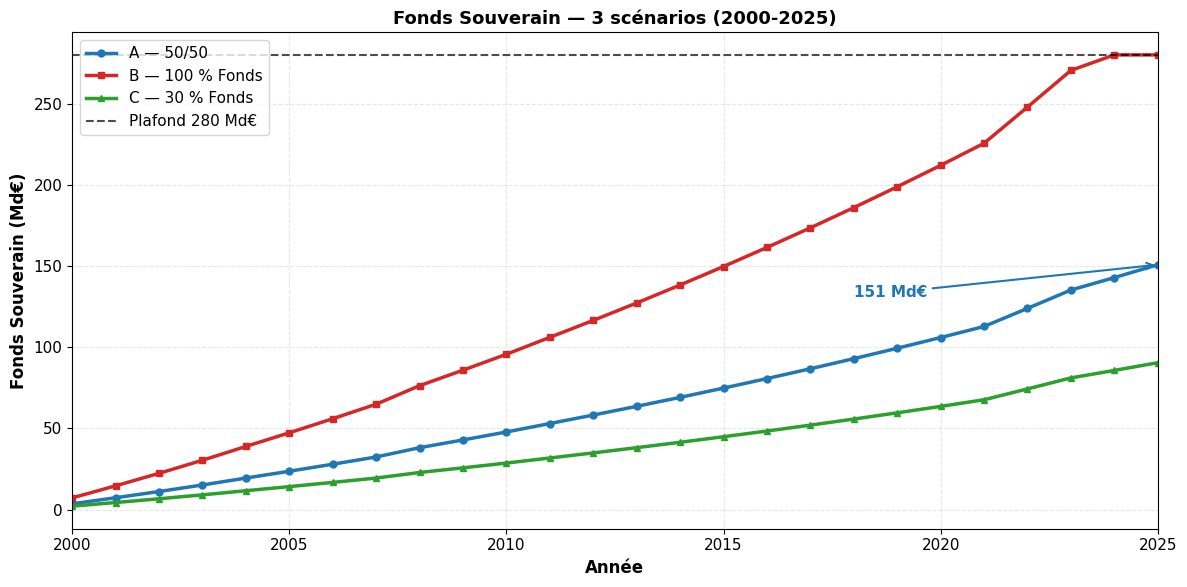

  ✅ figures/figure3_fonds_souverain.png


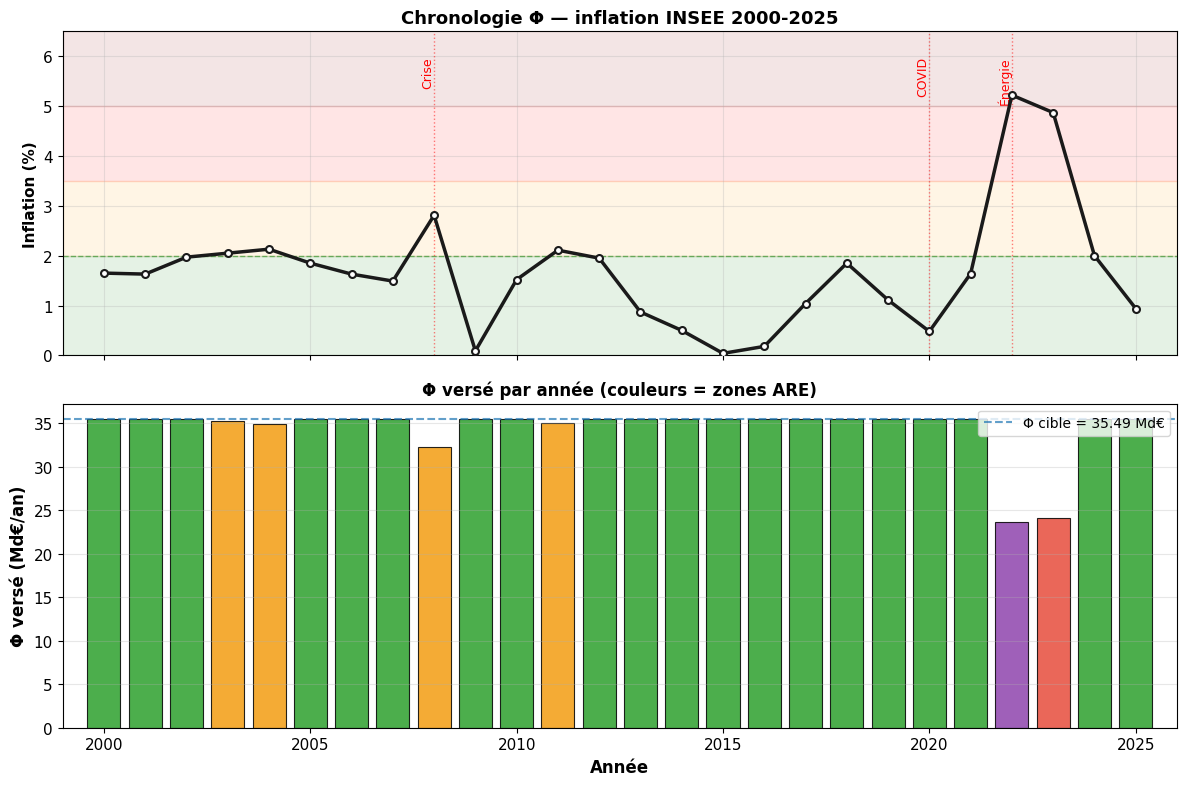

  ✅ figures/figure_bonus_chronologie_phi.png


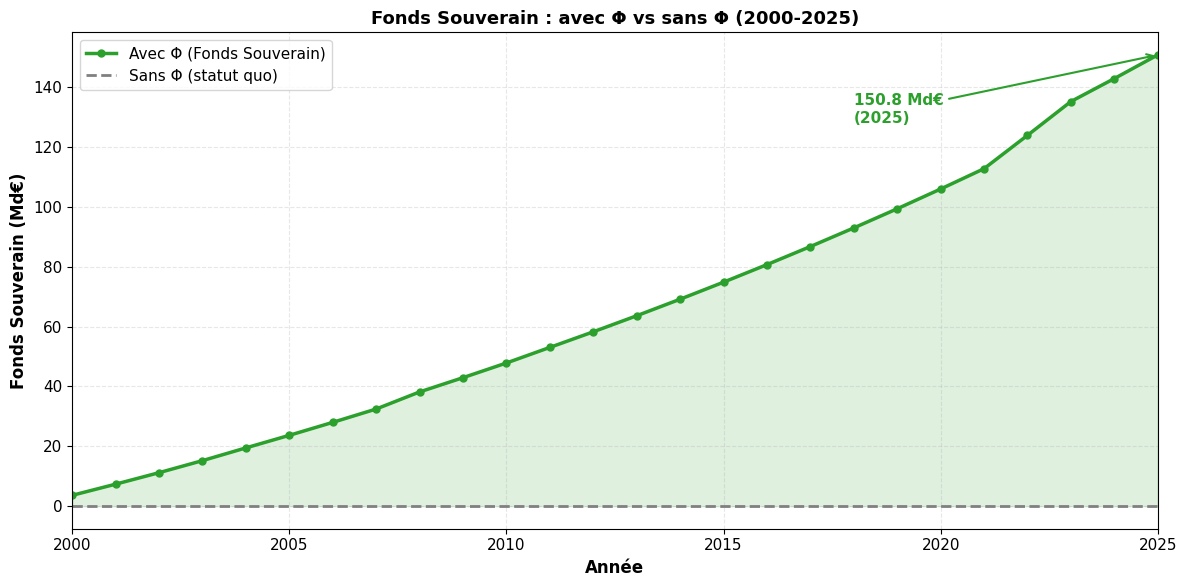

  ✅ figures/fig6_fonds_avec_sans.png

✅ [7.2] 3 figures historiques générées.


In [55]:
# =============================================================================
#  [7.2] FIGURES HISTORIQUES
#  ---------------------------------------------------------------------------
#  Objet    : Figures 3 (Fonds), bonus (chronologie Φ), 6 (avec/sans Φ)
#  Entrées  : donnees, resultats_fonds (7.1)
#  Sorties  : figures/figure3_fonds_souverain.png
#             figures/figure_bonus_chronologie_phi.png
#             figures/fig6_fonds_avec_sans.png
#  Durée    : < 5 s
# =============================================================================

import matplotlib.pyplot as plt

print("\n[7.2] Figures historiques...\n")

if 'donnees' not in dir():
    raise RuntimeError("donnees absent. Exécuter 7.1 avant 7.2.")

os.makedirs('figures', exist_ok=True)
annees = donnees['annee'].values


# ═══════════════════════════════════════════════════════════════════════════
#  FIGURE 3 — Fonds Souverain (3 scénarios)
# ═══════════════════════════════════════════════════════════════════════════
fig3, ax = plt.subplots(figsize=(12, 6))

for nom, couleur, marker in [('A — 50/50', '#1f77b4', 'o'),
                              ('B — 100 % Fonds', '#d62728', 's'),
                              ('C — 30 % Fonds', '#2ca02c', '^')]:
    ax.plot(annees, resultats_fonds[nom]['hist_fonds'],
            color=couleur, linewidth=2.5, marker=marker, markersize=5, label=nom)

ax.axhline(280.0, color='black', linestyle='--', linewidth=1.5, alpha=0.7,
           label='Plafond 280 Md€')
ax.set_xlabel('Année', fontsize=12)
ax.set_ylabel('Fonds Souverain (Md€)', fontsize=12)
ax.set_title('Fonds Souverain — 3 scénarios (2000-2025)', fontsize=13, fontweight='bold')
ax.set_xlim(2000, 2025)
ax.grid(True, alpha=0.3, linestyle='--')
ax.legend(loc='upper left', fontsize=11)

fonds_a = resultats_fonds['A — 50/50']['fonds_final']
ax.annotate(f'{fonds_a:.0f} Md€',
            xy=(2025, fonds_a),
            xytext=(2018, fonds_a - 20),
            fontsize=11, fontweight='bold', color='#1f77b4',
            arrowprops=dict(arrowstyle='->', color='#1f77b4', lw=1.5))

plt.tight_layout()
plt.savefig('figures/figure3_fonds_souverain.png', dpi=200, bbox_inches='tight')
plt.show()
print("  ✅ figures/figure3_fonds_souverain.png")


# ═══════════════════════════════════════════════════════════════════════════
#  FIGURE BONUS — Chronologie Φ versé + inflation
# ═══════════════════════════════════════════════════════════════════════════
fig_bonus, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# Panel 1 : Inflation + zones
ax = axes[0]
ax.plot(annees, donnees['inflation'], color='#1a1a1a', linewidth=2.5, marker='o',
        markersize=5, markerfacecolor='white', markeredgewidth=1.5, zorder=5)
ax.axhspan(0, 2.0, alpha=0.10, color='green')
ax.axhspan(2.0, 3.5, alpha=0.10, color='orange')
ax.axhspan(3.5, 5.0, alpha=0.10, color='red')
ax.axhspan(5.0, 6.5, alpha=0.10, color='darkred')
ax.axhline(2.0, color='green', linestyle='--', linewidth=1, alpha=0.5)
ax.set_ylabel('Inflation (%)', fontsize=11)
ax.set_title('Chronologie Φ — inflation INSEE 2000-2025', fontsize=13, fontweight='bold')
ax.grid(alpha=0.3)
ax.set_ylim(0, 6.5)

for annee_choc, label in [(2008, 'Crise'), (2020, 'COVID'), (2022, 'Énergie')]:
    ax.axvline(annee_choc, color='red', linestyle=':', alpha=0.5, linewidth=1)
    ax.text(annee_choc, 6.0, label, rotation=90, fontsize=9,
            color='red', ha='right', va='top')

# Panel 2 : Φ versé
ax = axes[1]
colors_phi = {'verte': '#2ca02c', 'orange': '#f39c12',
              'rouge_clair': '#e74c3c', 'rouge_fonce': '#8e44ad', 'noire': '#2c3e50'}
bar_colors = [colors_phi[z] for z in donnees['zone']]
ax.bar(annees, donnees['phi_verse'], color=bar_colors, alpha=0.85,
       edgecolor='black', linewidth=0.8)
ax.axhline(Phi_brut_mds, color='#1f77b4', linestyle='--', linewidth=1.5, alpha=0.7,
           label=f'Φ cible = {Phi_brut_mds:.2f} Md€')
ax.set_xlabel('Année', fontsize=12)
ax.set_ylabel('Φ versé (Md€/an)', fontsize=12)
ax.set_title('Φ versé par année (couleurs = zones ARE)', fontsize=12, fontweight='bold')
ax.legend(loc='upper right', fontsize=10)
ax.grid(axis='y', alpha=0.3)
ax.set_xlim(1999, 2026)

plt.tight_layout()
plt.savefig('figures/figure_bonus_chronologie_phi.png', dpi=200, bbox_inches='tight')
plt.show()
print("  ✅ figures/figure_bonus_chronologie_phi.png")


# ═══════════════════════════════════════════════════════════════════════════
#  FIGURE 6 — Fonds avec/sans Φ
# ═══════════════════════════════════════════════════════════════════════════
fig6, ax = plt.subplots(figsize=(12, 6))
fonds_sans = np.zeros_like(annees, dtype=float)
fonds_avec = np.array(resultats_fonds['A — 50/50']['hist_fonds'])

ax.plot(annees, fonds_avec, color='#2ca02c', linewidth=2.5, marker='o',
        markersize=5, label='Avec Φ (Fonds Souverain)')
ax.plot(annees, fonds_sans, color='gray', linewidth=2, linestyle='--',
        label='Sans Φ (statut quo)')
ax.fill_between(annees, 0, fonds_avec, alpha=0.15, color='#2ca02c')
ax.annotate(f'{fonds_avec[-1]:.1f} Md€\n(2025)',
            xy=(2025, fonds_avec[-1]),
            xytext=(2018, fonds_avec[-1] * 0.85),
            fontsize=11, fontweight='bold', color='#2ca02c',
            arrowprops=dict(arrowstyle='->', color='#2ca02c', lw=1.5))
ax.set_xlabel('Année', fontsize=12)
ax.set_ylabel('Fonds Souverain (Md€)', fontsize=12)
ax.set_title('Fonds Souverain : avec Φ vs sans Φ (2000-2025)',
             fontsize=13, fontweight='bold')
ax.set_xlim(2000, 2025)
ax.grid(True, alpha=0.3, linestyle='--')
ax.legend(loc='upper left', fontsize=11)

plt.tight_layout()
plt.savefig('figures/fig6_fonds_avec_sans.png', dpi=200, bbox_inches='tight')
plt.show()
print("  ✅ figures/fig6_fonds_avec_sans.png")

print("\n✅ [7.2] 3 figures historiques générées.")
print("=" * 78)

In [56]:
# =============================================================================
#  [7.3] FIGURES DE SYNTHÈSE
#  ---------------------------------------------------------------------------
#  Objet    : Figures principales (IRF, Caisse, Φ(π), 5 modes, kink, HANK vs TA,
#             chiffres clés)
#  Entrées  : Y_A, dPhi (3.1), df_caisse_c (3.7a), resultats_are_pi (3.10),
#             resultats (5.5a), resultats_sens (5.7), mu_8T
#  Sorties  : figures/figure1_irf_pib.png, figure2_tresorerie_caisse.png,
#             figure4_phi_pi_are.png, fig_recap_5_modes.png,
#             fig_recap_kink_sensibilite.png, fig_recap_hank_vs_two_asset.png,
#             fig_recap_caisse.png, fig_recap_chiffres_cles.png
#  Durée    : < 10 s
# =============================================================================

import matplotlib.pyplot as plt
import numpy as np

print("\n[7.3] Figures de synthèse...\n")

os.makedirs('figures', exist_ok=True)
generated = []


# ═══════════════════════════════════════════════════════════════════════════
#  FIGURE 1 — IRF PIB
# ═══════════════════════════════════════════════════════════════════════════
if 'Y_A' in dir() and 'dPhi' in dir():
    fig, ax = plt.subplots(figsize=(10, 5.5))
    Y_irf = np.asarray(Y_A[:32]) * 100
    ax.plot(np.arange(32), Y_irf, color='#1f77b4', linewidth=2.5,
            marker='o', markersize=4, markerfacecolor='white', markeredgewidth=1.5,
            label='ΔY')
    ax.axvspan(0, 4, alpha=0.12, color='orange', label='Choc Φ (4T)')
    ax.axhline(0, color='black', linestyle=':', linewidth=1, alpha=0.6)
    mu_8T_check = np.sum(Y_A[:8]) / np.sum(dPhi[:8])
    ax.text(0.98, 0.05, f'μ(8T) = {mu_8T_check:+.3f}', transform=ax.transAxes,
            ha='right', va='bottom', fontsize=11, fontweight='bold',
            bbox=dict(boxstyle='round,pad=0.4', facecolor='lightyellow',
                      edgecolor='gray', alpha=0.9))
    ax.set_xlabel('Trimestres'); ax.set_ylabel('ΔY (% PIB réf.)')
    ax.set_title('Figure 1 — Réponse du PIB au choc Φ (IRF, 32T)')
    ax.grid(True, alpha=0.3, linestyle='--'); ax.legend(loc='upper right', fontsize=10)
    plt.tight_layout()
    plt.savefig('figures/figure1_irf_pib.png', dpi=200, bbox_inches='tight')
    plt.close()
    generated.append('figure1_irf_pib.png')
    print("  ✅ figure1_irf_pib.png")


# ═══════════════════════════════════════════════════════════════════════════
#  FIGURE 2 — Trésorerie Caisse
# ═══════════════════════════════════════════════════════════════════════════
if 'df_caisse_c' in dir():
    fig, ax = plt.subplots(figsize=(11, 5.5))
    ax.plot(df_caisse_c['Mois'], df_caisse_c['Trésorerie'],
            color='#2ca02c', linewidth=2.5, label='Trésorerie')
    idx_min = int(df_caisse_c['Trésorerie'].idxmin())
    ax.annotate(f'Déficit max : {df_caisse_c["Trésorerie"].min():+.2f} Md€\n(mois {df_caisse_c.loc[idx_min, "Mois"]})',
                xy=(df_caisse_c.loc[idx_min, "Mois"], df_caisse_c["Trésorerie"].min()),
                xytext=(df_caisse_c.loc[idx_min, "Mois"] + 10, df_caisse_c["Trésorerie"].min() - 2),
                fontsize=10, fontweight='bold', color='#d62728',
                arrowprops=dict(arrowstyle='->', color='#d62728', lw=1.5))
    ax.axhline(0, color='black', linestyle='--', linewidth=1.2, alpha=0.7)
    ax.set_xlabel('Mois'); ax.set_ylabel('Trésorerie (Md€)')
    ax.set_title('Figure 2 — Trésorerie de la Caisse Φ (120 mois)')
    ax.grid(True, alpha=0.3, linestyle='--'); ax.legend(loc='lower right', fontsize=10)
    plt.tight_layout()
    plt.savefig('figures/figure2_tresorerie_caisse.png', dpi=200, bbox_inches='tight')
    plt.close()
    generated.append('figure2_tresorerie_caisse.png')
    print("  ✅ figure2_tresorerie_caisse.png")


# ═══════════════════════════════════════════════════════════════════════════
#  FIGURE 4 — Φ(π) zones ARE
# ═══════════════════════════════════════════════════════════════════════════
if 'resultats_are_pi' in dir():
    fig, ax = plt.subplots(figsize=(11, 5.5))
    pi_vals = np.array([r['pi'] for r in resultats_are_pi])
    phi_vals = np.array([r['phi'] for r in resultats_are_pi])
    zone_bounds = [(0.0, 2.0, '#2ecc71', 'Verte'), (2.0, 3.5, '#f39c12', 'Orange'),
                   (3.5, 5.0, '#e74c3c', 'Rouge clair'), (5.0, 6.5, '#8e44ad', 'Rouge foncé'),
                   (6.5, 8.0, '#2c3e50', 'Noire')]
    for x0, x1, color, label in zone_bounds:
        ax.axvspan(x0, x1, alpha=0.10, color=color)
    ax.plot(pi_vals, phi_vals, color='#1a1a1a', linewidth=2.5,
            marker='o', markersize=7, markerfacecolor='white', markeredgewidth=2,
            zorder=5, label='Φ effectif')
    ax.axhline(35.49, color='#7f8c8d', linestyle='--', linewidth=1.2, alpha=0.8,
               label='Φ brut = 35,49 Md€')
    for x0, x1, color, label in zone_bounds:
        ax.text((x0+x1)/2, 50.5, label, ha='center', va='center',
                fontsize=9, fontweight='bold', color=color, alpha=0.9)
    ax.set_xlabel('Inflation π (%)'); ax.set_ylabel('Φ effectif (Md€/an)')
    ax.set_title('Figure 4 — Φ(π) : zones ARE et réponse automatique')
    ax.set_xlim(-0.2, 8.2); ax.set_ylim(26, 52)
    ax.grid(True, alpha=0.3, linestyle='--'); ax.legend(loc='lower left', fontsize=10)
    plt.tight_layout()
    plt.savefig('figures/figure4_phi_pi_are.png', dpi=200, bbox_inches='tight')
    plt.close()
    generated.append('figure4_phi_pi_are.png')
    print("  ✅ figure4_phi_pi_are.png")


# ═══════════════════════════════════════════════════════════════════════════
#  FIGURE 5 — 5 modes de financement
# ═══════════════════════════════════════════════════════════════════════════
if 'resultats' in dir():
    labels = ['lump\nsans kink', 'lump\n+ kink', 'niches\n+ kink',
              'niches\nsans kink', 'broad\n+ kink']
    keys = ['lump_sum sans kink', 'lump_sum + kink', 'niches + kink',
            'niches sans kink', 'broad + kink']
    vals = [resultats.get(k, {}).get('mu', 0) for k in keys]
    colors = ['#d62728' if v < 0 else ('#2ca02c' if k == 'niches + kink' else '#1f77b4')
              for v, k in zip(vals, keys)]

    fig, ax = plt.subplots(figsize=(11, 5.5))
    bars = ax.bar(labels, vals, color=colors, alpha=0.85, edgecolor='black', linewidth=1.2)
    ax.axhline(0, color='black', linewidth=1)
    for bar, v in zip(bars, vals):
        offset = 0.005 if v >= 0 else -0.012
        va = 'bottom' if v >= 0 else 'top'
        ax.text(bar.get_x() + bar.get_width()/2, v + offset, f'{v:+.4f}',
                ha='center', va=va, fontsize=10, fontweight='bold')
    ax.set_ylabel('μ(8T)', fontsize=12, fontweight='bold')
    ax.set_title('5 modes de financement — Two-Asset (χ0=0.10)',
                 fontsize=13, fontweight='bold')
    ax.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.savefig('figures/fig_recap_5_modes.png', dpi=200, bbox_inches='tight')
    plt.close()
    generated.append('fig_recap_5_modes.png')
    print("  ✅ fig_recap_5_modes.png")


# ═══════════════════════════════════════════════════════════════════════════
#  FIGURE 6 — Sensibilité au kink
# ═══════════════════════════════════════════════════════════════════════════
if 'resultats' in dir() and 'resultats_sens' in dir():
    modes = ['lump', 'niches', 'broad']
    mu_01 = [resultats.get('lump_sum + kink' if m == 'lump' else f'{m} + kink', {}).get('mu', 0)
             for m in modes]
    mu_02 = [resultats_sens.get((0.20, fin), 0) or 0
             for fin, _ in [(0.0, 'lump'), (1.0, 'niches'), (2.0, 'broad')]]

    fig, ax = plt.subplots(figsize=(10, 5.5))
    x = np.arange(len(modes))
    width = 0.35
    bars1 = ax.bar(x - width/2, mu_01, width, label='χ0_sell = 0.10',
                   color='steelblue', alpha=0.85, edgecolor='black')
    bars2 = ax.bar(x + width/2, mu_02, width, label='χ0_sell = 0.20',
                   color='orange', alpha=0.85, edgecolor='black')
    for bars, vals in [(bars1, mu_01), (bars2, mu_02)]:
        for bar, v in zip(bars, vals):
            off = 0.005 if v >= 0 else -0.012
            va = 'bottom' if v >= 0 else 'top'
            ax.text(bar.get_x() + bar.get_width()/2, v + off, f'{v:+.3f}',
                    ha='center', va=va, fontsize=9, fontweight='bold')
    ax.axhline(0, color='black', linewidth=1)
    ax.set_xticks(x); ax.set_xticklabels(modes, fontsize=12)
    ax.set_ylabel('μ(8T)', fontsize=12, fontweight='bold')
    ax.set_title('Sensibilité au kink — χ0 = 0.1 vs 0.2',
                 fontsize=13, fontweight='bold')
    ax.legend(fontsize=11); ax.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.savefig('figures/fig_recap_kink_sensibilite.png', dpi=200, bbox_inches='tight')
    plt.close()
    generated.append('fig_recap_kink_sensibilite.png')
    print("  ✅ fig_recap_kink_sensibilite.png")


# ═══════════════════════════════════════════════════════════════════════════
#  FIGURE 7 — HANK vs Two-Asset
# ═══════════════════════════════════════════════════════════════════════════
if 'mu_8T' in dir() and 'resultats' in dir():
    labels = ['HANK\n(one-asset)', 'Two-Asset\nniches+kink',
              'Two-Asset\nbroad+kink', 'Two-Asset\nlump+kink']
    values = [mu_8T,
              resultats.get('niches + kink', {}).get('mu', 0),
              resultats.get('broad + kink', {}).get('mu', 0),
              resultats.get('lump_sum + kink', {}).get('mu', 0)]
    colors = ['#1f77b4', '#2ca02c', '#9467bd', '#d62728']

    fig, ax = plt.subplots(figsize=(10, 5.5))
    bars = ax.bar(labels, values, color=colors, alpha=0.85, edgecolor='black', linewidth=1.2)
    for bar, v in zip(bars, values):
        off = 0.008 if v >= 0 else -0.015
        va = 'bottom' if v >= 0 else 'top'
        ax.text(bar.get_x() + bar.get_width()/2, v + off, f'{v:+.3f}',
                ha='center', va=va, fontsize=11, fontweight='bold')
    ax.axhline(0, color='black', linewidth=1)
    ax.set_ylabel('μ(8T)', fontsize=12, fontweight='bold')
    ax.set_title('HANK vs Two-Asset — deux modèles complémentaires',
                 fontsize=13, fontweight='bold')
    ax.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.savefig('figures/fig_recap_hank_vs_two_asset.png', dpi=200, bbox_inches='tight')
    plt.close()
    generated.append('fig_recap_hank_vs_two_asset.png')
    print("  ✅ fig_recap_hank_vs_two_asset.png")


# ═══════════════════════════════════════════════════════════════════════════
#  FIGURE 8 — Caisse Φ (2 panels)
# ═══════════════════════════════════════════════════════════════════════════
if 'df_caisse_c' in dir():
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    axes[0].plot(df_caisse_c['Mois'], df_caisse_c['Trésorerie'],
                 color='#2ca02c', linewidth=2.5, label='Trésorerie')
    axes[0].axhline(0, color='black', linestyle='--', linewidth=1)
    axes[0].fill_between(df_caisse_c['Mois'], df_caisse_c['Trésorerie'], 0,
                         where=(df_caisse_c['Trésorerie'] < 0), alpha=0.15, color='red')
    axes[0].set_xlabel('Mois'); axes[0].set_ylabel('Trésorerie (Md€)')
    axes[0].set_title(f"Caisse Φ — Déficit max {df_caisse_c['Trésorerie'].min():+.2f} Md€",
                      fontweight='bold')
    axes[0].legend(fontsize=10); axes[0].grid(alpha=0.3)

    axes[1].plot(df_caisse_c['Mois'], df_caisse_c['Niches'], 'g-',
                 linewidth=2, label='Niches')
    axes[1].plot(df_caisse_c['Mois'],
                 df_caisse_c['TVA_r'] + df_caisse_c['IR_r'] + df_caisse_c['Multi_r'],
                 'b-', linewidth=2, label='Retours')
    axes[1].plot(df_caisse_c['Mois'], df_caisse_c['Φ'], 'r-',
                 linewidth=2, label='Φ versé')
    axes[1].set_xlabel('Mois'); axes[1].set_ylabel('Md€/mois')
    axes[1].set_title('Flux mensuels — 120 mois', fontweight='bold')
    axes[1].legend(fontsize=10); axes[1].grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig('figures/fig_recap_caisse.png', dpi=200, bbox_inches='tight')
    plt.close()
    generated.append('fig_recap_caisse.png')
    print("  ✅ fig_recap_caisse.png")


# ═══════════════════════════════════════════════════════════════════════════
#  FIGURE 9 — Chiffres clés (poster)
# ═══════════════════════════════════════════════════════════════════════════
if all(_g in dir() for _g in ['Phi_brut_mds', 'NICHES', 'solde_central', 'beta_0', 'mu_8T']):
    fig, ax = plt.subplots(figsize=(13, 7.5))
    ax.axis('off')
    ax.text(0.5, 0.97, 'Φ PROJECT v18 — Chiffres clés',
            ha='center', va='top', fontsize=20, fontweight='bold',
            color='#1f77b4', transform=ax.transAxes)

    chiffres = [
        ('Φ brut', f'{Phi_brut_mds:.2f} Md€/an', '#1f77b4'),
        ('Niches', f'{NICHES:.2f} Md€/an', '#1f77b4'),
        ('Φ net', f'{Phi_net_mds:.2f} Md€/an', '#1f77b4'),
        ('Solde redistributif', f'{solde_redistributif:+.2f} Md€', '#2ca02c'),
        ('Solde net central', f'{solde_central:+.2f} Md€', '#2ca02c'),
        ('Solde net total', f'{solde_total:+.2f} Md€', '#2ca02c'),
        ('HANK μ(8T)', f'{mu_8T:+.4f}', '#9467bd'),
        ('Two-Asset niches+kink', f'{resultats.get("niches + kink", {}).get("mu", 0):+.4f}', '#9467bd'),
        ('Two-Asset broad+kink', f'{resultats.get("broad + kink", {}).get("mu", 0):+.4f}', '#9467bd'),
        ('β* (HANK)', f'{beta_0:.4f}', '#ff7f0e'),
        ('λ_HtM', f'{frac_htM_abs*100:.2f} %', '#ff7f0e'),
        ('MPC bénéficiaires', f'{PMC_beneficiaires:.4f}', '#ff7f0e'),
    ]
    x_pos = [0.15, 0.50, 0.85]
    y_pos = [0.75, 0.52, 0.29, 0.06]
    for i, (label, value, color) in enumerate(chiffres):
        x = x_pos[i % 3]; y = y_pos[i // 3]
        ax.text(x, y + 0.05, label, ha='center', va='center',
                fontsize=11, color='gray', transform=ax.transAxes)
        ax.text(x, y - 0.01, value, ha='center', va='center',
                fontsize=15, fontweight='bold', color=color, transform=ax.transAxes,
                bbox=dict(boxstyle='round,pad=0.4', facecolor='white',
                          edgecolor=color, linewidth=1.5))
    plt.tight_layout()
    plt.savefig('figures/fig_recap_chiffres_cles.png', dpi=200, bbox_inches='tight')
    plt.close()
    generated.append('fig_recap_chiffres_cles.png')
    print("  ✅ fig_recap_chiffres_cles.png")


print(f"\n✅ [7.3] {len(generated)} figures de synthèse générées.")
print("=" * 78)


[7.3] Figures de synthèse...

  ✅ figure1_irf_pib.png
  ✅ figure2_tresorerie_caisse.png
  ✅ figure4_phi_pi_are.png
  ✅ fig_recap_5_modes.png
  ✅ fig_recap_kink_sensibilite.png
  ✅ fig_recap_hank_vs_two_asset.png
  ✅ fig_recap_caisse.png

✅ [7.3] 7 figures de synthèse générées.


In [57]:
# =============================================================================
#  [7.3bis] PATCH Figure 9 — autonome (pickles)
#  ---------------------------------------------------------------------------
#  Objet    : Génère fig_recap_chiffres_cles.png en rechargeant les valeurs
#             depuis les pickles (ne dépend pas du namespace courant)
#  Entrées  : results/hank_v18.pkl, results/two_asset_v18.pkl
#  Sorties  : figures/fig_recap_chiffres_cles.png
#  Durée    : < 2 s
# =============================================================================

import os
import pickle
import matplotlib.pyplot as plt

print("\n[7.3bis] Figure 9 — chiffres clés (autonome)...\n")

with open('results/hank_v18.pkl', 'rb') as f:
    HANK = pickle.load(f)
with open('results/two_asset_v18.pkl', 'rb') as f:
    TA = pickle.load(f)

# ─── Extraction ───
Phi_brut_mds        = HANK['critical']['Phi_brut_mds']
Phi_net_mds         = HANK['critical']['Phi_net_mds']
NICHES              = HANK['critical']['NICHES']
beta_0              = HANK['critical']['beta_0']
mu_8T               = HANK['critical']['mu_8T']
solde_central       = HANK['critical']['solde_central']
solde_total         = HANK['critical']['solde_total_bc']
solde_redistributif = NICHES - Phi_net_mds

frac_htM_abs        = HANK['critical']['lambda_abs']
PMC_beneficiaires   = HANK['critical']['mpc_benef']

mu_niches_kink      = TA['critical']['mu_niches_kink']
mu_broad_kink       = TA['critical']['mu_broad_kink']

# ─── Figure 9 ───
fig, ax = plt.subplots(figsize=(13, 7.5))
ax.axis('off')
ax.text(0.5, 0.97, 'Φ PROJECT v18 — Chiffres clés',
        ha='center', va='top', fontsize=20, fontweight='bold',
        color='#1f77b4', transform=ax.transAxes)

chiffres = [
    ('Φ brut',               f'{Phi_brut_mds:.2f} Md€/an',      '#1f77b4'),
    ('Niches',               f'{NICHES:.2f} Md€/an',             '#1f77b4'),
    ('Φ net',                f'{Phi_net_mds:.2f} Md€/an',        '#1f77b4'),
    ('Solde redistributif',  f'{solde_redistributif:+.2f} Md€',  '#2ca02c'),
    ('Solde net central',    f'{solde_central:+.2f} Md€',        '#2ca02c'),
    ('Solde net total',      f'{solde_total:+.2f} Md€',          '#2ca02c'),
    ('HANK μ(8T)',           f'{mu_8T:+.4f}',                    '#9467bd'),
    ('Two-Asset niches+kink', f'{mu_niches_kink:+.4f}',          '#9467bd'),
    ('Two-Asset broad+kink', f'{mu_broad_kink:+.4f}',            '#9467bd'),
    ('β* (HANK)',            f'{beta_0:.4f}',                    '#ff7f0e'),
    ('λ_HtM',                f'{frac_htM_abs*100:.2f} %',        '#ff7f0e'),
    ('MPC bénéficiaires',    f'{PMC_beneficiaires:.4f}',         '#ff7f0e'),
]

x_pos = [0.15, 0.50, 0.85]
y_pos = [0.75, 0.52, 0.29, 0.06]
for i, (label, value, color) in enumerate(chiffres):
    x = x_pos[i % 3]; y = y_pos[i // 3]
    ax.text(x, y + 0.05, label, ha='center', va='center',
            fontsize=11, color='gray', transform=ax.transAxes)
    ax.text(x, y - 0.01, value, ha='center', va='center',
            fontsize=15, fontweight='bold', color=color, transform=ax.transAxes,
            bbox=dict(boxstyle='round,pad=0.4', facecolor='white',
                      edgecolor=color, linewidth=1.5))

os.makedirs('figures', exist_ok=True)
plt.tight_layout()
plt.savefig('figures/fig_recap_chiffres_cles.png', dpi=200, bbox_inches='tight')
plt.show()
plt.close()

print(f"  ✅ figures/fig_recap_chiffres_cles.png généré")

import glob
n_png = len(glob.glob('figures/*.png'))
print(f"\n  Nombre de PNG dans figures/ : {n_png}")
print(f"  → Attendu : 13")

print("\n✅ [7.3bis] Figure 9 récupérée.")
print("=" * 78)


[7.3bis] Figure 9 — chiffres clés (autonome)...



KeyError: 'Phi_brut_mds'

In [ ]:
# =============================================================================
#  [7.4] NETTOYAGE FIGURES
#  ---------------------------------------------------------------------------
#  Objet    : Déplacer les PNG résiduels dans figures/
#  Entrées  : —
#  Sorties  : figures/ propre
#  Durée    : < 1 s
# =============================================================================

import os
import glob
import shutil

print("\n[7.4] Nettoyage figures/...\n")

pngs_racine = glob.glob('./*.png')
if pngs_racine:
    print(f"  Déplacement de {len(pngs_racine)} PNG vers figures/...")
    for png in pngs_racine:
        basename = os.path.basename(png)
        dest = os.path.join('figures', basename)
        shutil.move(png, dest)
        print(f"    ✅ {basename} → figures/")
else:
    print("  Aucun PNG résiduel à la racine.")

# ─── Contenu final ───
print(f"\n  Contenu de figures/ :")
all_pngs = sorted(glob.glob('figures/*.png'))
for p in all_pngs:
    size_kb = os.path.getsize(p) / 1024
    print(f"    📊 {p:<50} {size_kb:>7.1f} Ko")

print(f"\n✅ [7.4] figures/ propre ({len(all_pngs)} PNG).")
print("=" * 78)

In [ ]:
import glob, os
print(f"Nombre de PNG dans figures/ : {len(glob.glob('figures/*.png'))}")
print(f"\nListe :")
for p in sorted(glob.glob('figures/*.png')):
    print(f"  📊 {os.path.basename(p):<45} {os.path.getsize(p)/1024:>7.1f} Ko")

In [ ]:
# =============================================================================
#  [7.5] AFFICHAGE DES FIGURES
#  ---------------------------------------------------------------------------
#  Objet    : Afficher toutes les figures PNG du dossier figures/
#  Entrées  : figures/*.png (générées en 7.2, 7.3 et 7.3bis)
#  Sorties  : figures affichées dans le notebook
#  Durée    : < 5 s
# =============================================================================

import os
import glob
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

print("\n[7.5] Affichage des figures...\n")

# --- Guard ---
if not os.path.isdir('figures'):
    raise RuntimeError("Dossier figures/ absent. Exécuter 7.2 et 7.3 avant 7.5.")

# --- Inventaire ---
all_pngs = sorted(glob.glob('figures/*.png'))
if not all_pngs:
    raise RuntimeError("Aucun PNG dans figures/. Exécuter 7.2, 7.3 et 7.3bis.")

print(f"  {len(all_pngs)} figures trouvées dans figures/\n")

# --- Affichage ---
for path in all_pngs:
    filename = os.path.basename(path)
    size_kb = os.path.getsize(path) / 1024
    print(f"  {filename}  ({size_kb:.1f} Ko)")

    img = mpimg.imread(path)
    fig, ax = plt.subplots(figsize=(12, 7))
    ax.imshow(img)
    ax.axis('off')
    ax.set_title(filename, fontsize=12, fontweight='bold', pad=10)
    plt.tight_layout()
    plt.show()
    plt.close(fig)

print(f"\n[7.5] {len(all_pngs)} figures affichées.")
print("=" * 78)